## Ben Thyer ##
## 2/28/23 ##

Assuming all standards analyzed had 157.5 nCCSTP 4He and 3.57 pCCSTP 3He


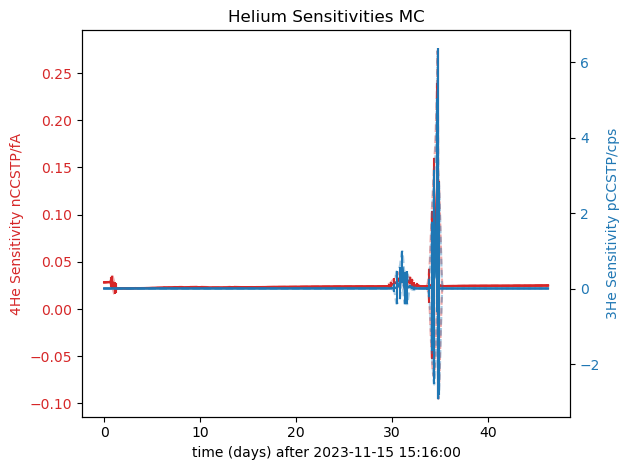

Assuming all standards analyzed had 157.5 nCCSTP 4He and 3.57 pCCSTP 3He


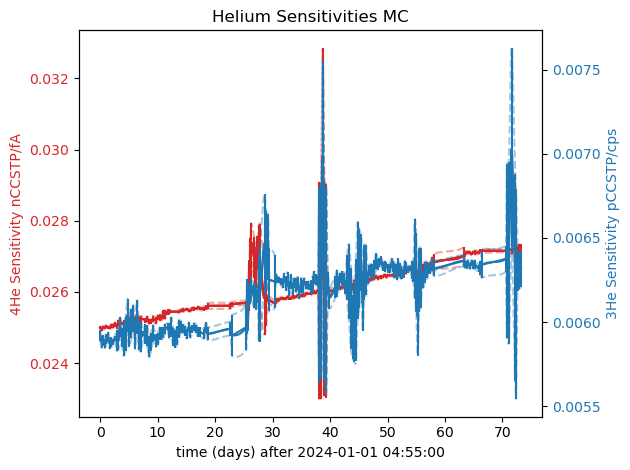

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import pandas as pd
import scipy
import os
from datetime import datetime


Rcal= 1.987
def swets(L,T):
    """Returns Permeability, diffusivity, or solubility
    of fused Silica in units: mol/cm/s/atm for a given T in Kelvin"""
    if T >= 600:
        DEa = 6613 # factor of 4 to convert from g Helium to moles
        SEa = -1174
        DFF = 7.40E-4
        SFF = 1.28E17
    else:
        DEa = 5580
        SEa = -680
        DFF = 3.04E-4
        SFF = 1.99E17
    D = DFF*np.exp(-DEa/(Rcal*T))
    if L.upper() == 'D':
        return D
    S = SFF*np.exp(-SEa/(Rcal*T)) # K units: atom/cm/s/dP atm/
    if L.upper() == 'S':
        return S
    #print(f"Solubility at T = {T-273}C: {S} atoms/cm3/atm")
    #print(f"Diffusivity at T = {T-273}C: {D} cm2/s")
    #print(f"Permeation at T = {T-273}C in mol/cm/s/atm: {D*S}")
    K = D*S#/6.022E23 #units: mol/cm/s/atm
    if L.upper() == 'K':
        return K
    else:
        raise Exception("function is swets(L,T) where L is one of [D,S,K] for:\nDiffusivity, Solubility, and Permeability")
swets('K', 298)

def make_grid(minors = True):
    x_texts = ax.get_xticklabels()[1:-1]
    y_texts = ax.get_yticklabels()[1:-1]
    x_coords = []
    y_coords = []
    ylim = ax.get_ylim()
    xlim = ax.get_xlim()
    for xt in x_texts:
        x_coords.append(xt.get_position()[0])
    for yt in y_texts:
        y_coords.append(yt.get_position()[1])
    if minors:
        x_minors = ax.get_xticks(minor = True)
        y_minors = ax.get_yticks(minor = True)
        plt.vlines(x_minors, *ylim,linestyle = '-',color='Black', alpha = 0.05)
        plt.hlines(y_minors, *xlim,linestyle = '-',color='Black', alpha = 0.05)
    plt.vlines(x_coords, *ylim,linestyle = '--',color='Black', alpha = 0.2)
    plt.hlines(y_coords, *xlim,linestyle = '--',color='Black', alpha = 0.2)
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    
def InvertFrequencyFactor(t, F, Fp): 
    """
    Time in Seconds, F: Cumulative yield of 1, Fp: previous cumulative yield
    EQN 5a-c from Fechtig and Kalbitzer, 1966
    """
    
    if F <= 0.1:
        D_a2 = ((F**2 - Fp**2)*np.pi) / (36*t)
    elif F < 0.9:
        D_a2 = (1/(np.pi**2*t)) * (   (((-(np.pi**2)/3) * (F - Fp))) + ( (-2*np.pi)* (((1-((np.pi/3)*F))**0.5) - ((1-((np.pi/3))*Fp)**0.5) )  )    ) 
    elif F <= 1:
        D_a2 = (1/(np.pi**2*t)) * np.log( (1-Fp)/(1-F) )
    else:
        raise ValueError('Let F be fractional yield, within 0-1')
    return D_a2      

def InvertFrequencyFactor1(ts, Fs): 
    """
    Time in Seconds, F: Cumulative yield of 1, Fp: previous cumulative yield
    EQN 5a-c from Fechtig and Kalbitzer, 1966
    """
    
    Fs = np.array(Fs)
    
    Fps = np.array([0] + Fs[:-1].tolist())
    Fs = np.array(Fs)
    D_a2L = []
    
    for i, F in enumerate(Fs):
        Fp = Fps[i]
        t = ts[i]
        if F <= 0.1:
            D_a2 = ((F**2 - Fp**2)*np.pi) / (36*t)
        elif F < 0.9:
            D_a2 = (1/(np.pi**2*t)) * (   (((-(np.pi**2)/3) * (F - Fp))) + ( (-2*np.pi)* (((1-((np.pi/3)*F))**0.5) - ((1-((np.pi/3))*Fp)**0.5) )  )    ) 
        elif F <= 1:
            D_a2 = (1/(np.pi**2*t)) * np.log( (1-Fp)/(1-F) )
        else:
            raise ValueError('Let F be fractional yield, within 0-1')
        D_a2L.append(D_a2)
        
    return D_a2L

def Forward_Diffuse(Dt_a2):
    """Input is cumulative Dt_a2. 
    Equations 4a-c Fechtig and Kalbitzer, 1966"""
    
    Bt = (np.pi**2) * Dt_a2
    
    F = (6/(np.pi**(3/2))) * (Bt**(1/2)) # Small Yield Approx
    if F > 0.1:
        F = 1 - ((6/(np.pi**2)) * np.exp(-Bt)) # High Yield Approx
    if F < 0.9:
        F =(6/(np.pi**(3/2))) * (Bt**(1/2)) - ((3/(np.pi**2)) * Bt) # Mid-Yield Approx
        
    return F

def Simulate_Diffusion(D0_a2, Ea, T, t, R = 8.314):
    """Let T and t be 1D arrays of equal length describing sequential time-temperature steps,
    T in Celcius and t in minutes
    Let D0_a2 be sec^-1
    Default activation energy units are joules/mol, but R can be changed to match other energy units"""
    if np.shape(T) != np.shape(t) or T.ndim != 1:
        raise ValueError('Let T and t be 1D arrays of equal length describing sequential time-temperature steps')
    
    Dt_a2 = 0
    Fcum = []
    seconds = t*60 # minutes to seconds
    for i, sec in enumerate(seconds):
        K = 273+T[i]
        Dt_a2 +=  ((D0_a2 * np.exp(-Ea/(R*K)) * sec))
        Fcum.append(Forward_Diffuse(Dt_a2))

    return Fcum
    
def Simulate_MDD_diffusion(D0, Ea, T, t, a, v, R = 8.314):
    """Let T and t be 1D arrays of equal length describing sequential time-temperature steps,
    T in Celcius and t in minutes
    Let a and v be 1D arrays of equal length where 
    'a' describes grain sizes (radii) in centimeters and 
    'v' describes the relative volume of the corresponding grain sizes, forced to sum to 1 by the program
    Let D_0 be cm^2/sec
    Default activation energy units are joules/mol, but R can be changed to match other energy units"""
                   
    if np.shape(a) != np.shape(v) or a.ndim != 1:
        raise ValueError('Let a and v be 1D arrays of equal length where a is radii in microns and v is the relative volume of the corresponding grain size')
    if np.shape(T) != np.shape(t) or T.ndim != 1:
        raise ValueError('Let T and t be 1D arrays of equal length describing sequential time-temperature steps')

    old_sum = np.sum(v)
    if old_sum != 1:
        v_new = v/old_sum
        print(f"v sums to {old_sum}, so it has been readjusted to sum to 1, now: {v_new}")
    else:
        v_new = v
    Fcum_array = np.zeros((np.shape(T)[0], np.shape(a)[0]))
    D0_a2 = D0/(a**2)
                   
    for column, domain in enumerate(D0_a2): # Simulate each respective domain
        Fcum_array[:,column] = np.array(Simulate_Diffusion(domain, Ea, T, t, R))

    Ftot = np.sum(Fcum_array * v_new.reshape((1,np.shape(v)[0])), axis = 1)
    return Ftot

def GaussianPDF(sigma):
    return((1/(2*np.pi)) * np.exp( (-1/2)*(sigma**2) ))
    
def diffusion_reduction(HeVec, TimeSeconds, TempKelvin = None, newDiffName = 'manual_diffusion.csv'):

    """Requires vector of measured diffusant in arbitrary units and equal length vector of time in seconds. 
    If temperature given then it will be outputted and plotted in an arrhenius plot
    """

    total_yield = np.sum(HeVec)
    fcum = []
    Fp = 0
    DC_indices = []
    D_a2 = []
    lnD_a2 = []
    blank_corrected_yield = []
    
    for i, step_yield in enumerate(HeVec):
        F = Fp + (step_yield/total_yield)
        frequency_factor = InvertFrequencyFactor(t = TimeSeconds[i], F = F, Fp = Fp)
        D_a2.append(frequency_factor)
        lnD_a2.append(np.log(frequency_factor))
        blank_corrected_yield.append(step_yield)
        DC_indices.append(i)
        fcum.append(F)
        Fp = F

    if np.sum(TempKelvin):
        data = [(TempKelvin-273).tolist(), (TimeSeconds/60).tolist(), HeVec, fcum, D_a2, lnD_a2, (10000/TempKelvin).tolist()]
        columns = ['Temp (C)', 'Time (min)', 'He Yield (nCC@STP)', 'Fcum', 'D/a^2 ', 'ln(D/a^2)', '10^4/T']
        
        #Plotting...
        min_T = np.min(10000/TempKelvin[:-1])
        max_T = np.max(10000/TempKelvin[:-1])
        plt.plot(10000/TempKelvin[:-1], np.array(lnD_a2)[:-1], linestyle='--', marker='o', color='b', label = 'Simulated Encapsulated Apatite')
        plt.title(f"Diffusivity Inversion for Total Yield = {total_yield} ncc's")


        reference_D0_a2 = [(10**1.5)/((150/10000)**2), (10**1.5)/((250/10000)**2), np.exp(1.1939)] # /sec
        reference_Ea = [33000, 33000, 14701*1.987] # cal /mol



        reference_names = ['True Diffusivity of Apatite (a=150 um)', 'DApB 250 um', 'pyrite']
        R = 1.98 #cal /mol /T(K)

        first_only = True
        if len(reference_D0_a2) > 0 and len(reference_D0_a2) == len(reference_Ea):
            T = [min_T, max_T]
            for i, D0_a2 in enumerate(reference_D0_a2):
                if first_only:
                    Ea = reference_Ea[i]
                    min_log_frequency_factor = np.log(D0_a2*np.exp(-Ea/((10000*(min_T**-1))*R)))
                    max_log_frequency_factor = np.log(D0_a2*np.exp(-Ea/((10000*(max_T**-1))*R)))
                    plt.plot(T, [min_log_frequency_factor, max_log_frequency_factor], label = reference_names[i])
                    first_only = False
        #plt.show()

    else:
        data = [(TimeSeconds/60).tolist(), HeVec, fcum, D_a2, lnD_a2]
        columns = ['Time (min)', 'He Yield (nCC@STP)', 'Fcum', 'D/a^2 ', 'ln(D/a^2)']

    Reduced_Data = pd.DataFrame()
    for i, column in enumerate(columns):
        Reduced_Data[column] = data[i]
    Reduced_Data.to_csv(newDiffName)
    print(f"Done! Output file: {newDiffName} in {os.getcwd()}")
    return Reduced_Data

Ratoms = 1.3621E-22
Rcal = 1.987

def swets_K(T):
    """Returns Permeability of fused Silica in units: mol/cm/s/atm for a given T in Kelvin"""
    if T >= 600:
        DEa = 6613 # factor of 4 to convert from g Helium to moles
        SEa = -1174
        DFF = 7.40E-4
        SFF = 1.28E17
    else:
        DEa = 5580
        SEa = -680
        DFF = 3.04E-4
        SFF = 1.99E17
        
    D = DFF*np.exp(-DEa/(Rcal*T))
    S = SFF*np.exp(-SEa/(Rcal*T)) # K units: atom/cm/s/dP atm/
    #print(f"Solubility at T = {T-273}C: {S} atoms/cm3/atm")
    #print(f"Diffusivity at T = {T-273}C: {D} cm2/s")
    #print(f"Permeation at T = {T-273}C in mol/cm/s/atm: {D*S}")
    K = D*S#/6.022E23 #units: mol/cm/s/atm
    return K

def tube_permeate2(T, t, ID, OD):
    """Lengths in cm. Inner and outer diameter. F is fraction initial He remaining. 
    Returns n/n0, fraction of initial Helium"""
    K = swets_K(T)
    return(np.exp(-(K*Ratoms*T*2*t)/(np.log(OD/ID)*((ID/2)**2))))

def Forward_Diffuse_deriv(t, D, a):
    """Input is cumulative Dt_a2. 
    Equations 4a-c Fechtig and Kalbitzer, 1966"""
    
    Bt = (np.pi**2) * D * t/(a**2)
    
    F = (6/(np.pi**(3/2))) * (Bt**(1/2)) # Small Yield Approx
    dfdt = (6/(np.pi**(3/2))) * (1/2) * (t**(-1/2)) * (((np.pi**2) * D/(a**2))**(1/2))
    
    if F > 0.1:
        F = 1 - ((6/(np.pi**2)) * np.exp(-Bt)) # High Yield Approx
        dfdt = ((6/(np.pi**2)) * np.exp(-Bt)) # High Yield Approx
    if F < 0.9:
        F =(6/(np.pi**(3/2))) * (Bt**(1/2)) - ((3/(np.pi**2)) * Bt) # Mid-Yield Approx
        dfdt = ((6/(np.pi**(3/2))) * (1/2) * (t**(-1/2)) * (((np.pi**2) * D/(a**2))**(1/2))) - ((np.pi**2) * D/(a**2))
    return F, dfdt

    
#sigma = np.linspace(-500,500,201)/100
#plt.plot(sigma, GaussianPDF(sigma)/len(sigma))

def FirstOrdInversion(t, He, plot = False):
    """Returns n0 and lambda for a time series of evolving gas following a first order law"""
    cumHe = accumulate(He)
    cumt = accumulate(t)
    lamb = 6E-6 # order of magnitude estimation
    
    longt = np.linspace(0,cumt[-1],500)
    
    (out,covmat) = scipy.optimize.curve_fit(f = forward_permeate, xdata = cumt, ydata = cumHe, p0 = [lamb, 1])#He[0]/(1-np.exp(-lamb*t[0]))])
    if plot:
        plt.plot(longt, forward_permeate(longt, out[0], out[1]))
        plt.scatter(cumt, cumHe)
    return (out[0],out[1])

def accumulate(v):
    vnew = [v[0]]
    for vnext in v[1:]:
        vnew.append(vnext+vnew[-1])
    return np.array(vnew)

def forward_permeate(t, lamb, n0):
    return(n0*(1-np.exp(-lamb*t)))

def Jones(L, T):
    if L.upper() == "K":
        return 1.17*np.exp(-57/(1.987*T))
    if L.upper() == "S":
        return 1.003*np.exp(-6/(1.987*T))
    if L.upper() == "D":
        return 1.167*np.exp(-51/(1.987*T))
    
def pull_number(string):
    """Pulls workable numbers from a string"""
    assert isinstance(string, str), 'Only a single string accepted'
    number_string = str('')
    for letter in string:
        if letter in '1234567890.':
            number_string += letter
    return float(number_string)

def extract_times_from0(dates, form = '%m/%d/%Y  %I:%M %p'):
    """Extracts exact times from first anaysis using timestamps on MC"""
    times = [] # in seconds
    first = True
    for stri in dates: 
        try:
            time = datetime.strptime(stri, form)
        except:
            try:
                form = '%m/%d/%Y  %H:%M:%S'
                time = datetime.strptime(stri, form)
            except:
                try:
                    form = '%m/%d/%Y  %H:%M'
                    time = datetime.strptime(stri, form)
                except:
                    form = '%m/%d/%Y  %I:%M:%S %p'
                    time = datetime.strptime(stri, form)
        if first:
            firsttime = time
            first = False
        else:
            newtime = time
            times.append((newtime - firsttime).total_seconds())
    return np.array(times)

class MCHeReducer:
    """A Machine that maps signals on the MC to abundances, 
    trained on standards which are assumed to have constant abundances
    Time must be formatted as such:
    '%m/%d/%Y  %I:%M %p'
    see   https://docs.python.org/3/library/datetime.html  if confused
    Sometimes excel changes the date-time format if you edit it. The default output for the MC is used here for analyses.
    """
    def __init__(self, STD_name, form = '%m/%d/%Y  %I:%M %p'):
        self.std = pd.read_csv(STD_name, header=None).to_numpy()
        self.STD4 = 157.50 #nccSTP
        self.STD3 = 3.57 #pccSTP
        print(f"Assuming all standards analyzed had {self.STD4} nCCSTP 4He and {self.STD3} pCCSTP 3He")
        self.exist_ID = []
        self.clean_standard_rows = [] #remove redundant analyses
        for z, std in enumerate(self.std):
            if std[0] not in self.exist_ID:
                self.exist_ID.append(std[0])
                self.clean_standard_rows.append(z)
        #print(self.clean_standard_rows)
        self.std = self.std[self.clean_standard_rows]
        
        try:
            self.t0 = datetime.strptime(self.std[0,2], form)
        except:
            try:
                form = '%m/%d/%Y  %H:%M:%S'
                self.t0 = datetime.strptime(self.std[0,2], form)
            except:
                try:
                    form = '%m/%d/%Y  %H:%M'
                    self.t0 = datetime.strptime(self.std[0,2], form)
                except:
                    form = '%m/%d/%Y  %I:%M:%S %p'
                    self.t0 = datetime.strptime(self.std[0,2], form)
        #self.t0 = datetime.strptime(self.std[0,2], form) # save t0
        self.Dt = np.append(0,extract_times_from0(self.std[:,2])) # map time as seconds after t0
        self.std = self.std[np.argsort(self.Dt)]
        self.Dt = np.sort(self.Dt)
        self.sigma4 = []
        self.sigma3 = []
        #print(self.Dt)
        self.sens4 = self.STD4/self.std[:,6]
        self.sens3 = self.STD3/self.std[:,4]
        self.x = np.linspace(0, self.Dt[-1], 2000)
        self.inds = np.arange(len(self.sens4))
        for i in self.inds:
             self.sigma4.append(np.std(self.sens4[np.argsort(np.abs(self.inds-i))][:5])) # Uncertainty estimated as standard deviation of 5 sensitivity measurements. 2 before, 2 after. Only internal reproducibility handled here
             self.sigma3.append(np.std(self.sens3[np.argsort(np.abs(self.inds-i))][:5])) # Uncertainty estimated as standard deviation of 5 sensitivity measurements. 2 before, 2 after. Only internal reproducibility handled here
        self.model4 = scipy.interpolate.pchip_interpolate(self.Dt, self.sens4, self.x) 
        self.model3 = scipy.interpolate.pchip_interpolate(self.Dt, self.sens3, self.x) 
        self.model4sigma = scipy.interpolate.pchip_interpolate(self.Dt, np.array(self.sigma4), self.x)              
        self.model3sigma = scipy.interpolate.pchip_interpolate(self.Dt, np.array(self.sigma3), self.x) 
                                
    def saveSTDs(self, name):
        pd.DataFrame(self.std).to_csv(name)
        
    def plot(self):
        fig, ax1 = plt.subplots()
        
        self.color = 'tab:red'
        ax1.set_xlabel(f'time (days) after {self.t0}')
        ax1.set_ylabel('4He Sensitivity nCCSTP/fA', color=self.color)
        ax1.plot(self.x/(3600*24), self.model4, color=self.color)
        ax1.plot(self.x/(3600*24), self.model4+(2*self.model4sigma), alpha = 0.4, linestyle = '--', color=self.color)
        ax1.plot(self.x/(3600*24), self.model4-(2*self.model4sigma), alpha = 0.4, linestyle = '--', color=self.color)
        ax1.plot(self.x/(3600*24), self.model4, color=self.color)
        #ax1.scatter(self.Dt/(3600*24), self.sens4, color = self.color)
        ax1.errorbar(self.Dt/(3600*24), self.sens4, yerr = 2*np.array(self.sigma4), linestyle = None, color = self.color)
        ax1.tick_params(axis='y', labelcolor=self.color)

        ax2 = ax1.twinx() 
        self.color = 'tab:blue'
        ax2.set_ylabel('3He Sensitivity pCCSTP/cps', color=self.color)  # we already handled the x-label with ax1
        ax2.plot(self.x/(3600*24), self.model3, color=self.color)
        ax2.plot(self.x/(3600*24), self.model3+(2*self.model3sigma), alpha = 0.4, linestyle = '--', color=self.color)
        ax2.plot(self.x/(3600*24), self.model3-(2*self.model3sigma), alpha = 0.4, linestyle = '--', color=self.color)
        #ax2.scatter(self.Dt/(3600*24), self.sens3, color = self.color)
        ax2.errorbar(self.Dt/(3600*24), self.sens3, yerr = 2*np.array(self.sigma3), linestyle = None, color = self.color)
        ax2.tick_params(axis='y', labelcolor=self.color)
        
        plt.title('Helium Sensitivities MC')
        fig.tight_layout()  # otherwise the right y-label is slightly clipped
        plt.savefig('SensitivitiesHeMC.jpg', dpi = 256)
        plt.show()
        
    def reduce(self, DIFFCELL, form = '%m/%d/%Y  %I:%M %p', plot = False, sens_out = False, uncertainties = False):
        #self.analyses = pd.read_csv(Anal_name, header=None).to_numpy()
        self.analyses = DIFFCELL
        self.AnalDT = extract_times_from0(np.append(self.t0.strftime(form), self.analyses[:,2]), form = form)
        self.sensIND = []
        for tim in self.AnalDT:
            winner = np.argmin(np.abs(self.x-tim))
            #print(winner)
            self.sensIND.append(winner)
        self.sensIND = np.array(self.sensIND)
        self.Anal3He = (self.model3[self.sensIND]*self.analyses[:,4]).astype('float')
        self.Anal4He = self.model4[self.sensIND]*self.analyses[:,6].astype('float')
        if plot:
            fig, ax1 = plt.subplots()
            self.STDreltimes = (self.Dt > (min(self.AnalDT)-(3600*24))) * (self.Dt < (max(self.AnalDT)+(3600*24)))
            self.modelreltimes = (self.x > (min(self.AnalDT)-(3600*24))) * (self.x < (max(self.AnalDT)+(3600*24)))
            self.color = 'tab:red'
            ax1.set_xlabel(f'time (days) after {self.t0}')
            ax1.set_ylabel('4He Sensitivity nCCSTP/fA', color=self.color)
            ax1.plot(self.x[self.modelreltimes]/(3600*24), self.model4[self.modelreltimes], color=self.color)
            ax1.scatter(self.Dt[self.STDreltimes]/(3600*24), self.sens4[self.STDreltimes], color = self.color, label = 'Measured 4He Sensitivity')
            ax1.errorbar(self.Dt[self.STDreltimes]/(3600*24), self.sens4[self.STDreltimes], yerr = 2*np.array(self.sigma4)[self.STDreltimes], color = self.color, alpha = 0.5, linestyle = '')
            ax1.plot(self.x[self.modelreltimes]/(3600*24), self.model4[self.modelreltimes]+(2*self.model4sigma[self.modelreltimes]), alpha = 0.4, linestyle = '--', color=self.color)
            ax1.plot(self.x[self.modelreltimes]/(3600*24), self.model4[self.modelreltimes]-(2*self.model4sigma[self.modelreltimes]), alpha = 0.4, linestyle = '--', color=self.color)
            ax1.scatter(self.AnalDT/(3600*24), self.model4[self.sensIND], s = 20, marker = 'x', color = 'k', label = 'Interpolated In-run 4He Sensitivity')
            ax1.errorbar(self.AnalDT/(3600*24), self.model4[self.sensIND], yerr = 2*np.array(self.model4sigma[self.sensIND]), color = 'grey', alpha = 0.4, linestyle='')
            
            ax1.tick_params(axis='y', labelcolor=self.color)
            ax1.legend(loc = 'upper right', fontsize = 'small')
            
            ax2 = ax1.twinx() 
            self.color = 'tab:blue'
            ax2.set_ylabel('3He Sensitivity pCCSTP/cps', color=self.color)  # we already handled the x-label with ax1
            ax2.plot(self.x[self.modelreltimes]/(3600*24), self.model3[self.modelreltimes], color=self.color)
            ax2.scatter(self.Dt[self.STDreltimes]/(3600*24), self.sens3[self.STDreltimes], color = self.color, label = 'Measured 3He Sensitivity')
            ax2.errorbar(self.Dt[self.STDreltimes]/(3600*24), self.sens3[self.STDreltimes], yerr = 2*np.array(self.sigma3)[self.STDreltimes], color = self.color, alpha = 0.5, linestyle = '')
            ax2.plot(self.x[self.modelreltimes]/(3600*24), self.model3[self.modelreltimes]+(2*self.model3sigma[self.modelreltimes]), alpha = 0.4, linestyle = '--', color=self.color)
            ax2.plot(self.x[self.modelreltimes]/(3600*24), self.model3[self.modelreltimes]-(2*self.model3sigma[self.modelreltimes]), alpha = 0.4, linestyle = '--', color=self.color)
            ax2.scatter(self.AnalDT/(3600*24), self.model3[self.sensIND], s = 25, marker = '+', color = 'k', label = 'Interpolated In-run 3He Sensitivity')
            ax2.errorbar(self.AnalDT/(3600*24), self.model3[self.sensIND], yerr = 2*np.array(self.model3sigma[self.sensIND]), color = 'grey', alpha = 0.4, linestyle = '')
            ax2.tick_params(axis='y', labelcolor=self.color)
            
            #plt.xlim((min(self.AnalDT/(3600*24)) -1, max(self.AnalDT/(3600*24)) + 1))
            ax2.legend(loc='lower right', fontsize = 'small')#
            plt.title('Helium Sensitivities MC')
            fig.tight_layout()  # otherwise the right y-label is slightly clipped
            plt.savefig('interpSensitivitiesHeMC.jpg', dpi = 256)
        
        outlist = [self.Anal3He, self.Anal4He]
        if uncertainties:
            outlist += [self.Anal3He*(self.model3sigma[self.sensIND]/self.model3[self.sensIND]), self.Anal4He*(self.model4sigma[self.sensIND]/self.model4[self.sensIND])]
        if sens_out:
            outlist += [self.model3[self.sensIND], self.model4[self.sensIND]]
            #return ((self.Anal3He, self.Anal4He), (self.model3[self.sensIND], self.model4[self.sensIND]))
        return outlist
    
    
reducer = MCHeReducer('STD_nov.csv')
reducer.plot()

    
    
reducer = MCHeReducer('2024STDsMC.csv')
reducer.plot()


0.0006479534848028949

1.	Look up the He diffusion parameters for quartz given by Shuster and Farley 2005. Compute the amount of He released from quartz of the grain size used in that paper for a heating schedule of one hour steps from 100 to 500 C in 25 degree steps. Be careful with units for diffusion parameters and for temperature.  Save the results.

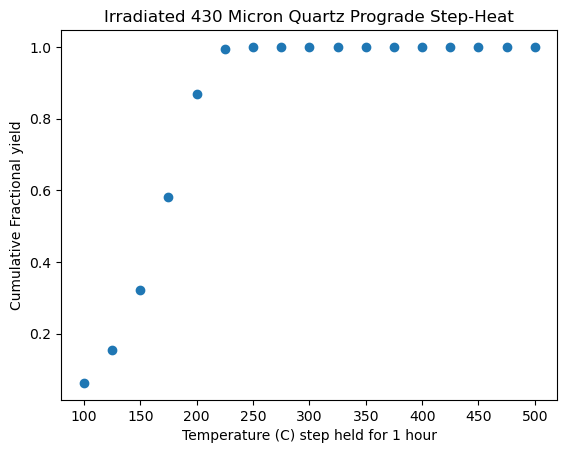

In [4]:
"""Diffusion Parameters for 3He in a 430 micron quartz crystal, Taken from Shuster and Farley, 2005"""

Ea = 84500 #J/mol
D0_a2 = np.exp(11.1) #s^-1

T = np.arange(100, 525, 25) # C
t = np.ones_like(T)*60 #minutes

Fcum_Qz430 = Simulate_Diffusion(D0_a2, Ea, T, t)
plt.scatter(T,Fcum_Qz430);
plt.title('Irradiated 430 Micron Quartz Prograde Step-Heat');
plt.xlabel('Temperature (C) step held for 1 hour');
plt.ylabel('Cumulative Fractional yield');

2.	Recompute for a grain size 100 times larger. (i.e., scale a up by 100). save the results.

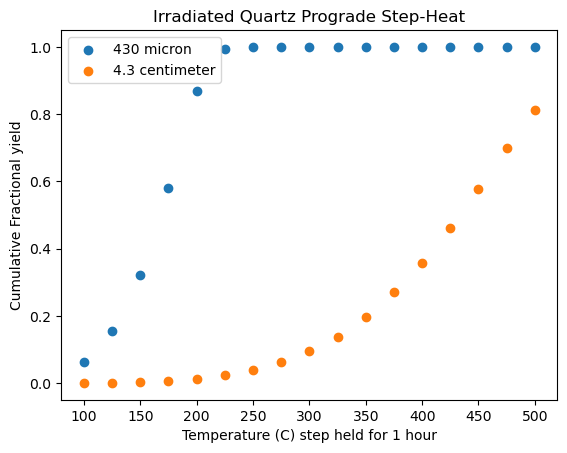

In [5]:
a = 430 #micron
D0 = D0_a2 * ((a/1E4)**2) # cm^2/sec
Fcum_Qz4cm = Simulate_Diffusion(D0/(((a/1E4)*100)**2), Ea, T, t)
plt.scatter(T,Fcum_Qz430, label = '430 micron');
plt.scatter(T,Fcum_Qz4cm, label = '4.3 centimeter');
plt.legend();
plt.title('Irradiated Quartz Prograde Step-Heat');
plt.xlabel('Temperature (C) step held for 1 hour');
plt.ylabel('Cumulative Fractional yield');

3.	Take the saved data for each, and use the fractional yield data to compute diffusion coeffs for each step. Plot both grain size data sets on an arrhenius plot. make sure you understand why they are offset from each other by exactly the amount they are.

C:\Users\dashf\AppData\Local\Temp\ipykernel_26224\2467196119.py:17: RuntimeWarning: divide by zero encountered in scalar divide
  D_a2 = (1/(np.pi**2*t)) * np.log( (1-Fp)/(1-F) )
C:\Users\dashf\AppData\Local\Temp\ipykernel_26224\2467196119.py:17: RuntimeWarning: invalid value encountered in scalar divide
  D_a2 = (1/(np.pi**2*t)) * np.log( (1-Fp)/(1-F) )


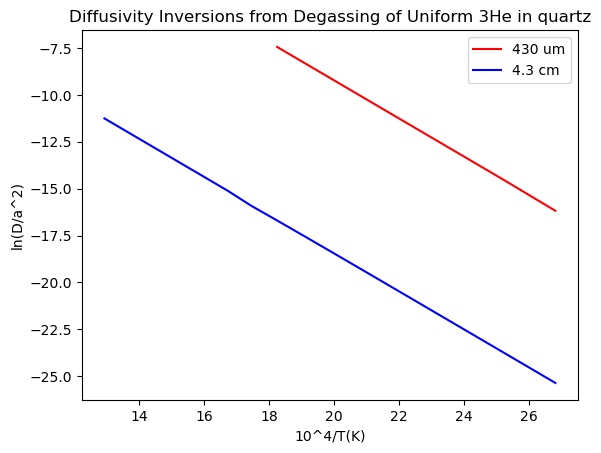

In [6]:
D_a2_qz430um = []
D_a2_qz4cm = []
Fp430 = 0
Fp4cm = 0

for i in range(len(Fcum_Qz430)):
    F430 = Fcum_Qz430[i]
    F4cm = Fcum_Qz4cm[i]
    D_a2_qz430um.append(InvertFrequencyFactor(F = F430, Fp = Fp430, t = t[0]*60)) # Takes time in seconds
    D_a2_qz4cm.append(InvertFrequencyFactor(F = F4cm, Fp = Fp4cm, t = t[0]*60))
    Fp430 = F430
    Fp4cm = F4cm


Inv_Temp = 1E4/(T + 273)
plt.plot(Inv_Temp, np.log(np.array(D_a2_qz430um)), 'r', label = '430 um');
plt.plot(Inv_Temp, np.log(np.array(D_a2_qz4cm)), 'b', label = '4.3 cm');
plt.xlabel('10^4/T(K)');
plt.ylabel('ln(D/a^2)');
plt.legend()
plt.title('Diffusivity Inversions from Degassing of Uniform 3He in quartz');

Diffusivity is an intensive material property and thus does not vary as a function of diffusivity domain size. 

In natural log space, the diffusivity difference of two diffusion domains of the same material at constant temperature can be expressed as follows:

$$ ln\left(\frac{D}{a_1^2}\right) - ln\left(\frac{D}{a_2^2}\right) = lna_2^2 -lna_1^2$$


    
I verify my results below. There is some amount of variable, very small errors in the approximations made by Fechtig and Kalbiter, 1966, thus I have take the mean of the difference in diffusivity inversions that were available before the 430 micron quartz runs out of gas.

In [7]:
a1 = 0.043 #430 micron
a2 = 4.3 #cm
print(f"Expected Diffusivity difference: {np.log(a2**2) - np.log(a1**2)} \nSimulated Diffusivity difference: {np.mean((np.log(np.array(D_a2_qz430um)) - np.log(np.array(D_a2_qz4cm)))[:6])}")

Expected Diffusivity difference: 9.210340371976184 
Simulated Diffusivity difference: 9.210171407753341


4.	Now simulate a multidomain system that consists of 9 parts of the small grain size and one part of the large grain size by combining your computations in parts 1 and 2 above in appropraite proportions and normalizing the yield. Compute diffusion coefficients from this combined system, and plot with results in step 3. Study the resulting profile until you have a good intuitive feel for it. 

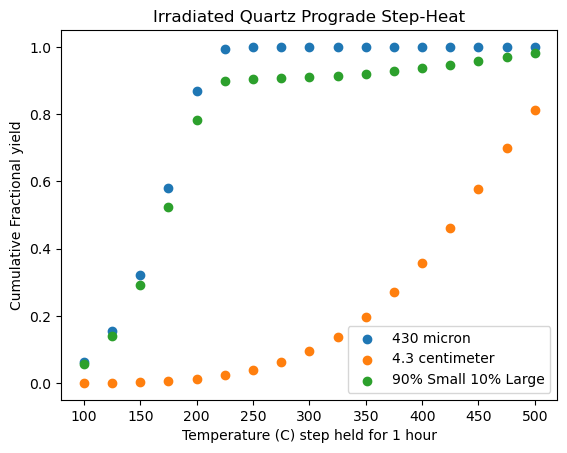

In [8]:
v = np.array([0.9,0.1]) # Parts
a = np.array([a1, a2]) # Radii in centimeters

Fcum_MDD = Simulate_MDD_diffusion(D0 = D0, Ea = Ea, v = v, a = a, T = T, t = t)
plt.scatter(T,Fcum_Qz430, label = '430 micron');
plt.scatter(T,Fcum_Qz4cm, label = '4.3 centimeter');
plt.scatter(T,Fcum_MDD, label = '90% Small 10% Large');
plt.legend();
plt.title('Irradiated Quartz Prograde Step-Heat');
plt.xlabel('Temperature (C) step held for 1 hour');
plt.ylabel('Cumulative Fractional yield');

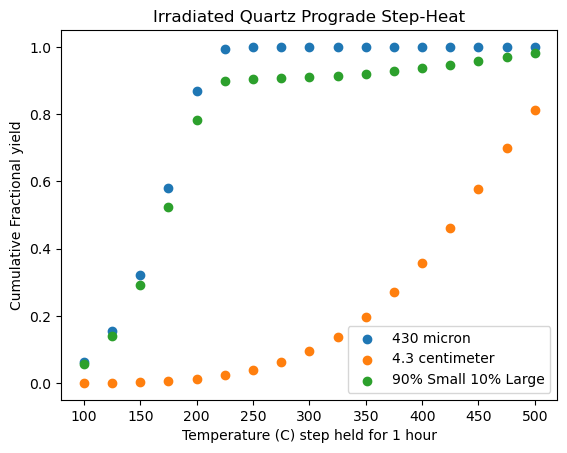

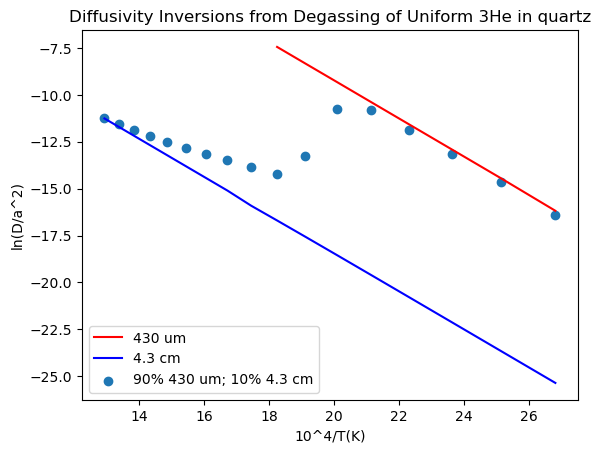

In [9]:
D_MDD = []
FpMDD = 0

v = np.array([0.9,0.1]) # Parts
a = np.array([a1, a2]) # Radii in centimeters

Fcum_MDD = Simulate_MDD_diffusion(D0 = D0, Ea = Ea, v = v, a = a, T = T, t = t)
plt.scatter(T,Fcum_Qz430, label = '430 micron');
plt.scatter(T,Fcum_Qz4cm, label = '4.3 centimeter');
plt.scatter(T,Fcum_MDD, label = '90% Small 10% Large');
plt.legend();
plt.title('Irradiated Quartz Prograde Step-Heat');
plt.xlabel('Temperature (C) step held for 1 hour');
plt.ylabel('Cumulative Fractional yield');
plt.show()

for i in range(len(Fcum_MDD)):
    FMDD = Fcum_MDD[i]
    D_MDD.append(InvertFrequencyFactor(F = FMDD, Fp = FpMDD, t = t[0]*60)) # Takes time in seconds
    FpMDD = FMDD

plt.plot(Inv_Temp, np.log(np.array(D_a2_qz430um)), 'r', label = '430 um');
plt.plot(Inv_Temp, np.log(np.array(D_a2_qz4cm)), 'b', label = '4.3 cm')
plt.scatter(Inv_Temp, np.log(np.array(D_MDD)), label = '90% 430 um; 10% 4.3 cm')
plt.xlabel('10^4/T(K)');
plt.ylabel('ln(D/a^2)');
plt.legend()
plt.title('Diffusivity Inversions from Degassing of Uniform 3He in quartz');
plt.show()

5.	 Now repeat the entire exercise using a cycled step heat in which you include a retrograde sequence of steps (i.e., declining temperature). Study the plot until you truly understand it.

<ipython-input-84-daaf8cd08a53>:15: RuntimeWarning: divide by zero encountered in double_scalars
  D_a2 = (1/(np.pi**2*t)) * np.log( (1-Fp)/(1-F) )
<ipython-input-84-daaf8cd08a53>:15: RuntimeWarning: invalid value encountered in double_scalars
  D_a2 = (1/(np.pi**2*t)) * np.log( (1-Fp)/(1-F) )


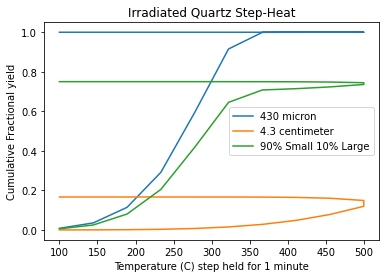

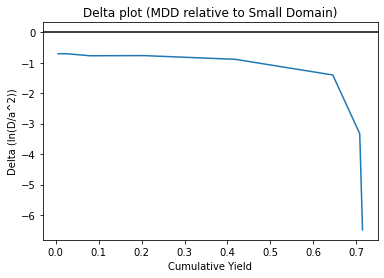

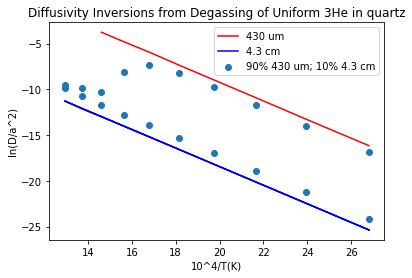

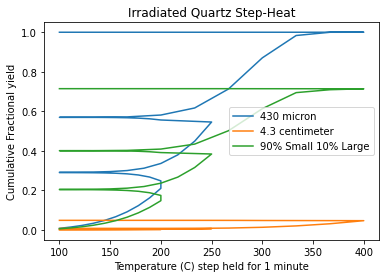

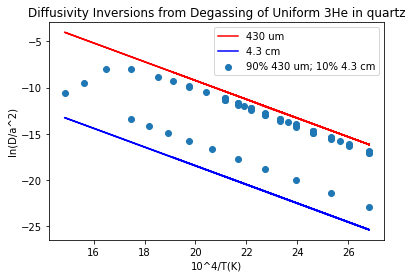

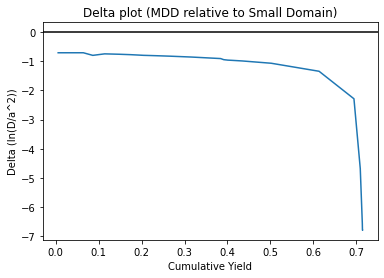

In [100]:
T = np.append(np.linspace(100,500, 10), np.linspace(500,100, 10))
#T = np.linspace(100,500,50)
t = np.ones_like(T*60) # 1 minutes
a = 430 #micron
D0 = D0_a2 * ((a/1E4)**2) # cm^2/sec
Fcum_Qz4cm = Simulate_Diffusion(D0/(((a/1E4)*100)**2), Ea, T, t)
Fcum_Qz430 = Simulate_Diffusion(D0_a2, Ea, T, t)

v = np.array([0.7,0.3]) # Parts
a = np.array([0.043, 4.3]) # Radii in centimeters
Fcum_MDD = Simulate_MDD_diffusion(D0 = D0, Ea = Ea, v = v, a = a, T = T, t = t)


D_a2_qz430um = []
D_a2_qz4cm = []
D_MDD = []
Fp430 = 0
Fp4cm = 0
FpMDD = 0


for i in range(len(Fcum_Qz430)):
    F430 = Fcum_Qz430[i]
    F4cm = Fcum_Qz4cm[i]
    D_a2_qz430um.append(InvertFrequencyFactor(F = F430, Fp = Fp430, t = t[0]*60)) # Takes time in seconds
    D_a2_qz4cm.append(InvertFrequencyFactor(F = F4cm, Fp = Fp4cm, t = t[0]*60))
    Fp430 = F430
    Fp4cm = F4cm
    FMDD = Fcum_MDD[i]
    D_MDD.append(InvertFrequencyFactor(F = FMDD, Fp = FpMDD, t = t[0]*60)) # Takes time in seconds
    FpMDD = FMDD

plt.plot(T,Fcum_Qz430, label = '430 micron');
plt.plot(T,Fcum_Qz4cm, label = '4.3 centimeter');
plt.plot(T,Fcum_MDD, label = '90% Small 10% Large');
plt.legend();
plt.title('Irradiated Quartz Step-Heat');
plt.xlabel('Temperature (C) step held for 1 minute');
plt.ylabel('Cumulative Fractional yield');
plt.show()

Delta1 = np.log(np.array(D_MDD)) - np.log(np.array(D_a2_qz430um))
plt.plot(Fcum_MDD,Delta1); 
plt.axhline(0, c = 'k')
plt.title('Delta plot (MDD relative to Small Domain)')
plt.ylabel('Delta (ln(D/a^2))');
plt.xlabel('Cumulative Yield')
plt.show()


Inv_Temp = 1E4/(T+273)
plt.plot(Inv_Temp, np.log(np.array(D_a2_qz430um)), 'r', label = '430 um');
plt.plot(Inv_Temp, np.log(np.array(D_a2_qz4cm)), 'b', label = '4.3 cm')
plt.scatter(Inv_Temp, np.log(np.array(D_MDD)), label = '90% 430 um; 10% 4.3 cm')
plt.xlabel('10^4/T(K)');
plt.ylabel('ln(D/a^2)');
plt.legend()
plt.title('Diffusivity Inversions from Degassing of Uniform 3He in quartz');
plt.show()

T = np.append(np.linspace(100,200, 10), np.linspace(200,100, 10))
for i in range(3):
    T = np.append(T, np.linspace(100,(100+(150*i)), 10))
    T = np.append(T, np.linspace((100+(100*i)), 100, 10))
t = np.ones_like(T) # 1 minutes
a = 430 #micron
D0 = D0_a2 * ((a/1E4)**2) # cm^2/sec
Fcum_Qz4cm = Simulate_Diffusion(D0/(((a/1E4)*100)**2), Ea, T, t)
Fcum_Qz430 = Simulate_Diffusion(D0_a2, Ea, T, t)

v = np.array([0.7,0.3]) # Parts
a = np.array([0.043, 4.3]) # Radii in centimeters
Fcum_MDD = Simulate_MDD_diffusion(D0 = D0, Ea = Ea, v = v, a = a, T = T, t = t)


D_a2_qz430um = []
D_a2_qz4cm = []
D_MDD = []
Fp430 = 0
Fp4cm = 0

FpMDD = 0


for i in range(len(Fcum_Qz430)):
    F430 = Fcum_Qz430[i]
    F4cm = Fcum_Qz4cm[i]
    D_a2_qz430um.append(InvertFrequencyFactor(F = F430, Fp = Fp430, t = t[0]*60)) # Takes time in seconds
    D_a2_qz4cm.append(InvertFrequencyFactor(F = F4cm, Fp = Fp4cm, t = t[0]*60))
    Fp430 = F430
    Fp4cm = F4cm
    FMDD = Fcum_MDD[i]
    D_MDD.append(InvertFrequencyFactor(F = FMDD, Fp = FpMDD, t = t[0]*60)) # Takes time in seconds
    FpMDD = FMDD

Delta2 = np.log(np.array(D_MDD)) - np.log(np.array(D_a2_qz430um))

plt.plot(T,Fcum_Qz430, label = '430 micron');
plt.plot(T,Fcum_Qz4cm, label = '4.3 centimeter');
plt.plot(T,Fcum_MDD, label = '90% Small 10% Large');
plt.legend();
plt.title('Irradiated Quartz Step-Heat');
plt.xlabel('Temperature (C) step held for 1 minute');
plt.ylabel('Cumulative Fractional yield');
plt.show()


Inv_Temp = 1E4/(T+273)
plt.plot(Inv_Temp, np.log(np.array(D_a2_qz430um)), 'r', label = '430 um');
plt.plot(Inv_Temp, np.log(np.array(D_a2_qz4cm)), 'b', label = '4.3 cm')
plt.scatter(Inv_Temp, np.log(np.array(D_MDD)), label = '90% 430 um; 10% 4.3 cm')
plt.xlabel('10^4/T(K)');
plt.ylabel('ln(D/a^2)');
plt.legend()
plt.title('Diffusivity Inversions from Degassing of Uniform 3He in quartz');
plt.show()


plt.plot(Fcum_MDD,Delta2); 
plt.axhline(0, c = 'k');
plt.title('Delta plot (MDD relative to Small Domain)');
plt.ylabel('Delta (ln(D/a^2))');
plt.xlabel('Cumulative Yield');


140
140
140


<ipython-input-84-daaf8cd08a53>:15: RuntimeWarning: divide by zero encountered in double_scalars
  D_a2 = (1/(np.pi**2*t)) * np.log( (1-Fp)/(1-F) )
<ipython-input-84-daaf8cd08a53>:15: RuntimeWarning: invalid value encountered in double_scalars
  D_a2 = (1/(np.pi**2*t)) * np.log( (1-Fp)/(1-F) )


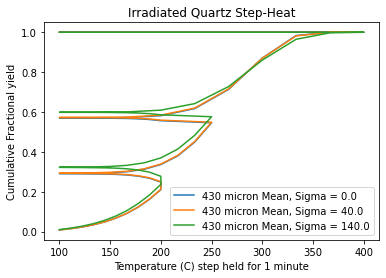

<ipython-input-101-64de882355eb>:44: RuntimeWarning: invalid value encountered in log
  y = np.log(np.array(DMDDs[i]))


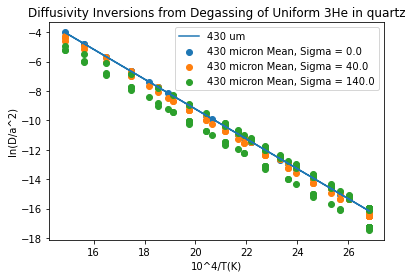

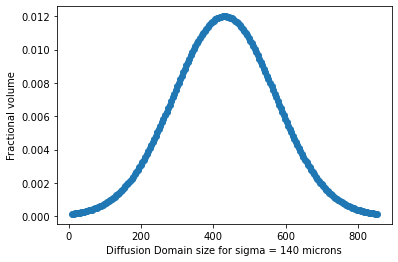

In [101]:
### T = np.append(np.linspace(100,200, 10), np.linspace(200,100, 10))
for i in range(3):
    T = np.append(T, np.linspace(100,(100+(150*i)), 10))
    T = np.append(T, np.linspace((100+(150*i)), 100, 10))
t = np.ones_like(T) # 1 minutes
a = 430 #micron
D0 = D0_a2 * ((a/1E4)**2) # cm^2/sec
#Fcum_Qz4cm = Simulate_Diffusion(D0/(((a/1E4)*100)**2), Ea, T, t)
Fcum_Qz430 = Simulate_Diffusion(D0_a2, Ea, T, t)

SD = np.array([0, 40, 140])*1E-4
v = GaussianPDF(np.linspace(-3,3,201))
v /= np.sum(v)

FMDDs = []
DMDDs = []
for sd in SD:
    a = np.linspace(0.043-(sd*3), 0.043+(sd*3),201)
    Fcum_MDD = Simulate_MDD_diffusion(D0 = D0, Ea = Ea, v = v, a = a, T = T, t = t)
    D_MDD = []
    for i in range(len(Fcum_MDD)):
        FMDD = Fcum_MDD[i]
        #print(len(Fcum_MDD[i]))
        D_MDD.append(InvertFrequencyFactor(F = FMDD, Fp = FpMDD, t = t[i]*60)) # Takes time in seconds
        
        FpMDD = FMDD
    print(len(D_MDD))
    FMDDs.append(Fcum_MDD)
    DMDDs.append(D_MDD)

for i, sd in enumerate(SD):
    plt.plot(T,FMDDs[i], label = f'430 micron Mean, Sigma = {sd*1E4}');
plt.legend();
plt.title('Irradiated Quartz Step-Heat');
plt.xlabel('Temperature (C) step held for 1 minute');
plt.ylabel('Cumulative Fractional yield');
plt.show()

R = 8.314
Inv_Temp = 1E4/(T+273)
cols = ['blue','orange','green']
for i, sd in enumerate(SD):
    x = Inv_Temp
    y = np.log(np.array(DMDDs[i]))
    u = -(np.append(np.array(x)[1:], 0) - x)
    ve = -(np.append(np.array(y)[1:], 0) - y)      
    #plt.quiver(x,y,u,ve, color = cols[i], label = f'430 micron Mean, Sigma = {sd*1E4}');
    plt.scatter(x,y,label = f'430 micron Mean, Sigma = {sd*1E4}')
real_D_a2_430 = (D0/((0.043**2))) * (np.exp(-(Ea*(Inv_Temp/1E4))/R))
real_D_a2_4cm = (D0/((4.3**2))) * (np.exp(-(Ea*(Inv_Temp/1E4))/R))
plt.plot(Inv_Temp, np.log(real_D_a2_430), label = '430 um')
#plt.scatter(Inv_Temp, np.log(np.array([DMDDs[0]])))
plt.xlabel('10^4/T(K)');
plt.ylabel('ln(D/a^2)');
plt.legend()
plt.title('Diffusivity Inversions from Degassing of Uniform 3He in quartz');
plt.show()

plt.scatter(a*1E4,v);
plt.xlabel('Diffusion Domain size for sigma = 140 microns');
plt.ylabel('Fractional volume');
plt.show()

In [161]:
real_D_a2_430 = (D0/((0.043**2))) * (np.exp(-(Ea*(Inv_Temp/1E4))/R))
real_D_a2_4cm = (D0/((4.3**2))) * (np.exp(-(Ea*(Inv_Temp/1E4))/R))

Delta = real_D_a2_430 - 

80

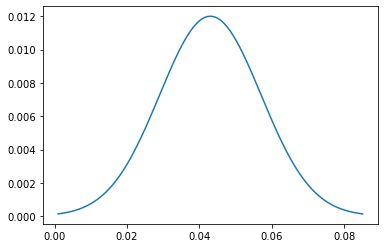

In [191]:
def Forward_SJM(k0, Ea, T, t, R = 8.314):
    """ Decribes first order Single Jump Model for atom migration in crystal, T in Celcius and t in seconds, k0 be sec^-1
    """
    if np.shape(T) != np.shape(t) or T.ndim != 1:
        raise ValueError('Let T and t be 1D arrays of equal length describing sequential time-temperature steps')
    F = [1]
    for i, sec in enumerate(t):
        K = T[i]+273
        d = k0*np.exp(-Ea/(R*K))
        F.append(F[-1]*np.exp(-d*sec))
    return F

Ea = 36000
k0 = 1.9E6
F_residual = np.array(Forward_SJM(Ea = Ea, k0 = k0, t = TimeSeconds, T = TempKelvin-273, R = 1.987))
Fcum = (1 - F_residual)*total_yield
released = Fcum[1:]-Fcum[:-1]
plt.xlabel('Heating Step')
plt.ylabel('He, ncc')
KCPY_degas = HenCC
plt.plot(released, label = 'Simulated SJM Degas')
plt.plot(Fcum, label = 'Simulated SJM Cumulative Degas')
plt.plot(np.array(fcum)*total_yield, label = 'Observed Cumulative KCPy ST05 Degas')
plt.plot(HenCC, label = 'Observed KCPy ST05 Degas')
plt.savefig(newDiffName+'SJM0'+'.svg')

plt.legend()
plt.show()
KCPYres_frac = (1-np.array(fcum))/np.append(0,(1-np.array(fcum)[:-1]))
res_frac = F_residual[1:]/F_residual[:-1]
y = np.log(np.log(1/res_frac)) - np.log(TimeSeconds)
y1 = np.log(np.log(1/KCPYres_frac)) - np.log(TimeSeconds)
x = 1/TempKelvin
plt.plot(x,y1, linestyle='--', marker='o',label = 'Observed KCPy First-Order Inversion')
plt.plot(x,y, linestyle='--', marker='o', label = 'Simulated SJM First-Order Inversion')
plt.legend()
ax2.set_xlim(ax1.get_xlim())
ax2.set_xticks(1/(Ctemps+273))
ax1.set_ylabel('lnln(He_0/He_t) - ln(t)')
ax2.set_xticklabels(Ctemps)
ax2.set_xlabel('Temperature (C)')
plt.savefig(newDiffName+'SJM'+'.svg')
plt.show()

plt.plot(10000/TempKelvin, np.array(lnD_a2), linestyle='--', marker='o', label = 'Observed KCPy')
Fp = 0
D_a2 = []
lnD_a2 = []
for i, He in enumerate(released):
    F = Fp + (He/total_yield)
    frequency_factor = InvertFrequencyFactor(t = TimeSeconds[i], F = F, Fp = Fp)
    D_a2.append(frequency_factor)
    lnD_a2.append(np.log(frequency_factor))
    #blank_corrected_yield.append(step_yield)
    #DC_indices.append(i)
    fcum.append(F)
    Fp = F
plt.plot(10000/TempKelvin, np.array(lnD_a2), linestyle='--', marker='o', label = 'Diff. Inversion of SJM')
plt.legend()
plt.xlabel('10^4/T(K)')
plt.ylabel('ln(D_a2) (sec^-1)')
plt.savefig(newDiffName+'SJM1'+'.svg')
plt.show()

def MSJM(k0, Ea, v, T, t, R = 8.314):
    """Let T,t,R be as above with the forward MSJM model, and there be vectors of equal lengths describing different 
    energy positions for K0 and Ea, with v being their respective fractional yield"""
    assert len(k0) == len(Ea)
    assert len(k0) == len(v)
    v /= np.sum(v) # force to sum to 1
    
    f_residual = np.zeros_like(k0)
    for i, p in enumerate(v):
        f_residual += (np.array(Forward__SJM(k0[i], Ea[i],T,t,R))*p)
        
    

In [5]:
Ea = 36000
k0 = 1E3
F_residual = np.array(Forward_SJM(Ea = Ea, k0 = k0, t = realTimeSeconds, T = realTempKelvin-273, R = 1.987))
print(F_residual)
Fcum = (1 - F_residual)*total_yield
print()
released = Fcum[1:]-Fcum[:-1]
plt.xlabel('Heating Step')
plt.ylabel('He, ncc')
KCPY_degas = HenCC
plt.plot(released, label = 'Simulated SJM Degas')
plt.plot(Fcum, label = 'Simulated SJM Cumulative Degas')
plt.plot(np.array(fcum)*total_yield, label = 'Observed Cumulative KCPy ST05 Degas')
plt.plot(HenCC, label = 'Observed KCPy ST05 Degas')
plt.savefig(newDiffName+'SJM0'+'.svg')

plt.legend()
plt.show()
KCPYres_frac = (1-np.array(fcum))/np.append(0,(1-np.array(fcum)[:-1]))
res_frac = F_residual[1:]/F_residual[:-1]
y = np.log(np.log(1/res_frac)) - np.log(realTimeSeconds)
y1 = np.log(np.log(1/KCPYres_frac)) - np.log(realTimeSeconds)
x = 1/realTempKelvin
plt.plot(x,y1, linestyle='--', marker='o',label = 'Observed KCPy First-Order Inversion')
plt.plot(x,y, linestyle='--', marker='o', label = 'Simulated SJM First-Order Inversion')
plt.legend()
ax2.set_xlim(ax1.get_xlim())
ax2.set_xticks(1/(Ctemps+273))
ax1.set_ylabel('lnln(He_0/He_t) - ln(t)')
ax2.set_xticklabels(Ctemps)
ax2.set_xlabel('Temperature (C)')
plt.savefig(newDiffName+'SJM'+'.svg')
plt.show()

plt.plot(10000/realTempKelvin, np.array(lnD_a2), linestyle='--', marker='o', label = 'Observed KCPy')
Fp = 0
D_a2 = []
lnD_a2 = []
for i, He in enumerate(released):
    F = Fp + (He/total_yield)
    frequency_factor = InvertFrequencyFactor(t = realTimeSeconds[i], F = F, Fp = Fp)
    D_a2.append(frequency_factor)
    lnD_a2.append(np.log(frequency_factor))
    #blank_corrected_yield.append(step_yield)
    #DC_indices.append(i)
    fcum.append(F)
    Fp = F
plt.plot(10000/realTempKelvin, np.array(lnD_a2), linestyle='--', marker='o', label = 'Diff. Inversion of SJM')
plt.legend()
plt.xlabel('10^4/T(K)')
plt.ylabel('ln(D_a2) (sec^-1)')
plt.savefig(newDiffName+'SJM1'+'.svg')
plt.show()

NameError: name 'Forward_SJM' is not defined

0.9999077307112035
0.9998320626515734
0.9997223710550612
0.9995680952185597
0.999353401802016
0.9996531552949809
0.999781809750812
0.9998320626515734
0.9999346677627933


C:\Users\dashf\AppData\Local\Temp\ipykernel_41444\3089971440.py:74: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = mpl.cm.get_cmap('viridis')


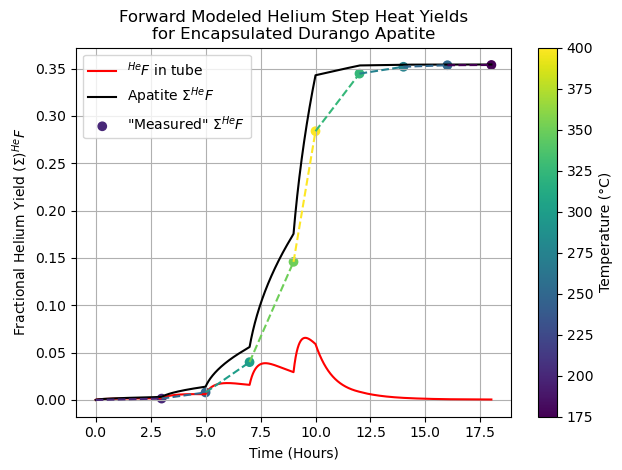

Done! Output file: simulated_durango in C:\Users\dashf\pyrite


C:\Users\dashf\AppData\Local\Temp\ipykernel_41444\1212846932.py:72: RuntimeWarning: divide by zero encountered in scalar divide
  D_a2 = (1/(np.pi**2*t)) * np.log( (1-Fp)/(1-F) )


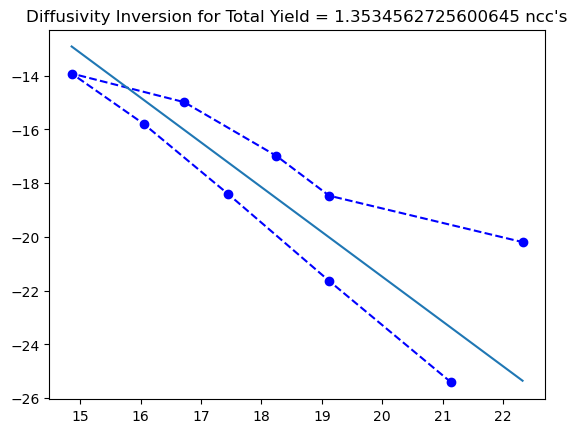

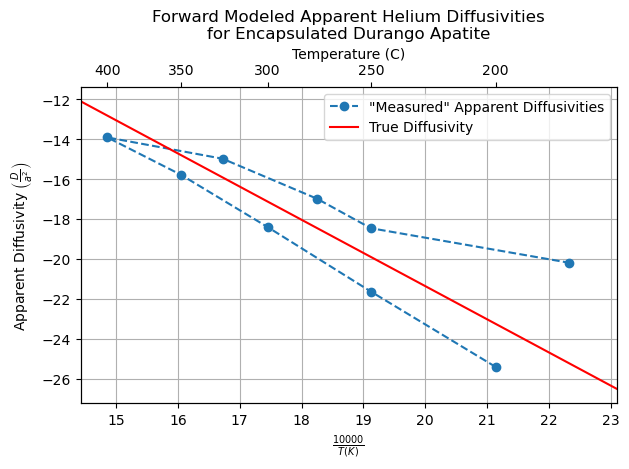

In [ ]:
#FIG 1!!!

Ratoms = 1.3621E-22
Rcal = 1.987

Tsched = [200,100,230,100,260,100,290,160,400,200,400,200] 
tsched = [3600,3600,3600,3600,7200,3600,3600,14400,1800,3600,1800,3600]

def Simulate_Diffusion_Tube(D0, a, Ea, T, t, OD, ID, R = 1.987):
    """Let T and t be 1D arrays of equal length describing sequential time-temperature steps,
    T in Kelvin and t in seconds
    Let D0_a2 be sec^-1
    Default activation energy units are joules/mol, but R can be changed to match other energy units"""
    #if np.shape(T) != np.shape(t) or T.ndim != 1:
    #    raise ValueError('Let T and t be 1D arrays of equal length describing sequential time-temperature steps')
    
    total_seconds = np.arange(np.sum(t))
    n0 = []
    n0_ends = []
    Fstep_apparent = []
    Fcum = []
    Fcum_apparent = []
    Fcum_apparentP = 0
    FP = 0
    Dt_a2 = 0
    n0P = 0 
    t_out = []
    t_outP = 0
    outF = 0
    temps = []
    Fsteps = []
    #n1HT = [0]
    G = 2/(np.log(OD/ID)*((ID/2)**2))
    for j, tstep in enumerate(t):
        Tk = T[j] + 273
        D = D0*np.exp(-Ea/(R*Tk))
        outF = 0 # collected gas in a single step
        denom = Tk*Ratoms*G*swets_K(Tk)
        for s in np.arange(tstep):
            Dt_a2 += D/(a**2) # per second
            F_step = Forward_Diffuse(Dt_a2) - FP
            n0.append(F_step+n0P)
            FP += F_step
            Fcum.append(FP)
            n_n0 = tube_permeate2(T = Tk, t=1, ID = ID, OD = OD)
            out = n0[-1]*(1-n_n0)
            n0[-1] -= out
            outF += out
            Fsteps.append(out)
            n0P = n0[-1]
            #n1HT.append(((out-n1HT[-1])/denom)/(1-(1/denom)))
            #n1HT
            temps.append(Tk)
        print(n_n0)
        n0_ends.append(n0P)
        Fstep_apparent.append(outF)
        Fcum_apparent.append(outF+Fcum_apparentP)
        Fcum_apparentP = Fcum_apparent[-1]
        t_out.append(t_outP+tstep)
        t_outP = t_out[-1]
        
    return Fcum, n0, Fstep_apparent, Fcum_apparent, n0_ends, t_out, temps, Fsteps

time_input =  [10800,7200,7200,7200,3600, 7200, 7200,7200,7200] #seconds
temp_input = [200,250,300,350,400,325,275,250,175] # celcius

Fcum, n0, Fstep_apparent, Fcum_apparent, n0_ends, t_out, temps, Fsteps = Simulate_Diffusion_Tube(D0 = 10**1.5, a = 150/1E4, T = temp_input, t =time_input, Ea = 33000, OD = 1000/1E4, ID=600/1E4)
#plt.figure(figsize=(2.5,3.5))
plt.plot(np.arange(len(n0))/3600, n0, color = 'red', label = r'$^{He}F$ in tube')
#plt.plot(np.arange(len(n0)), Fsteps, label = 'Apparent Yield (measured)')
#plt.plot(np.arange(len(n0)), Fcum[1:]-Fcum[:-1], label = 'Fractional Yield from Apatite')

plt.plot(np.arange(len(n0))/3600, Fcum, color = 'black', label = r'Apatite $\Sigma ^{He}F$')
#plt.plot(np.array(t_out)/3600, Fcum_apparent, color = 'k', linestyle = '--', label = r'"Measured" $\Sigma ^{He}F$')

cmap = mpl.cm.get_cmap('viridis')
norm = mpl.colors.Normalize(vmin=np.min(temp_input), vmax=np.max(temp_input))
mapped_colors = cmap(norm(temp_input))


plt.plot([0,t_out[0]/3600], [0,Fcum_apparent[0]], color = mapped_colors[0], linestyle = '--')
for i, ti in enumerate(t_out[:-1]):
    plt.plot([ti/3600, t_out[i+1]/3600], [Fcum_apparent[i],Fcum_apparent[i+1]], color = mapped_colors[i+1], linestyle = '--')
#plt.scatter(t_out, n1HT[1:], label = 'Inferred Tube Contents from High Temp')
plt.xlabel('Time (Hours)')
plt.ylabel(r'Fractional Helium Yield $\left(\Sigma\right) ^{He}F$')
plt.scatter(np.array(t_out)/3600, Fcum_apparent, c = temp_input,label = r'"Measured" $\Sigma ^{He}F$')

cbar = plt.colorbar()
cbar.set_label('Temperature (°C)')
plt.grid(True)
plt.title('Forward Modeled Helium Step Heat Yields\nfor Encapsulated Durango Apatite')
plt.legend()#loc='upper left', fontsize = 6)
plt.tight_layout()
plt.savefig('Durango_Sim.jpg', dpi=256)#, dpi = 1024)
plt.show()


diffdat = diffusion_reduction(Fstep_apparent+[1-Fstep_apparent[-1]], TimeSeconds=np.array(time_input+[0]), TempKelvin=np.array(temp_input+[0])+273, newDiffName='simulated_durango')
plt.show()

x = diffdat['10^4/T']
y = diffdat['ln(D/a^2)']

['Temp (C)', 'Time (min)', 'He Yield (nCC@STP)', 'Fcum', 'D/a^2 ', 'ln(D/a^2)', '10^4/T']

fig = plt.figure()
ax1 = fig.add_subplot(111)
ax2 = ax1.twiny()
Ctemps = np.array([100,150,200,250,300,350,400])

xliminp = [160,420]

ax1.plot(x,y,marker = 'o', linestyle = '--', label = '"Measured" Apparent Diffusivities')


xlim = np.array([1E4/(273+xliminp[1]),1E4/(273+xliminp[0])])

ax1.plot(xlim,np.log((10**1.5)/(0.0150**2)*np.exp(-33000/(1.987*10000/xlim))), color = 'red', label = 'True Diffusivity')

ax1.set_xlim(xlim)
#ax1.set_ylim([-35,-9])
#ax1.set_ylim([-32,-17])#[-35,-9])
ax2.set_xticks(1E4/(Ctemps+273))
ax2.set_xlim(ax1.get_xlim())
ax2.set_xticklabels(Ctemps)
ax2.set_xlabel('Temperature (C)')
ax1.set_xlabel(r'$\frac{10000}{T^{ }(K)}$')
ax1.set_ylabel(r'Apparent Diffusivity $\left(\frac{D}{a^2}\right)$')
#ax1.legend(loc = 'upper right', fontsize = 8)
ax1.grid(True)
ax1.legend()
plt.title('Forward Modeled Apparent Helium Diffusivities\nfor Encapsulated Durango Apatite')
fig.tight_layout()
plt.savefig('Apatite_diff_sim.jpg', dpi=256)#dpi = 1024)
plt.show()

In [14]:
## Steady State Simulations
n1HT = [0]

OD = 1000/1E4
ID=600/1E4
G = 2/(np.log(OD/ID)*((ID/2)**2))

for i, step in enumerate(Fstep_apparent):
    denom = (Tsched[i]+273)*tsched[i]*Ratoms*G*swets_K(Tsched[i]+273)
    n1HT.append( ((((step-n1HT[-1])/denom)*(1-np.exp(-denom))) + (n1HT[-1]*np.exp(-denom)))  /  (1-((1/denom)*(1-np.exp(-denom)))))


[0.007521068587109953, 0.19276776417372538, -0.04240432867858791, 3.2936349763162713, -1.9479374374841893, 3.7662487353261684, -2.773317552655747, 2.165781556889291, -1.4752498710500734]
[4.814035635818253, 9.717171525904067, 9.6656312706464, 6.296619291548867, 4.931358085092421, 11.087574843732511, 8.219575599923312, 5.292866246088592, 4.680910844971492]


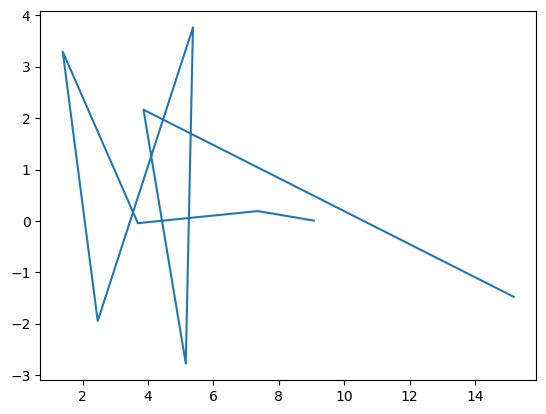

In [250]:
print(n1HT[1:])
print(Fstep_apparent)

plt.plot(np.array(n0)[np.array(t_out)-1], n1HT[1:])

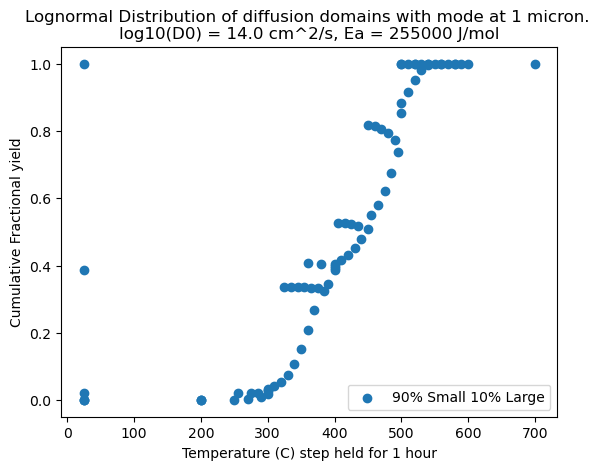

C:\Users\dashf\AppData\Local\Temp\ipykernel_25736\3336080388.py:17: RuntimeWarning: divide by zero encountered in scalar divide
  D_a2 = (1/(np.pi**2*t)) * np.log( (1-Fp)/(1-F) )
C:\Users\dashf\AppData\Local\Temp\ipykernel_25736\3336080388.py:17: RuntimeWarning: invalid value encountered in scalar divide
  D_a2 = (1/(np.pi**2*t)) * np.log( (1-Fp)/(1-F) )
C:\Users\dashf\AppData\Local\Temp\ipykernel_25736\3690841072.py:46: RuntimeWarning: divide by zero encountered in log
  plt.scatter(1E4/(T+273), np.log(np.array(D_MDD)))#, label = '90% 430 um; 10% 4.3 cm')
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


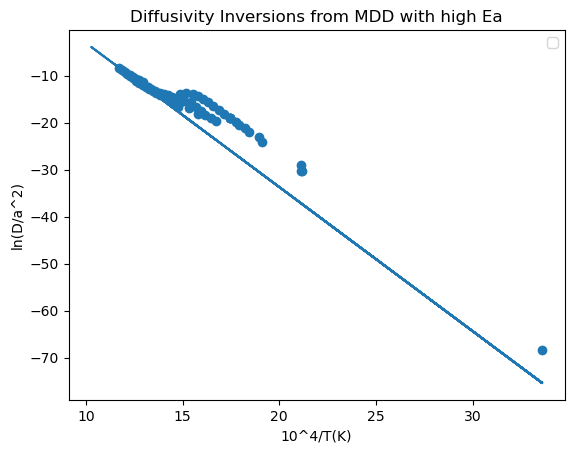

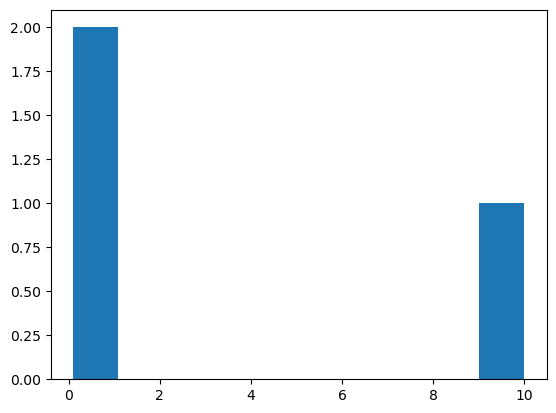

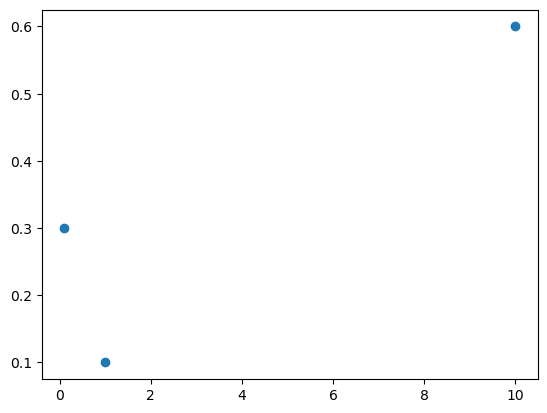

In [11]:
D_MDD = []
FpMDD = 0

diffDat = pd.read_csv('Batch 55_clarity.csv')
T = diffDat['Avg Temp'].to_numpy()
t = diffDat['Time (min)'].to_numpy()

#v = np.array([0.9,0.1]) # Parts
#a = np.array([a1, a2]) # Radii in centimeters

# log normal size distribution with mode at 1 micron 
#a = np.exp(np.linspace(-7,2,100))/1E4
#a = max(a*1.01) - a
a = np.linspace(10**-2, 10**0,100)/1E4
#v = GaussianPDF(np.linspace(-3,3,100)) #sigma
#v = np.ones_like(a)
#v = np.append(np_ones(30)
              
a = np.array([0.1,1,10])
v = np.array([0.3,0.1,0.6])
              
v /= np.sum(v)

              
              
D0 = float(10**14)
Ea = 255000

Fcum_MDD = Simulate_MDD_diffusion(D0 = D0, Ea = Ea, v = v, a = a, T = T, t = t)
#plt.scatter(T,Fcum_Qz430, label = '430 micron');
#plt.scatter(T,Fcum_Qz4cm, label = '4.3 centimeter');
plt.scatter(T,Fcum_MDD, label = '90% Small 10% Large');
plt.legend();
plt.title(f'Lognormal Distribution of diffusion domains with mode at 1 micron. \nlog10(D0) = {np.log10(D0)} cm^2/s, Ea = {Ea} J/mol');
plt.xlabel('Temperature (C) step held for 1 hour');
plt.ylabel('Cumulative Fractional yield');
plt.show()

for i in range(len(Fcum_MDD)):
    FMDD = Fcum_MDD[i]
    D_MDD.append(InvertFrequencyFactor(F = FMDD, Fp = FpMDD, t = t[0]*60)) # Takes time in seconds
    FpMDD = FMDD

#plt.plot(Inv_Temp, np.log(np.array(D_a2_qz430um)), 'r', label = '430 um');
plt.plot(1E4/(T+273), np.log(np.array(D0/(max(a)**2)*np.exp(-Ea/((T+273)*8.3145)))))
plt.scatter(1E4/(T+273), np.log(np.array(D_MDD)))#, label = '90% 430 um; 10% 4.3 cm')
plt.xlabel('10^4/T(K)');
plt.ylabel('ln(D/a^2)');
plt.legend()
plt.title('Diffusivity Inversions from MDD with high Ea');
plt.show()

plt.hist(a)
plt.show()
plt.scatter(a,v)
plt.show()

In [39]:
tsched =  [1000,7200,7200,7200,3600, 7200, 7200,7200,7200] #seconds
t_sched = np.array(tsched)/10
Tsched = [250,200,300,350,400,325,275,250,420] # celcius
Rsched = np.array([5,4,3,2,6,7,4,2,8])/3600

def Simulate_Diffusion_Tube_P(P, T, t, OD, ID, R = 1.987):
    """Let T and t be 1D arrays of equal length describing sequential time-temperature steps,
    T in Kelvin and t in seconds
    Let D0_a2 be sec^-1
    Default activation energy units are joules/mol, but R can be changed to match other energy units"""
    #if np.shape(T) != np.shape(t) or T.ndim != 1:
    #    raise ValueError('Let T and t be 1D arrays of equal length describing sequential time-temperature steps')
    
    total_seconds = np.arange(np.sum(t))
    n0 = []
    n0_ends = []
    Fstep_apparent = []
    Fcum = []
    Fcum_apparent = []
    Fcum_apparentP = 0
    FP = 0
    #Dt_a2 = 0
    n0P = 0 
    t_out = []
    t_outP = 0
    outF = 0
    temps = []
    Fsteps = []
    #n1HT = [0]
    G = 2/(np.log(OD/ID)*((ID/2)**2))
    for j, tstep in enumerate(t):
        Tk = T[j] + 273
        #D = D0*np.exp(-Ea/(R*Tk))
        outF = 0 # collected gas in a single step
        denom = Tk*Ratoms*G*swets_K(Tk)
        F_step = P[j]
        for s in np.arange(tstep):
            #Dt_a2 += D/(a**2) # per second
            #F_step = Forward_Diffuse(Dt_a2) - FP
            n0.append(F_step+n0P)
            FP += F_step
            Fcum.append(FP)
            n_n0 = tube_permeate2(T = Tk, t=1, ID = ID, OD = OD)
            out = n0[-1]*(1-n_n0)
            n0[-1] -= out
            outF += out
            Fsteps.append(out)
            n0P = n0[-1]
            #n1HT.append(((out-n1HT[-1])/denom)/(1-(1/denom)))
            #n1HT
            temps.append(Tk)
        print(n_n0)
        n0_ends.append(n0P)
        Fstep_apparent.append(outF)
        Fcum_apparent.append(outF+Fcum_apparentP)
        Fcum_apparentP = Fcum_apparent[-1]
        t_out.append(t_outP+tstep)
        t_outP = t_out[-1]
        
    return Fcum, n0, Fstep_apparent, Fcum_apparent, n0_ends, t_out, temps, Fsteps

Fcum, n0, Fstep_apparent, Fcum_apparent, n0_ends, t_out, temps, Fsteps = Simulate_Diffusion_Tube_P(P = Rsched, T = Tsched, t = tsched, OD = OD, ID = ID, R = 1.987)

0.9998323215450927
0.9999078729596292
0.9997227990265537
0.9995687609585538
0.9993543983645329
0.9996536899456999
0.9997821461061526
0.9998323215450927
0.9992524518702172


In [40]:
n1HT = [0]

for i, step in enumerate(Fstep_apparent):
    denom = (Tsched[i]+273)*tsched[i]*Ratoms*G*swets_K(Tsched[i]+273)
    n1HT.append( ((((step-n1HT[-1])/denom)*(1-np.exp(-denom))) + (n1HT[-1]*np.exp(-denom)))  /  (1-((1/denom)*(1-np.exp(-denom)))))



In [253]:
n1HT

[0,
 9.076059471604587,
 7.3578003143169095,
 3.6926256144853533,
 1.39559605873288,
 2.465223350343517,
 5.377389716756609,
 5.157277172199928,
 3.864282609187095,
 15.185013480092765]

In [20]:
Fsteps

[1.2795422273716626e-07,
 2.558966574304888e-07,
 3.838273051659652e-07,
 5.11746167029493e-07,
 6.396532441068698e-07,
 7.67548537483793e-07,
 8.954320482458599e-07,
 1.0233037774785684e-06,
 1.1511637262673153e-06,
 1.2790118956973984e-06,
 1.406848286854015e-06,
 1.5346729008222626e-06,
 1.6624857386871386e-06,
 1.7902868015335409e-06,
 1.918076090446267e-06,
 2.0458536065100144e-06,
 2.1736193508093806e-06,
 2.301373324428864e-06,
 2.4291155284528625e-06,
 2.5568459639656737e-06,
 2.6845646320514955e-06,
 2.8122715337944264e-06,
 2.9399666702784657e-06,
 3.0676500425875106e-06,
 3.1953216518053606e-06,
 3.3229814990157134e-06,
 3.450629585302169e-06,
 3.5782659117482255e-06,
 3.705890479437283e-06,
 3.83350328945264e-06,
 3.961104342877498e-06,
 4.088693640794955e-06,
 4.216271184288013e-06,
 4.34383697443957e-06,
 4.471391012332428e-06,
 4.598933299049288e-06,
 4.726463835672751e-06,
 4.853982623285317e-06,
 4.981489662969389e-06,
 5.1089849558072684e-06,
 5.236468502881157e-06,
 

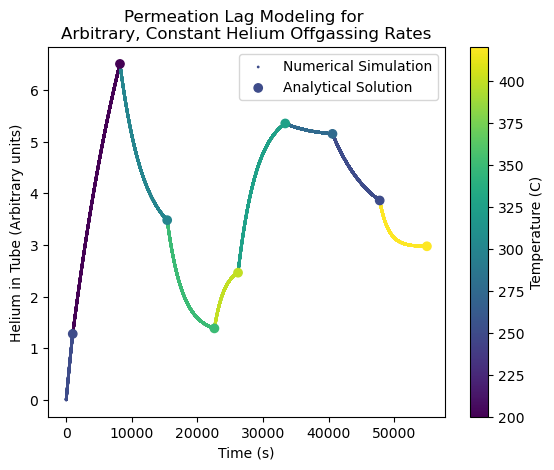

In [43]:
plt.scatter(np.arange(len(n0)), n0, s = 1, c = np.array(temps)-273, label = 'Numerical Simulation')# c = np.array(n0)/np.array(Fsteps), s = 1, label = 'Numerical Simulation')
plt.scatter(t_out, n1HT[1:], c = np.array(temps)[np.array(t_out)-1] - 273, label = 'Analytical Solution')#, c = (np.array(n0)/np.array(Fsteps))[np.array(t_out)-1], label = 'Analytical Solution')
cbar = plt.colorbar()
cbar.set_label('Temperature (C)')#'n1/Q')
plt.xlabel('Time (s)')
plt.ylabel('Helium in Tube (Arbitrary units)')
plt.title('Permeation Lag Modeling for \nArbitrary, Constant Helium Offgassing Rates')
plt.legend()
plt.savefig('EQNtest.jpg', dpi  = 256)

'\ntemps = np.linspace(25,500,1000) + 273\nQs = \nfor :\n    NP = []\n    for temp in temps:\n        NP.append(n_p(T = temp, t = sec))\n    plt.scatter(temps-273, NP, label = f"{sec/3600} Hour Step")\nplt.xlabel(\'Temperature (C)\')\nplt.ylabel(\'Portion of Yield in Tube\')\nplt.title(\'Relative Permeation Lag for Typical Tube\')\nplt.legend()\n#plt.savefig(\'LagPlot.jpg\', dpi = 256)\n\n\n'

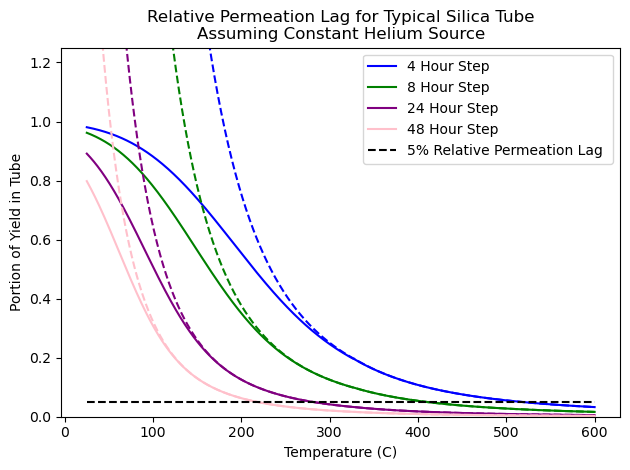

In [489]:
OD = 0.1
ID = 0.06
G = 2/(np.log(OD/ID)*((ID/2)**2))

def n_p(T, t):
    K = swets_K(T)
    return((1/(K*G*T*t*Ratoms))*(1-np.exp(-K*G*T*Ratoms*t)))

def SS(T, t):
    K = swets_K(T)
    return((1/(K*G*T*t*Ratoms)))

def ssN(T, Q):
    K = swets_K(T)
    return(Q/(K*G*T*t*Ratoms))



colors = ['Blue', 'Green', 'Purple','Pink']
temps = np.linspace(25,600,1000) + 273
for i, sec in enumerate(np.array([4,8,24,48])*3600):
    NP = []
    ss = []
    for temp in temps:
        NP.append(n_p(T = temp, t = sec))
        ss.append(SS(T = temp, t = sec))
    plt.plot(temps-273, NP, label = f"{int(sec/3600)} Hour Step", color = colors[i])
    plt.plot(temps-273, ss, linestyle = '--', color = colors[i])
plt.xlabel('Temperature (C)')
plt.ylabel('Portion of Yield in Tube')
plt.ylim((0,1.25))
plt.plot([25,600],[0.05,0.05], linestyle = '--', color = 'black', label = '5% Relative Permeation Lag ')
plt.title('Relative Permeation Lag for Typical Silica Tube\nAssuming Constant Helium Source')
plt.legend()
plt.tight_layout()
plt.savefig('LagPlot.jpg', dpi = 256)

"""
temps = np.linspace(25,500,1000) + 273
Qs = 
for :
    NP = []
    for temp in temps:
        NP.append(n_p(T = temp, t = sec))
    plt.scatter(temps-273, NP, label = f"{sec/3600} Hour Step")
plt.xlabel('Temperature (C)')
plt.ylabel('Portion of Yield in Tube')
plt.title('Relative Permeation Lag for Typical Tube')
plt.legend()
#plt.savefig('LagPlot.jpg', dpi = 256)


"""

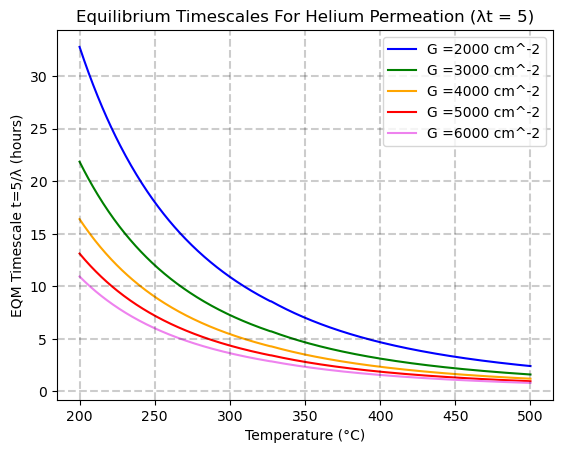

In [232]:
Gs = [2000,3000,4000,5000,6000]
cols = ['Blue', 'Green', 'Orange', 'Red', 'Violet']
Ts = np.linspace(200,500,500)#Celcius
Ks = []
fig,ax = plt.subplots()
for T in Ts:
    Ks.append(swets_K(T+273))
Ks = np.array(Ks)
for i,G in enumerate(Gs):
    lams = (Ts+273)*Ks*G*Ratoms
    tao5 = (5/lams)/3600
    plt.plot(Ts,tao5,color = cols[i],label=f"G ={G} cm^-2")
plt.legend()
plt.title('Equilibrium Timescales For Helium Permeation (λt = 5)')
plt.xlabel('Temperature (°C)')
plt.ylabel('EQM Timescale t=5/λ (hours)')
make_grid()
plt.savefig('EQM_Timescales_Permeation.jpg', dpi = 256)

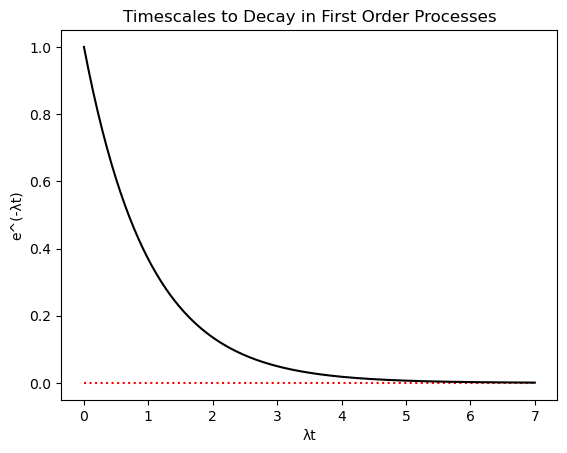

In [177]:
lamt = np.linspace(0,7,200)
plt.hlines(0,0,7,linestyle=':',color='red')
plt.plot(lamt,np.exp(-lamt),color='black')
plt.title('Timescales to Decay in First Order Processes')
plt.xlabel('λt')
plt.ylabel("e^(-λt)")
plt.savefig('FirstOrderDecay.jpg', dpi = 256)

(Time to EQM at T = 200°C: 15.075106127429558 hours
Time worth of steady state tube concentration: 180.9012735291547 minutes
(Time to EQM at T = 300°C: 5.009709605465359 hours
Time worth of steady state tube concentration: 60.1165152655843 minutes
(Time to EQM at T = 400°C: 2.1506149146583473 hours
Time worth of steady state tube concentration: 25.807378975900168 minutes
(Time to EQM at T = 500°C: 1.1063313173615577 hours
Time worth of steady state tube concentration: 13.275975808338693 minutes


C:\Users\dashf\AppData\Local\Temp\ipykernel_25120\3126569932.py:35: RuntimeWarning: divide by zero encountered in divide
  plt.plot(ts/3600, 100*(ml-nss)/omegas, linestyle = '-', color = cols[i], label = f"T: {T}°C")


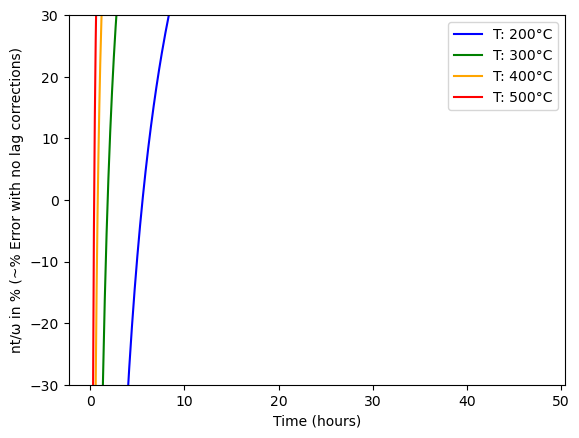

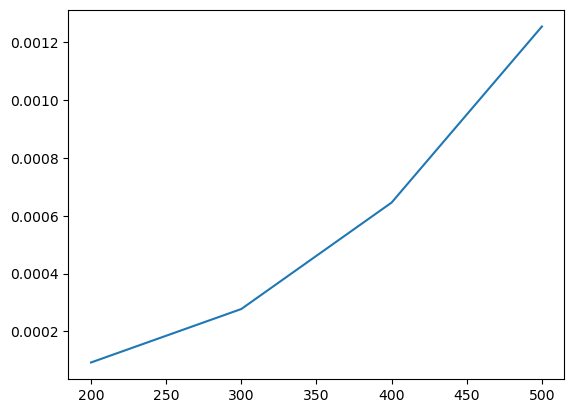

In [233]:
### CALCULATE AMOUNTS IN TUBES WITH CONSTANT RATE, THEN FIND RATIO OF SMALL OMEGA AND nt

OD = 0.1
ID = 0.06
G = 2/(np.log(OD/ID)*((ID/2)**2))
cols = ['Blue', 'Green', 'Orange', 'Red']
ts = np.linspace(0,2,500)*24*3600 #seconds
omegas = ts # unitless 1 He per second
Ts = [200,300,400,500]
lams = []
for i, T in enumerate(Ts):
    K =swets_K(T+273)
    lam = G*K*(T+273)*Ratoms
    print(f"(Time to EQM at T = {T}°C: {(5/lam)/3600} hours")
    lams.append(lam)
    nss = 1/lam
    print(f"Time worth of steady state tube concentration: {nss/60} minutes")
    n0h = nss*5
    n0l = 0#nss/4
    nth = nss + ((n0h-nss)*np.exp(-lam*ts))
    ntl = nss + ((n0l-nss)*np.exp(-lam*ts))
    mh = n0h + omegas - nth
    ml = n0l + omegas - ntl
    """
    nt = (1/(lams*ts))+(0.5/ts-(1/lams*ts)*np.exp(-lams*ts))
    nt1 = (1/(lams*ts))+(2/ts-(1/lams*ts)*np.exp(-lams*ts))
    nt2 = (1/(lams*ts))
    """
    
    #plt.plot(ts/3600,100*nss/omegas,color = cols[i],linestyle = ":", alpha = 0.5)
    #plt.plot(ts/3600,100*nth/omegas,color = cols[i],label = f"T: {T}C°")
    #plt.plot(ts/3600,100*ntl/omegas,color = cols[i],linestyle = '--')
    #plt.plot(ts/3600, 100*(mh-omegas)/omegas, linestyle = '--', color = cols[i], label = f"T: {T}°C")
    #plt.plot(ts/3600, 100*(ml-omegas)/ml, linestyle = ':', color = cols[i], label = f"T: {T}°C")
    plt.plot(ts/3600, 100*(ml-nss)/omegas, linestyle = '-', color = cols[i], label = f"T: {T}°C")
    #plt.plot(ts/3600, 100*nss/mh, linestyle = ':', color = cols[i], label = f"T: {T}°C")
    #plt.hlines(nss, np.min(ts/3600), np.max(ts/3600), color = cols[i])
    #plt.plot(ts/3600, 100*(ml-omegas)/ml, linestyle = ':', color = cols[i])
plt.ylim((-30,30))
plt.legend()
plt.xlabel("Time (hours)")
plt.ylabel("nt/ω in % (~% Error with no lag corrections)")
plt.show()
plt.plot(Ts,lams)

(Time to EQM at T = 200°C: 15.075106127429558 hours
Time worth of steady state tube concentration: 180.9012735291547 minutes
(Time to EQM at T = 250°C: 8.282354718921887 hours
Time worth of steady state tube concentration: 99.38825662706265 minutes
(Time to EQM at T = 300°C: 5.009709605465359 hours
Time worth of steady state tube concentration: 60.1165152655843 minutes
(Time to EQM at T = 400°C: 2.1506149146583473 hours
Time worth of steady state tube concentration: 25.807378975900168 minutes
(Time to EQM at T = 500°C: 1.1063313173615577 hours
Time worth of steady state tube concentration: 13.275975808338693 minutes


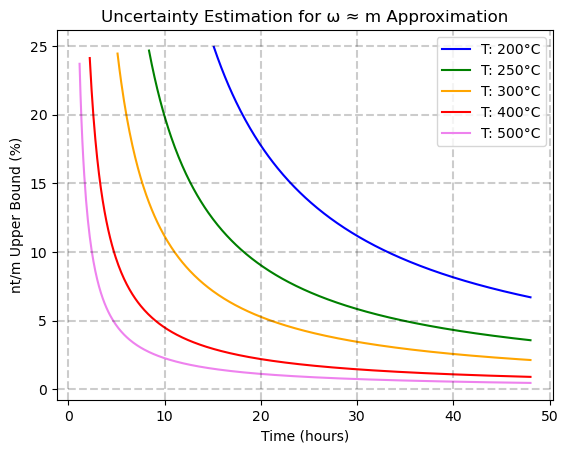

In [234]:
### CALCULATE AMOUNTS IN TUBES WITH CONSTANT RATE, THEN FIND RATIO OF SMALL OMEGA AND nt
def Jones(T):
    return 1.17*np.exp(-57/(1.987*T))

fig, ax = plt.subplots()
OD = 0.083
ID = 0.054
G = 2/(np.log(OD/ID)*((ID/2)**2))
cols = ['Blue','Green', 'Orange', 'Red', 'Violet']
ts = np.linspace(0,2,500)*24*3600 #seconds
omegas = ts # unitless 1 He per second
Ts = [200,250,300,400,500]
lams = []
for i, T in enumerate(Ts):
    K =swets_K(T+273)
    K3 = K*Jones(T+273)
    lam = G*K*(T+273)*Ratoms
    print(f"(Time to EQM at T = {T}°C: {(5/lam)/3600} hours")
    lams.append(lam)
    nss = 1/lam
    LT = lam*ts
    print(f"Time worth of steady state tube concentration: {nss/60} minutes")
    n0h = nss*5
    n0l = 0#nss/4
    nth = nss + ((n0h-nss)*np.exp(-lam*ts))
    ntl = nss + ((n0l-nss)*np.exp(-lam*ts))
    ml = omegas
    nub = ml/(LT-1)
    nub1 = omegas/(LT-1)
    mh = n0l + omegas - ntl
    """
    nt = (1/(lams*ts))+(0.5/ts-(1/lams*ts)*np.exp(-lams*ts))
    nt1 = (1/(lams*ts))+(2/ts-(1/lams*ts)*np.exp(-lams*ts))
    nt2 = (1/(lams*ts))
    """
    
    #plt.plot(ts/3600,100*nss/omegas,color = cols[i],linestyle = ":", alpha = 0.5)
    #plt.plot(ts/3600,100*nth/omegas,color = cols[i],label = f"T: {T}C°")
    #plt.plot(ts/3600,100*ntl/omegas,color = cols[i],linestyle = '--')
    #plt.plot(ts/3600, 100*(mh-omegas)/omegas, linestyle = '--', color = cols[i], label = f"T: {T}°C")
    #plt.plot(ts/3600, 100*(ml-omegas)/ml, linestyle = ':', color = cols[i], label = f"T: {T}°C")
    #plt.plot(ts[LT>=5]/3600, 100*(nub/ml)[LT>=5], linestyle = '-', color = cols[i], label = f"T: {T}°C",alpha=0.1)
    plt.plot(ts[LT>=5]/3600, 100*(1/(LT-1))[LT>=5], linestyle = '-', color = cols[i], label = f"T: {T}°C")
    #plt.hlines(nss, np.min(ts/3600), np.max(ts/3600), color = cols[i])
    #plt.plot(ts/3600, 100*(ml-omegas)/ml, linestyle = ':', color = cols[i])
#plt.ylim((0,30))
plt.legend()
plt.xlabel("Time (hours)")
plt.ylabel("nt/m Upper Bound (%)")

make_grid()

plt.title('Uncertainty Estimation for ω ≈ m Approximation')
plt.savefig('UncertEstLongStep1.jpg', dpi = 256)
plt.show()

In [235]:
tube_permeate2(T)

4350.255975491595

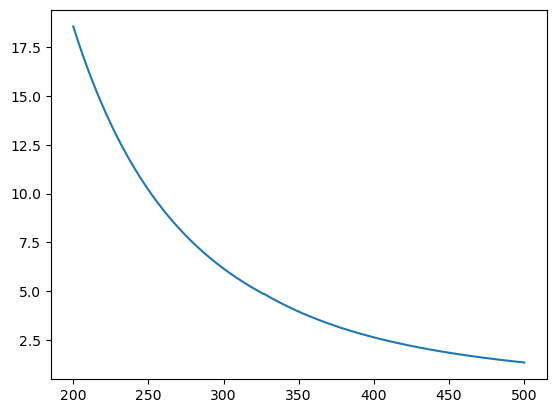

In [19]:
OD = 0.0787
ID = 0.0505

G = 2/(np.log(OD/ID)*((ID/2)**2))
Tk = np.linspace(200,500,1000) + 273
F = 0.1
Ks = []
for Ti in Tk:
    Ks.append(swets_K(Ti))
Ks = np.array(Ks)
transparency_time = (1/(Ks*G*Tk*F*Ratoms))/3600
plt.plot(Tk-273, transparency_time)

print()

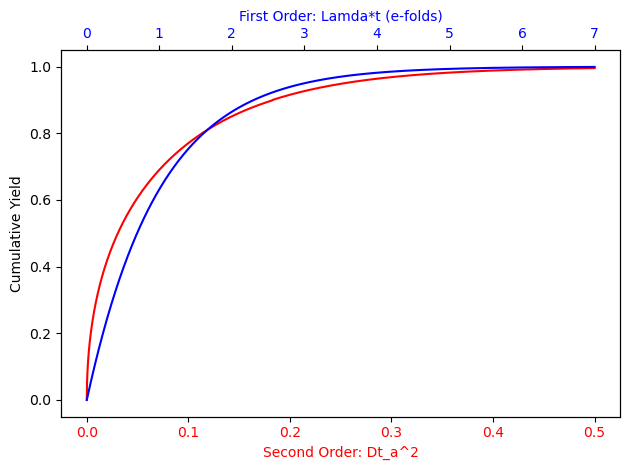

In [13]:
Dt_a2 = np.linspace(0,0.5,10000)
e_folds = np.linspace(0,7,1000)

fig = plt.figure()
ax1 = fig.add_subplot(111)
ax2 = ax1.twiny()

col1 = 'red'
col2 = 'blue'

Fcum = [Forward_Diffuse(step) for step in Dt_a2]
ax1.plot(Dt_a2, Fcum, label = 'Second Order', color = col1)
ax2.plot(e_folds, 1-np.exp(-e_folds), label = 'First Order', color = col2)

ax2.set_xlabel('First Order: Lamda*t (e-folds)', color = col2)
ax1.set_xlabel('Second Order: Dt_a^2', color = col1)
ax1.set_ylabel('Cumulative Yield')
ax1.tick_params(axis='x', labelcolor=col1)
ax2.tick_params(axis='x', labelcolor=col2)
plt.tight_layout()
plt.savefig('First_Second_Order_yields.jpg', dpi = 256)

0.025927971497471985
6.970619387222587e+17


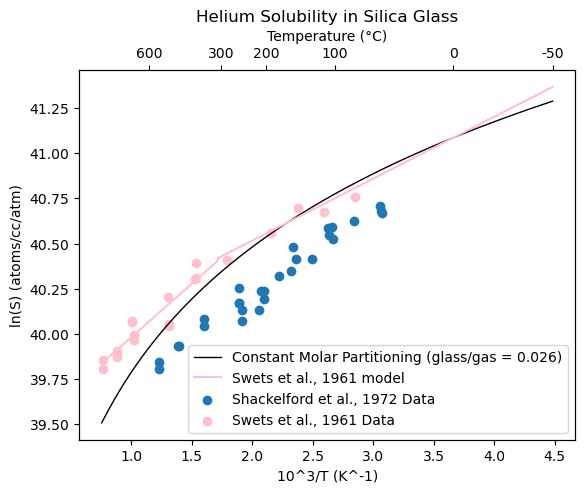

In [56]:

Rcal = 1.987
def swets_S(T):
    """Returns Permeability of fused Silica in units: mol/cm/s/atm for a given T in Kelvin"""
    if T >= 583:
        DEa = 6613 # factor of 4 to convert from g Helium to moles
        SEa = -1174
        DFF = 7.40E-4
        SFF = 1.28E17
    else:
        DEa = 5580
        SEa = -680
        DFF = 3.04E-4
        SFF = 1.99E17
       
    D = DFF*np.exp(-DEa/(Rcal*T))
    S = SFF*np.exp(-SEa/(Rcal*T)) # K units: atom/cm/s/dP atm/
    #print(f"Solubility at T = {T-273}C: {S} atoms/cm3/atm")
    #print(f"Diffusivity at T = {T-273}C: {D} cm2/s")
    #print(f"Permeation at T = {T-273}C in mol/cm/s/atm: {D*S}")
    K = D*S#/6.022E23 #units: mol/cm/s/atm
    return S

def swets_D(T):
    """Returns Permeability of fused Silica in units: mol/cm/s/atm for a given T in Kelvin"""
    if T >= 573:
        DEa = 6613 # factor of 4 to convert from g Helium to moles
        SEa = -1174
        DFF = 7.40E-4
        SFF = 1.28E17
    else:
        DEa = 5580
        SEa = -680
        DFF = 3.04E-4
        SFF = 1.99E17
       
    D = DFF*np.exp(-DEa/(Rcal*T))
    S = SFF*np.exp(-SEa/(Rcal*T)) # K units: atom/cm/s/dP atm/
    #print(f"Solubility at T = {T-273}C: {S} atoms/cm3/atm")
    #print(f"Diffusivity at T = {T-273}C: {D} cm2/s")
    #print(f"Permeation at T = {T-273}C in mol/cm/s/atm: {D*S}")
    K = D*S#/6.022E23 #units: mol/cm/s/atm
    return D

NDGas = 6.02214E23*(0.001/22.4) # Number Density of Helium Atoms per cc in gas at 1 atm

NDGlass = swets_S(273)

STP_Partitioning = NDGlass/NDGas
print(STP_Partitioning)
print(NDGlass)

shackleford_data = pd.read_csv('shacklefordHeSolubility.csv', header = None).to_numpy()
swets_data = pd.read_csv('swetsHeSolubility.csv').to_numpy()


def S_constantND(T):
    return((NDGlass)*(273/T))

Ts = np.linspace(-50,1050,10000) + 273
Ss = S_constantND(Ts)

Sswets = np.array([swets_S(t) for t in Ts])

fig = plt.figure()
ax1 = fig.add_subplot(111)
ax2 = ax1.twiny()
#min_T = np.min(10000/TempKelvin)
#max_T = np.max(10000/TempKelvin)
Ctemps = np.array([-50,0,100,200,300,600])#np.linspace(200,700, 11,dtype = int)
ax1.plot(1000/Ts, np.log(Ss), color = 'black', linewidth = 1, label = 'Constant Molar Partitioning (glass/gas = 0.026)')
#twice the temperature; twice the pressure
ax1.plot(1000/Ts, np.log(Sswets), color = 'pink', label = 'Swets et al., 1961 model')
ax1.scatter(1000/(shackleford_data[:,0]), np.log(1E17*shackleford_data[:,1]), label = 'Shackelford et al., 1972 Data')
ax1.scatter(1000/(swets_data[:,0]+273), np.log(swets_data[:,3]), color = 'pink', label = 'Swets et al., 1961 Data')

S0s = np.array([1.8,1.5,1.3,1.8,2,1.9,1.9])*1E17
SEas = np.array([599, 874,631,675,622,527,518])
types = [1,1,2,2,3,3,4]
colors = ['red', 'purple', 'blue', 'green']
for i, S0 in enumerate(S0s):
    SEa = SEas[i]
    #ax1.plot(1000/Ts, np.log(S0*np.exp(SEa/(1.987*Ts))), color = colors[types[i]-1])

ax2.set_xticks(1E3/(Ctemps+273))
ax2.set_xlim(ax1.get_xlim())
ax2.set_xticklabels(Ctemps)
ax2.set_xlabel('Temperature (°C)')
ax1.set_xlabel('10^3/T (K^-1)')
ax1.set_ylabel('ln(S) (atoms/cc/atm)')
ax1.legend()



plt.title('Helium Solubility in Silica Glass')
plt.savefig('glass_solubility_fig.jpg', dpi = 256, bbox_inches='tight')
plt.show()


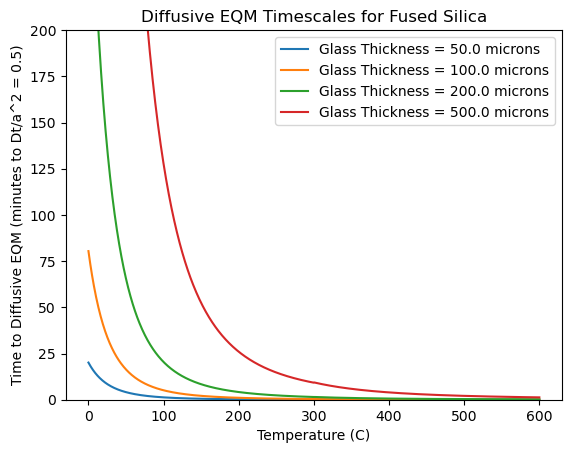

In [71]:
H = np.array([0.005,0.01, 0.02, 0.05])
Ts = np.linspace(0,600,1000) + 273
Ds = [swets_D(T) for T in Ts]


for h in H:
    plt.plot(Ts-273, ((0.5*(h**2))/Ds)/60, label = f'Glass Thickness = {h*10000} microns')
plt.xlabel('Temperature (C)')
plt.ylabel('Time to Diffusive EQM (minutes to Dt/a^2 = 0.5)')
plt.title('Diffusive EQM Timescales for Fused Silica')
plt.ylim((0,200))
plt.legend()
#plt.xlim((0,600))
plt.savefig('diffusive_EQM_fused_silica.jpg', dpi = 256)

In [92]:
D0 = 10**1.5
Ea = 33000
a = 0.01

D = D0*np.exp(-Ea/(1.987*473))

Forward_Diffuse(D*50*3600/(0.01**2))

0.00027708567729975507

In [4]:
def wolfEQ(t, D_a2):
    """Calculates helium age given concomitant helium production and diffusive loss
    D_a2 in 
    t in years, outputs t', the helium age, in years """
    ts = t * (365.25*24*3600)
    sumterm = 0
    for n in (np.arange(255)+1):
        sumterm += ((6/((np.pi**4)*(n**4))) * np.exp(-(n**2)*(np.pi**2)*ts*D_a2))
    age = (((D_a2**-1)*((1/15)-sumterm))/(365.25*24*3600))
    if age > t:
        return t
    else: 
        return age

T = 50 + 273
D0_a2 = np.exp(17.775)
Ea = 38852



D_a2 = D0_a2*np.exp(-Ea/(1.987*T))

print(f"Isothermal EQM AGE at {T-273}C: {np.round((0.0667*(1/D_a2))/(365.25*24*3600*1E6))} Ma")
print(f"Time to EQM Age at {T-273}C: {np.round((((1/D_a2)/(np.pi**2))/(365.25*24*3600*1E6))*5,2)} Ma")

t = 3E6

print(f"After {t/1E6} Ma at T = {T-273}C, the helium age is: {wolfEQ(t= t, D_a2=D_a2)}")



Isothermal EQM AGE at 50C: 7868.0 Ma
Time to EQM Age at 50C: 59756.95 Ma
After 3.0 Ma at T = 50C, the helium age is: 2965970.9648270127


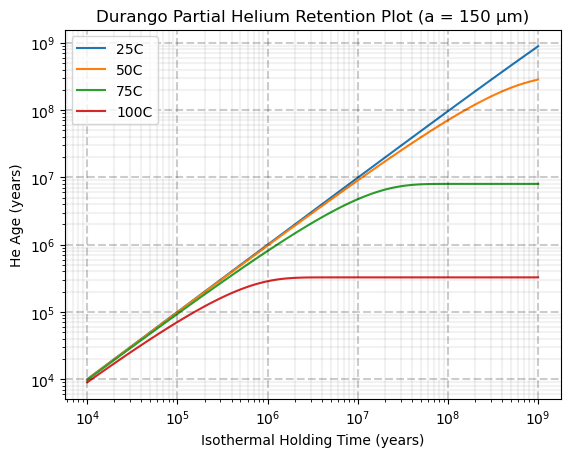

In [524]:
# Apatite He age plot

D0_a2 = (10**7.7)
Ea = 36200
T = 75 + 273



D_a2 = (D0_a2*np.exp(-Ea/(1.987*T)))


D0 = 10**1.5
a = 150/1E4
Ea = 33000



ts = 10**np.linspace(4,9,100)
Ts = np.array([25,50,75,100])+273
fig, ax = plt.subplots()
for T in Ts:
    Heage = []
    D_a2 = (D0/(a**2))*np.exp(-Ea/(1.987*T))
    for t in ts:
        Heage.append(wolfEQ(t=t, D_a2=D_a2))
    plt.loglog(ts,Heage,label = f'{T-273}C')

make_grid()
plt.xlabel('Isothermal Holding Time (years)')
plt.ylabel('He Age (years)')
plt.title('Durango Partial Helium Retention Plot (a = 150 µm)')
plt.legend()
plt.savefig('PRPapatite.jpg', dpi = 256)

Isothermal EQM AGE at 40C: 43378.0 Ma
Time to EQM Age at 40C: 329466.08 Ma
After 100.0 Ma at T = 40C, the helium age is: 97.22463240712779% of the holding time
Isothermal EQM AGE at 40C: 739.0 Ma
Time to EQM Age at 40C: 5616.55 Ma
After 100.0 Ma at T = 40C, the helium age is: 79.91986481289096% of the holding time


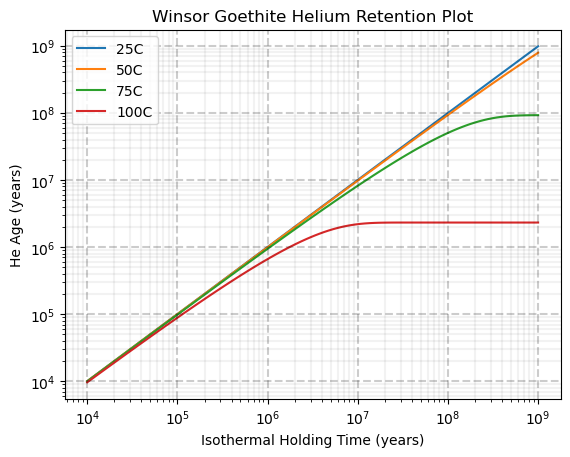

In [5]:
# Goethite He age plot

D0_a2 = np.exp(16.685)
Ea = 38033

ts = 10**np.linspace(4,9,100)
Ts = np.array([25,50,75,100])+273
fig, ax = plt.subplots()

for T in Ts:
    Heage = []
    D_a2 = D0_a2*np.exp(-Ea/(1.987*T))
    for t in ts:
        Heage.append(wolfEQ(t=t, D_a2=D_a2))
    plt.loglog(ts,Heage,label = f'{T-273}C')

    
plt.xlabel('Isothermal Holding Time (years)')
plt.ylabel('He Age (years)')
plt.title('Winsor Goethite Helium Retention Plot')
plt.legend()
make_grid()
plt.savefig('PRP_goethite.jpg', dpi = 256)

T = 273+40
D_a2 = D0_a2*np.exp(-Ea/(1.987*T))

print(f"Isothermal EQM AGE at {T-273}C: {np.round((0.0667*(1/D_a2))/(365.25*24*3600*1E6))} Ma")
print(f"Time to EQM Age at {T-273}C: {np.round((((1/D_a2)/(np.pi**2))/(365.25*24*3600*1E6))*5,2)} Ma")

t = 1E8

print(f"After {t/1E6} Ma at T = {T-273}C, the helium age is: {(wolfEQ(t= t, D_a2=D_a2)/t)*100}% of the holding time")



D0 = 10**1.5
Ea = 33000
a = 0.01

D_a2 = D0*np.exp(-Ea/(1.987*T))/(a**2)

print(f"Isothermal EQM AGE at {T-273}C: {np.round((0.0667*(1/D_a2))/(365.25*24*3600*1E6))} Ma")
print(f"Time to EQM Age at {T-273}C: {np.round((((1/D_a2)/(np.pi**2))/(365.25*24*3600*1E6))*5,2)} Ma")
print(f"After {t/1E6} Ma at T = {T-273}C, the helium age is: {(wolfEQ(t= t, D_a2=D_a2)/t)*100}% of the holding time")

Isothermal EQM AGE at 25C: 26.0 hr
Time to EQM Age at 25C: 196.7 hrs


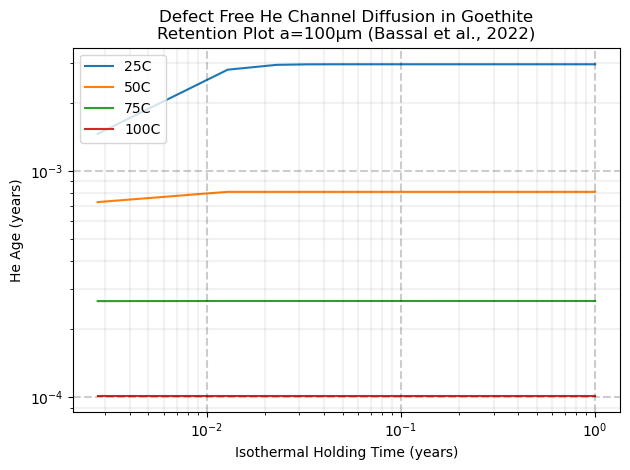

In [541]:
D0 = 13.4E-4 #cm^2/s
Ea = 0.43*96485 #J
a = 100/1E4 # cm

#ts = 10**np.linspace(4,9,100)
ts = np.linspace(1/365,1,100)
Ts = np.array([25,50,75,100])+273
fig, ax = plt.subplots()

for T in Ts:
    Heage = []
    D_a2 = (D0/(a**2))*np.exp(-Ea/(8.314*T))
    for t in ts:
        Heage.append(wolfEQ(t=t, D_a2=D_a2))
    plt.loglog(ts,Heage,label = f'{T-273}C')

    
plt.xlabel('Isothermal Holding Time (years)')
plt.ylabel('He Age (years)')
plt.title('Defect Free He Channel Diffusion in Goethite\nRetention Plot a=100µm (Bassal et al., 2022)')
plt.legend()
make_grid()
plt.tight_layout()
plt.savefig('PRP_goethite.jpg', dpi = 256)

T = 298
D_a2 = (D0/(a**2))*np.exp(-Ea/(8.314*T))

print(f"Isothermal EQM AGE at {T-273}C: {np.round((0.0667*(1/D_a2))/3600)} hr")
print(f"Time to EQM Age at {T-273}C: {np.round((((1/D_a2)/(np.pi**2))/3600)*5,2)} hrs")


In [537]:
(13.6E-4/np.exp(1.3))**(1/2)


0.01925209699036074

In [139]:
D0_a2 = (10**7.7)
Ea = 36200
T = 75 + 273

D_a2 = (D0_a2*np.exp(-Ea/(1.987*T)))

print(f"Isothermal EQM AGE at {T-273}C: {np.round((0.0667*(1/D_a2))/(365.25*24*3600*1E6),2)} Ma")
print(f"Time to EQM Age at {T-273}C: {np.round((((1/D_a2)/(np.pi**2))/(365.25*24*3600*1E6))*5,2)} Ma")
print(wolfEQ(t=3E6, D_a2=D_a2)/1E6)


Isothermal EQM AGE at 75C: 2.3 Ma
Time to EQM Age at 75C: 17.44 Ma
1.393693961807515


NameError: name 'time_matrix' is not defined

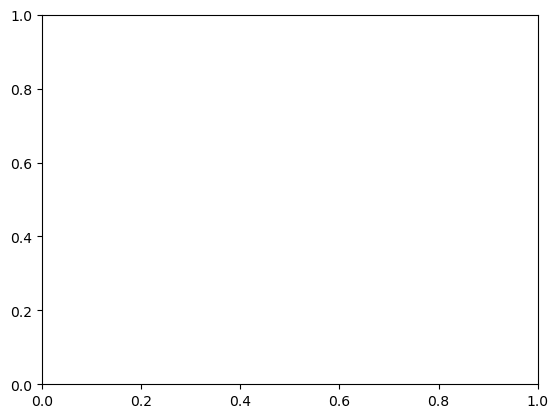

In [123]:
Tc = np.linspace(20,100,100)
t = np.linspace(1,1001,200)*1E6
PR_matrix = np.zeros((100,200))

D0_a2 = np.exp(17.775)
Ea = 38852


for i, ti in enumerate(Tc):
    D_a2 = D0_a2*np.exp(-Ea/(1.987*(ti+273)))
    for j, dj in enumerate(t):
        PR_matrix[i,j] = wolfEQ(t=dj, D_a2=D_a2)
        
fig, ax = plt.subplots()
cax = ax.imshow(PR_matrix)#, extent = [1,100,20,1000], origin = 'lower', aspect = 1/10, cmap = 'RdYlGn_r')#,  norm=mpl.colors.LogNorm(vmin=15, vmax=1440))
#ax.xticks(np.linspace(1,150,5),np.linspace(1,150,5))
cbar = fig.colorbar(cax)#, ticks=[15, 30, 60, 120, 600, 1440])
#cbar.ax.set_yticklabels(['15', '30', '60', '120', '600', '1440'])
cbar.set_label('%')
ax.set_xlabel('Glass Thickness in Microns')
ax.set_ylabel('Temperature (Celcius)')
#ax.set_title('Timescales to Degas 99% of Helium in a Fused Silica Tube\n')
ax.set_title('Difference in result due to geometric factor\n')
#plt.savefig('difference_in_geometric_form.jpg', dpi = 256)
plt.show()

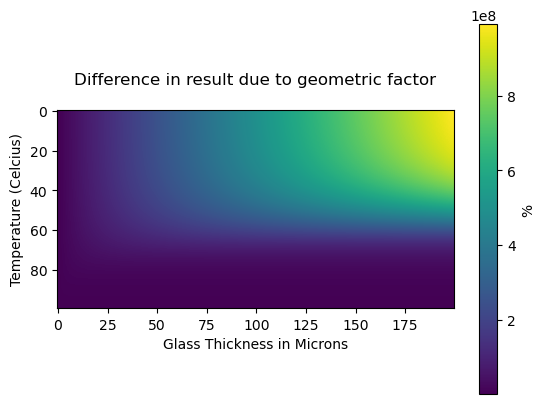

In [124]:
fig, ax = plt.subplots()
cax = ax.imshow(PR_matrix)#, extent = [1,100,20,1000], origin = 'lower', aspect = 1/10, cmap = 'RdYlGn_r')#,  norm=mpl.colors.LogNorm(vmin=15, vmax=1440))
#ax.xticks(np.linspace(1,150,5),np.linspace(1,150,5))
cbar = fig.colorbar(cax)#, ticks=[15, 30, 60, 120, 600, 1440])
#cbar.ax.set_yticklabels(['15', '30', '60', '120', '600', '1440'])
cbar.set_label('%')
ax.set_xlabel('Glass Thickness in Microns')
ax.set_ylabel('Temperature (Celcius)')
#ax.set_title('Timescales to Degas 99% of Helium in a Fused Silica Tube\n')
ax.set_title('Difference in result due to geometric factor\n')
#plt.savefig('difference_in_geometric_form.jpg', dpi = 256)
plt.show()


[0.0002264896562956308, 0.002275082738170244, 0.003208693719008897, 0.003925832376665782, 0.004530558300114873, 0.00506334598833586, 0.005544992885971818, 0.0059878675899635156, 0.00640003500333353, 0.00678710006034083, 0.007153145346994768, 0.007501253871281439, 0.00783382143969739, 0.008152753714263359, 0.008459596071909077, 0.008755622316318889, 0.009041897137406633, 0.009319321231962758, 0.009588664628869176, 0.00985059178209018, 0.010105680788379747, 0.010354438328375558, 0.010597311439758955, 0.01083469690669404, 0.01106694883016379, 0.01129438479226096, 0.011517290921020884, 0.011735926086376329, 0.01195052540275463, 0.012161303173412342, 0.012368455381554557, 0.012572161810695266, 0.012772587859551215, 0.012969886103592903, 0.013164197645180035, 0.013355653286247255, 0.013544374551239045, 0.013730474583023716, 0.013914058930548007, 0.014095226243804354, 0.014274068889102869, 0.014450673495541286, 0.014625121441848944, 0.014797489291368706, 0.014967849181773537, 0.01513626917514

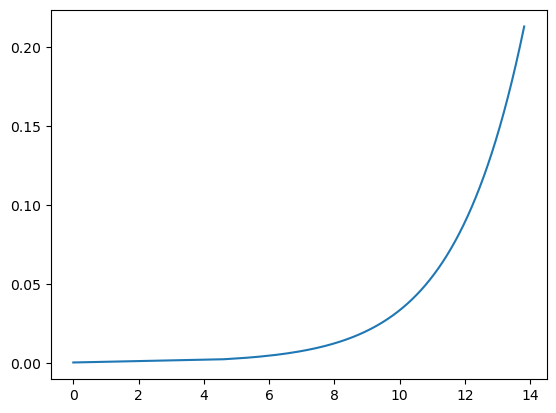

In [147]:
t = np.linspace(10**0,10**6,10000) #seconds

D0_a2 = (10**7.7)
Ea = 36200
T = 220 + 273

D_a2 = (D0_a2*np.exp(-Ea/(1.987*T)))
F = []
for ti in t:
    F.append(Forward_Diffuse(D_a2*ti))
tp = [0]+t.tolist()[:-1]
td = t-tp

Fps = np.array([0] + F[:-1])
Fd = np.array(F) - Fps
print(F[:100])
print(t[:100])
plt.plot(np.log(t), F)

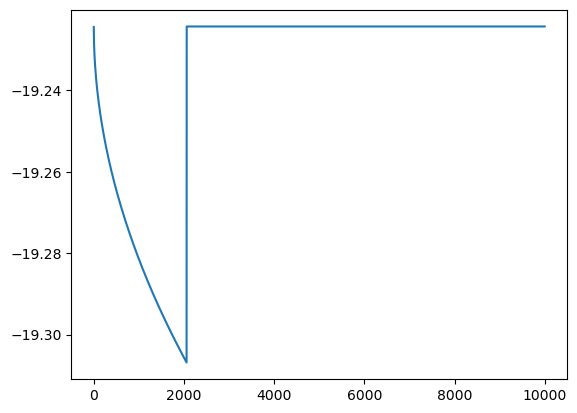

In [120]:
plt.plot(np.log(InvertFrequencyFactor1(td, np.array(F))))

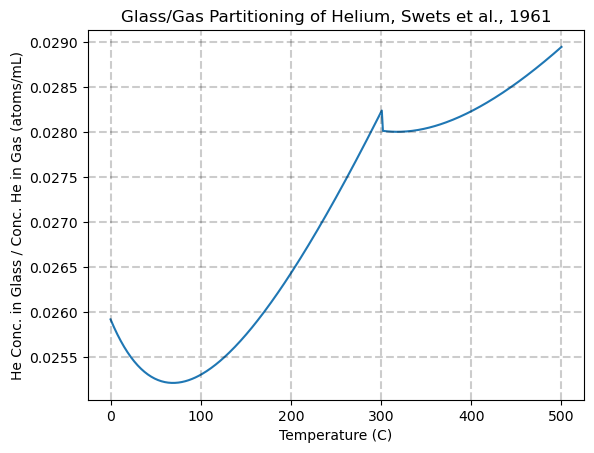

In [3]:
def swets_S(T):
    """Returns Permeability of fused Silica in units: mol/cm/s/atm for a given T in Kelvin"""
    if T >= 574: #573
        DEa = 6613 # factor of 4 to convert from g Helium to moles
        SEa = -1174
        DFF = 7.40E-4
        SFF = 1.28E17
    else:
        DEa = 5580
        SEa = -680
        DFF = 3.04E-4
        SFF = 1.99E17
       
    D = DFF*np.exp(-DEa/(Rcal*T))
    S = SFF*np.exp(-SEa/(Rcal*T)) # K units: atom/cm/s/dP atm/
    #print(f"Solubility at T = {T-273}C: {S} atoms/cm3/atm")
    #print(f"Diffusivity at T = {T-273}C: {D} cm2/s")
    #print(f"Permeation at T = {T-273}C in mol/cm/s/atm: {D*S}")
    K = D*S#/6.022E23 #units: mol/cm/s/atm
    return S

Ts = np.linspace(0,500,400) + 273
NDgas = 1/(Ratoms*Ts) # 1 atm, per cc
Ss = []

#print(NDgas)
fig, ax = plt.subplots()
for T in Ts:
    Ss.append(swets_S(T))
NDglass = np.array(Ss)
#print(NDglass)
plt.plot(Ts-273,NDglass/NDgas)
plt.title('Glass/Gas Partitioning of Helium, Swets et al., 1961')
plt.xlabel('Temperature (C)')
plt.ylabel('He Conc. in Glass / Conc. He in Gas (atoms/mL)')
make_grid()
plt.savefig('Helium_Partitioning500.jpg', dpi = 256)

In [121]:
print(D_a2)
InvertFrequencyFactor1(td, F)

4.477087938235285e-09


[4.47655698594695e-09,
 4.471705070133255e-09,
 4.467350918520483e-09,
 4.464498067953892e-09,
 4.4621893950506745e-09,
 4.46019592532941e-09,
 4.458415360534176e-09,
 4.456791197142954e-09,
 4.455288267961e-09,
 4.453882907618081e-09,
 4.452558282353705e-09,
 4.451301909335966e-09,
 4.450104227185201e-09,
 4.448957719355933e-09,
 4.4478563494115926e-09,
 4.446795182362132e-09,
 4.445770122182609e-09,
 4.444777724691416e-09,
 4.4438150609114145e-09,
 4.442879615198403e-09,
 4.441969207898238e-09,
 4.441081935675908e-09,
 4.440216124818387e-09,
 4.439370294220904e-09,
 4.438543125709443e-09,
 4.437733439996334e-09,
 4.436940177016082e-09,
 4.436162379700847e-09,
 4.435399180491282e-09,
 4.434649790035592e-09,
 4.433913487661221e-09,
 4.433189613288083e-09,
 4.432477560526475e-09,
 4.431776770755611e-09,
 4.4310867280138475e-09,
 4.430406954573877e-09,
 4.429737007088158e-09,
 4.429076473222803e-09,
 4.428424968701432e-09,
 4.4277821347034776e-09,
 4.4271476355635034e-09,
 4.426521156731

In [1]:
for i in np.arange(3, 200):
    tdi = td[:i]
    Fdi = Fd[:i]
    print(FirstOrdInversion(tdi,Fdi,True))
    plt.show()

NameError: name 'np' is not defined

(1.3681278762888372e-06, 16.225811587608302)


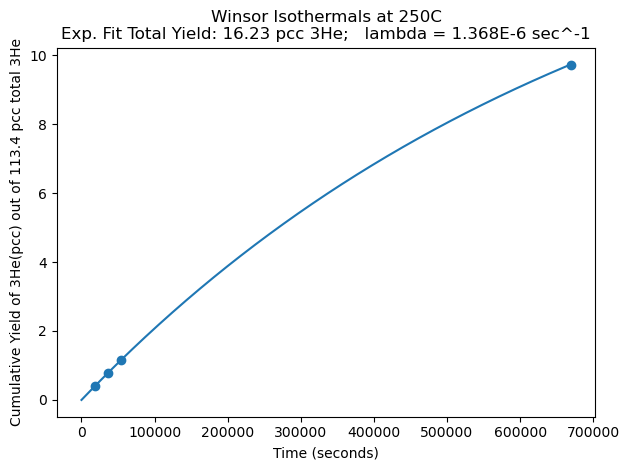

In [135]:
tg = np.array([300,300,300,10250])*60
Heg = np.array([0.402737006,0.376896744,0.373085304,8.576210633])


print(FirstOrdInversion(tg,Heg,True))
plt.title("Winsor Isothermals at 250C\nExp. Fit Total Yield: 16.23 pcc 3He;   lambda = 1.368E-6 sec^-1")
plt.xlabel("Time (seconds)")
plt.ylabel('Cumulative Yield of 3He(pcc) out of 113.4 pcc total 3He')
plt.tight_layout()
plt.savefig('WinsorFirstOrderFit.jpg', dpi = 256)

C:\Users\dashf\AppData\Local\Temp\ipykernel_26224\2060282239.py:3: RuntimeWarning: divide by zero encountered in log
  plt.plot(np.log(t),first_ord_pred)


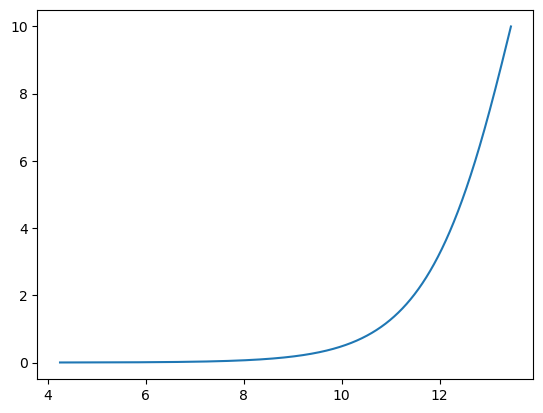

In [151]:
t = np.linspace(0,700000,10000)
first_ord_pred = 16.2258*(1-np.exp(-(1.368E-6*t)))
plt.plot(np.log(t),first_ord_pred)

(array([8., 6., 7., 5., 2., 3., 1., 1., 0., 1.]),
 array([0.        , 0.16188965, 0.3237793 , 0.48566895, 0.6475586 ,
        0.80944825, 0.97133789, 1.13322754, 1.29511719, 1.45700684,
        1.61889649]),
 <BarContainer object of 10 artists>)

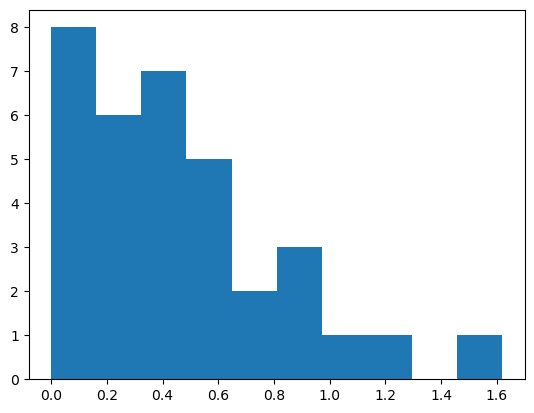

In [82]:
n0_nt=[0,
0.888638434,
0.313354093,
0.548602044,
0.371148106,
0.308961836,
0.273674228,
0.430582665,
0.5754603,
1.197568852,
0,
0,
0,
0.466869993,
0.403510856,
0.272443653,
0.284342318,
0.120599902,
1.618896491,
0.414820378,
0.635734571,
0.780956442,
0.703463796,
0.519567424,
0.559954846,
1.066222931,
0.060268626,
0.195763926,
0.89332803,
0.892887294,
0,
0.411620982,
0.467944639,
1.02323E-07]
plt.hist(n0_nt)

In [81]:
100*(np.max(NDglass/NDgas)-np.min(NDglass/NDgas))/np.min(NDglass/NDgas)

11.92616596867359

In [339]:
Ts[np.argmin(NDglass/NDgas)]-273

69.17293233082705

In [43]:
t = 3600 * 20 # * 365 * 
Dwa = 10**-12
Dhe = 10**-6
a = 0.025
print(Forward_Diffuse(Dhe*t/a**2))
print(a**2/Dhe)
print(Dhe*t/a**2)

print(Forward_Diffuse(Dwa*t/a**2))
print((a**2/Dwa)/(3600*24*365))
Dwa*t/a**2

1.0
625.0000000000001
115.19999999999997
0.0359875083170903
19.81861998985287


0.00011519999999999997

In [3]:
def tube_FDM(T1,T2,a,b):
    """
    CYLINDRICAL:
    Simulates concentration profile with a Forward Time Centered Space 
    Finite Difference Model for diffusion
    Let T2 and T2 be temperatures in celcius that define the initial 
    EQM steady state concentration profile. If T1 is a string
    (such as 'a') then the initial concentration is 0 throughout.
    t and x are the temporal duration and spatial extent (tube thickness) of 
    the simulation respectively in seconds and cm. 
    dx is 1 micron, while dt is calculated to stabilize
    the simulation
    """
    
    Fos = [0.01,0.1,1]
    colors = ['Red', 'Orange','Green', 'Blue','Violet']
    
    
    D = swets('D',T2+273) 
    S2 = swets('S',T2+273)
    dx = 1/1E4
    dt = 0.5*(dx**2)/D #0.5 is upper bound for stability
    xi = np.arange(0,x,dx)
    
    c_inner = (S2*(Ratoms*(T2+273))) # inner boundary condition at new temp in terms of glass/air partitioning
    
    t_stops = [] # times to stop and record concentration profile
    for Fo in Fos:
        t_stops.append((Fo*(xi[-1]**2))/D)
    t_stops.reverse()
    t_stop = t_stops.pop()
    
    print(f"For Diffusivity of {D} cm^2/s and dx = {round(dx*1E4,2)}, dt is set at {dt} seconds")
    
    
    if type(T1) in [int,float]:
        S1 = swets('S',T1+273)
        c1 = (S1*(Ratoms*(T1+273)))
        nglass = n0/(1+(((S*2*Ratoms*T/((a**2)*np.log(a/b))) *((0.5*a**2*(np.log(b/a)+0.5))-((b**2)/4)))**-1)) #eqn 2.46
        ngas = n0-nglass
        h = 3 # arbitrary, cancels
        c = (S*ngas*Ratoms*T/(np.pi*(a**2)*h))*(np.log(r/b)/np.log(a/b)) # eqn 2.42
        c = (xi/np.max(xi))*c1 # initial condition in terms of glass/air partitioning
        
    else:
        c = np.zeros_like(xi) # 0 initial condition throughout
        c1 = 0
        
    plt.plot(xi*1E4, c, linestyle = '--', color = 'Black', label = f"t = 0 minutes", alpha = 0.5)
    c[-1] = c_inner
    current_t = 0
    steps = 0
    delta_c = ((D*dt)/(dx**2)) * (c[:-2]-(2*c[1:-1])+c[2:])
    color_count = 0
    while t_stop:
        steps += 1
        current_t += dt
        c[1:-1] += delta_c # update concentrations
        c[0] = 0 # Enforce outer boundary condition
        c[-1] = c_inner # Enforce inner boundry conditions
        delta_c = ((D*dt)/(dx**2)) * (c[:-2]-(2*c[1:-1])+c[2:])
        if current_t >= t_stop:
            plt.plot(xi*1E4, c, color = colors[color_count], linewidth = 2, label = f"Fo = {Fos[color_count]}, t = {round(current_t/60,1)} minutes")
            print(f"t = {t_stop/60}, atoms = {np.sum(c)}")
            if len(t_stops):
                t_stop = t_stops.pop()
            else:
                t_stop = 0
            color_count += 1
    print(f"Simulation finished after {steps} steps")
    plt.plot(xi*1E4, (xi/np.max(xi))*c1, linestyle = '--', color = 'Black', alpha = 0.5)
    plt.plot(xi*1E4, (xi/np.max(xi))*c_inner, linestyle = ':', color = 'Black', label = f"EQM for T = {T2}°C", alpha = 0.8)
    #plt.scatter([0,xi[-1]*1E4,xi[-1]*1E4],[c[0],c[-1],c1], color = 'Black', alpha = 0.5)
    plt.xlabel('Distance from Vacuum (microns)')
    plt.ylabel('He Concentration Ratio (Glass/Gas, atoms/mL)')
    plt.title(f'He Concentration Profile Evolution after {round(current_t/60,1)} minutes at {T2}°C')
    plt.legend()
tube_FDM(T1 = 300, T2 = 100, a=0.03, b = 0.05)
plt.savefig('FDM_cyl1.jpg', dpi = 256)

NameError: name 'x' is not defined

For Diffusivity of 1.6335942310411268e-07 cm^2/s and dx = 1.0, dt is set at 0.030607355884290716 seconds
t = 0.4040273001245989, atoms = 2.7510242786545307
t = 4.040273001245989, atoms = 2.6142636352518003
t = 40.40273001245989, atoms = 2.5267632383391065
Simulation finished after 79202 steps


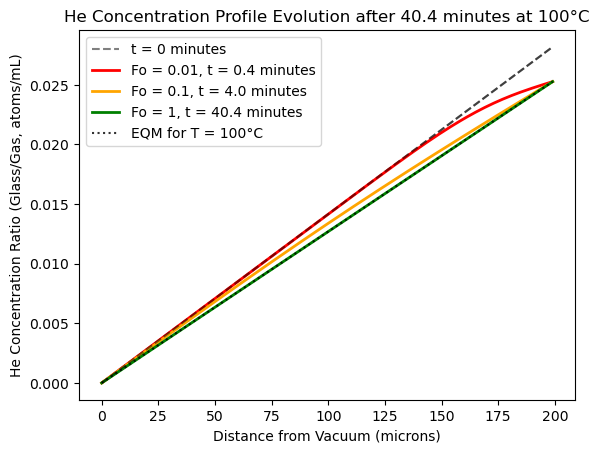

In [417]:
def tube_FDM(T1,T2,x):
    """
    Simulates concentration profile with a Forward Time Centered Space 
    Finite Difference Model for diffusion
    Let T2 and T2 be temperatures in celcius that define the initial 
    EQM steady state concentration profile. If T1 is a string
    (such as 'a') then the initial concentration is 0 throughout.
    t and x are the temporal duration and spatial extent (tube thickness) of 
    the simulation respectively in seconds and cm. 
    dx is 1 micron, while dt is calculated to stabilize
    the simulation
    """
    
    Fos = [0.01,0.1,1]
    colors = ['Red', 'Orange','Green', 'Blue','Violet']
    
    
    D = swets('D',T2+273) 
    S2 = swets('S',T2+273)
    dx = 1/1E4
    dt = 0.5*(dx**2)/D #0.5 is upper bound for stability
    xi = np.arange(0,x,dx)
    
    c_inner = (S2*(Ratoms*(T2+273))) # inner boundary condition at new temp in terms of glass/air partitioning
    
    t_stops = [] # times to stop and record concentration profile
    for Fo in Fos:
        t_stops.append((Fo*(xi[-1]**2))/D)
    t_stops.reverse()
    t_stop = t_stops.pop()
    
    print(f"For Diffusivity of {D} cm^2/s and dx = {round(dx*1E4,2)}, dt is set at {dt} seconds")
    
    
    if type(T1) in [int,float]:
        S1 = swets('S',T1+273)
        c1 = (S1*(Ratoms*(T1+273)))
        c = (xi/np.max(xi))*c1 # initial condition in terms of glass/air partitioning
        
    else:
        c = np.zeros_like(xi) # 0 initial condition throughout
        c1 = 0
        
    plt.plot(xi*1E4, c, linestyle = '--', color = 'Black', label = f"t = 0 minutes", alpha = 0.5)
    c[-1] = c_inner
    current_t = 0
    steps = 0
    delta_c = ((D*dt)/(dx**2)) * (c[:-2]-(2*c[1:-1])+c[2:])
    color_count = 0
    while t_stop:
        steps += 1
        current_t += dt
        c[1:-1] += delta_c # update concentrations
        c[0] = 0 # Enforce outer boundary condition
        c[-1] = c_inner # Enforce inner boundry conditions
        delta_c = ((D*dt)/(dx**2)) * (c[:-2]-(2*c[1:-1])+c[2:])
        if current_t >= t_stop:
            plt.plot(xi*1E4, c, color = colors[color_count], linewidth = 2, label = f"Fo = {Fos[color_count]}, t = {round(current_t/60,1)} minutes")
            print(f"t = {t_stop/60}, atoms = {np.sum(c)}")
            if len(t_stops):
                t_stop = t_stops.pop()
            else:
                t_stop = 0
            color_count += 1
    print(f"Simulation finished after {steps} steps")
    plt.plot(xi*1E4, (xi/np.max(xi))*c1, linestyle = '--', color = 'Black', alpha = 0.5)
    plt.plot(xi*1E4, (xi/np.max(xi))*c_inner, linestyle = ':', color = 'Black', label = f"EQM for T = {T2}°C", alpha = 0.8)
    #plt.scatter([0,xi[-1]*1E4,xi[-1]*1E4],[c[0],c[-1],c1], color = 'Black', alpha = 0.5)
    plt.xlabel('Distance from Vacuum (microns)')
    plt.ylabel('He Concentration Ratio (Glass/Gas, atoms/mL)')
    plt.title(f'He Concentration Profile Evolution after {round(current_t/60,1)} minutes at {T2}°C')
    plt.legend()
tube_FDM(T1 = 300, T2 = 100, x=0.02)
plt.savefig('FDM_diff_prof.jpg', dpi = 256)

In [ ]:
self.delta_c = ((self.D*self.dt)) * (((self.c[:-2]-(2*self.c[1:-1])+self.c[2:])/(self.dr**2))+((1/self.r[1:-1])*(self.firstderiv)))
self.D*self.firstderiv*self.dt*np.pi*self.r[1:-1]*2*self.h
self.out -= self.J[0]+((self.J[0]-self.J[1])-((2*self.J[1])-(self.J[0]+self.J[2]))/2)
self.ngas += self.J[-1]+((self.J[-1]-self.J[-2])-((2*self.J[-2])-(self.J[-1]+self.J[-3]))/2)

Assuming all standards analyzed had 157.5 nCCSTP 4He and 3.57 pCCSTP 3He


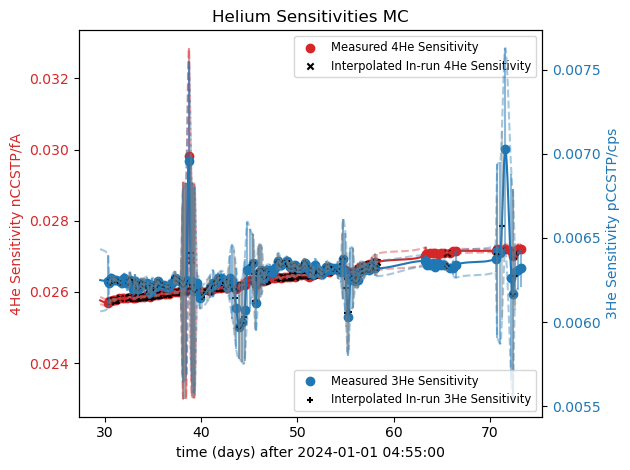

"\nfor i, T in enumerate(TempKelvin[1:]):\n    workingBlank.n0 = workingBlank.nt\n    workingBlank.out = 0\n    holdtime = TimeSeconds[i+1]\n    coolingtime = coldtimes[i+1]\n    workingBlank.hold_T(T, holdtime)\n    workingBlank.cool(t = (coolingtime-holdtime)-60)\n    workingBlank.record_sim('Measurement', T=T, t = holdtime, m = m[i+1], n0 = workingBlank.n0, nt = workingBlank.nt)\n    err.append(((workingBlank.n0-workingBlank.nt)-m[i+1])/m[i+1])\n    \n    #sulfurBlank.cool(60, record = False)\n    #tossed += sulfurBlank.out\n    #sulfurBlank.record_sim('Pumped Away', T=sulfurBlank.T, t = 60, m = sulfurBlank.out, n0 = sulfurBlank.n0, nt = sulfurBlank.nt)\n    #sulfurBlank.n0 = sulfurBlank.nt\n    #sulfurBlank.out = 0\n"

In [35]:
class permeation_sim:
    
    def __init__(self, a, b, n0, cooling_func, T=24+273, He = 4, EQMshortcut = False):
        """Where cooling func is a function with two arguements, T in Kelvin dt in seconds, that outputs the new T in Kelvin after dt seconds"""
        self.a = a
        self.b = b
        self.n0 = n0
        self.nt = n0
        self.He = str(He)
        self.cooling_func = cooling_func
        self.dr = (self.b-self.a)/25
        self.G = 2/(np.log(self.b/self.a)*(self.a**2))
        self.r = np.arange(self.a,self.b,self.dr)
        #if round(self.r[-1], len(str(self.b).split('.')[1])) != self.b:
        if round(self.r[-1], 4) != round(self.b,4):
            #print("ADDED END SPATIAL DOMAIN")
            #print(f"self.b = {self.b} r[-1] = {self.r[-1]}")
            self.r = np.append(self.r,self.b)
            #print(self.r[1:]-self.r[:-1])
        #print(self.r)    
        self.T = T
        self.S = swets('S',self.T)
        self.D = swets('D',self.T)
        self.K = swets('K',self.T)
        if self.He == '3':
            self.S *= Jones('S',self.T)
            self.D *= Jones('D', self.T)
            self.K *= Jones('K', self.T)
        self.nglass = self.nt/(1+(((self.S*2*Ratoms*self.T/((self.a**2)*np.log(self.a/self.b))) *((0.5*self.a**2*(np.log(self.b/self.a)+0.5))-((self.b**2)/4)))**-1)) #eqn 2.46
        #print(self.nglass)
        self.ngas = self.nt-self.nglass
        self.h = 1 # arbitrary, cancels
        self.c = (self.S*self.ngas*Ratoms*self.T/(np.pi*(self.a**2)*self.h))*(np.log(self.r/self.b)/np.log(self.a/self.b)) # eqn 2.42
        self.out = 0
        self.reportmatrix = np.array([['Initial', self.T-273, 0, 0, self.n0, self.nt, 0]])
        self.dt = 0.5*(self.dr**2)/self.D #0.5 is upper bound for stability
        self.dout = -self.D*(((self.c[-1]-self.c[-3])/(2*self.dr))+((self.c[-1]-(2*self.c[-2])+self.c[-3])/(2*self.dr)))*self.dt*np.pi*self.b*2*self.h #7.1b * dt * cylinder surface area (no top/bottom )
        self.dngas = -self.D*(((self.c[2]-self.c[0])/(2*self.dr))-((self.c[0]-(2*self.c[1])+self.c[2])/(2*self.dr)))*self.dt*np.pi*self.a*2*self.h #7.1a * dt * cylinder surface area (no top/bottom )
        #print(f"Sim Out: {self.dout/self.dt}; Sim in glass: {self.dngas/self.dt}")
        #print(f"Ideal Flux: {-self.G*self.K*self.n0*Ratoms*self.T}")
        self.firstderiv = (self.c[2:]-self.c[:-2])/(2*self.dr)
        self.J = -self.D*self.firstderiv*self.dt*np.pi*self.r[1:-1]*2*self.h
        #print(f"In: {self.J[0]/self.dt}, Out: {self.J[-1]/self.dt}")
        self.EQMshortcut = EQMshortcut
    def record_sim(self, Type, T, t, m, n0, nt):
        appK =  np.log(nt/n0)/(-self.G*t*Ratoms*T)
        self.reportmatrix = np.append(self.reportmatrix, np.array([[Type, T-273, t/60, m, n0, nt, appK]]), 0)
        
    def hold_T(self, T, t, record = True):
        self.T = T
        self.t_count = 0
        self.t_remain = t
        self.D = swets('D', self.T)
        self.S = swets('S', self.T)
        self.K = swets('K', self.T)
        if self.He == '3':
            self.D *= Jones('D', self.T)
            self.S *= Jones('S',self.T)
            self.K *= Jones('K',self.T) 
        if self.EQMshortcut:
            self.t_EQM = 1*((self.b-self.a)**2)/self.D
        else: 
            self.t_EQM = t + 60 # Never go to analytical, steady state eqns
        self.dt = 0.5*(self.dr**2)/self.D #0.5 is upper bound for stability
        while self.t_remain > 0 and self.t_count < self.t_EQM:
            if self.t_remain < self.dt:
                self.dt = self.t_remain
            self.t_count += self.dt
            self.t_remain -= self.dt
            self.c_inner = self.S*self.ngas*Ratoms*self.T/(np.pi*(self.a**2)*self.h)
            self.inxs = self.c[0]-self.c_inner # Enforce inner boundry conditions
            self.c[0] = self.c_inner
            self.ngas += self.inxs*2*np.pi*self.a*self.dr*self.h
            self.firstderiv = (self.c[2:]-self.c[:-2])/(2*self.dr)
            #self.J = -self.D*self.firstderiv*self.dt*np.pi*self.r[1:-1]*2*self.h
            self.delta_c = ((self.D*self.dt)) * (((self.c[:-2]-(2*self.c[1:-1])+self.c[2:])/(self.dr**2))+((1/self.r[1:-1])*(self.firstderiv)))
            self.dout = -self.D*(((self.c[-1]-self.c[-3])/(2*self.dr))+((self.c[-1]-(2*self.c[-2])+self.c[-3])/(2*self.dr)))*self.dt*np.pi*self.b*2*self.h #7.1b * dt * cylinder surface area (no top/bottom )
            self.dngas = -self.D*(((self.c[2]-self.c[0])/(2*self.dr))-((self.c[0]-(2*self.c[1])+self.c[2])/(2*self.dr)))*self.dt*np.pi*self.a*2*self.h #7.1a * dt * cylinder surface area (no top/bottom )
            self.out += self.dout
            #print(self.delta_c)
            #print()
            self.ngas -= self.dngas
            #print(f"Out old: {self.J[-1]}; New: {self.dout}\nTo Glass Old: {self.J[0]}; New: {self.dngas}")
            self.c[1:-1] += self.delta_c
        total = self.out+self.ngas+np.sum(self.c*self.dr*self.h*self.r*2*np.pi) # Normalize to 
        self.c /= (total/self.n0)
        self.out /= (total/self.n0)
        self.ngas /= (total/self.n0)
        self.nt = self.n0 - self.out
        #print(f"Sum after {round(self.t_count/60)} minutes at {self.T-273}C: {self.out+self.ngas+np.sum(self.c*self.dr*self.h*self.r*2*np.pi)}")
        if self.t_remain > 0:
            print(f'Is it EQM at T = {self.T-273}C after {self.t_count/60}?')
            EQMR = np.exp(-self.G*self.T*Ratoms*self.K*self.t_remain)
            #print(f"EQMR: {EQMR}")
            permout = self.nt*(1-EQMR)
            self.out += permout
            self.nt *= EQMR
            self.nglass = self.nt/(1+(((self.S*2*Ratoms*self.T/((self.a**2)*np.log(self.a/self.b))) *((0.5*self.a**2*(np.log(self.b/self.a)+0.5))-((self.b**2)/4)))**-1)) #eqn 2.46
            self.ngas = self.nt-self.nglass
            self.c = (self.S*self.ngas*Ratoms*self.T/(np.pi*(self.a**2)*self.h))*(np.log(self.r/self.b)/np.log(self.a/self.b)) # eqn 2.42
        """        print(f"After holding at {self.T-273}C for {(self.t_count+self.t_remain)/60} minutes: Out = {self.out}\tn0 = {self.n0}\tnt = {self.nt}\tnglass = {np.sum(self.r*2*self.dr*self.h*np.pi*self.c)}\tngas = {self.ngas}")
        self.nglass = self.nt/(1+(((self.S*2*Ratoms*self.T/((self.a**2)*np.log(self.a/self.b))) *((0.5*self.a**2*(np.log(self.b/self.a)+0.5))-((self.b**2)/4)))**-1)) #eqn 2.46
        self.ngas_nominal = self.nt-self.nglass
        self.c_nominal = (self.S*self.ngas_nominal*Ratoms*self.T/(np.pi*(self.a**2)*self.h))*(np.log(self.r/self.b)/np.log(self.a/self.b)) # eqn 2.42
        plt.plot(self.r, self.c, color = 'Red', label = 'Recorded Profile')
        plt.plot(self.r, self.c_nominal, linestyle = '--', label = 'Nominal EQM Profile')
        plt.legend()
        plt.show()"""
        if record:
            self.record_sim('Hold T', T=self.T, t = self.t_count+self.t_remain, m = self.n0-self.nt, n0 =self.n0, nt = self.nt)
            
    def cool(self, t, record = True):
        self.t_count = 0
        self.m = 0
        self.t_remain = t
        while self.t_remain > 0 and self.T > 273+24.5:
            self.dt = 0.5*(self.dr**2)/self.D #0.5 is upper bound for stability
            if self.t_remain < self.dt:
                self.dt = self.t_remain
            self.T = self.cooling_func(self.T, self.dt)
            self.D = swets('D',self.T)
            self.S = swets('S',self.T)
            self.K = swets('K', self.T)
            if self.He == '3':
                self.D *= Jones('D',self.T)
                self.S *= Jones('S',self.T)
                self.K *= Jones('K',self.T)
            self.t_count += self.dt
            self.t_remain -= self.dt
            self.c_inner = self.S*self.ngas*Ratoms*self.T/(np.pi*(self.a**2)*self.h)
            self.inxs = self.c[0]-self.c_inner # Enforce inner boundry conditions
            self.c[0] = self.c_inner
            self.ngas += self.inxs*2*np.pi*self.a*self.dr*self.h
            self.firstderiv = (self.c[2:]-self.c[:-2])/(2*self.dr)
            #self.J = -self.D*self.firstderiv*self.dt*np.pi*self.r[1:-1]*2*self.h
            self.delta_c = ((self.D*self.dt)) * (((self.c[:-2]-(2*self.c[1:-1])+self.c[2:])/(self.dr**2))+((1/self.r[1:-1])*(self.firstderiv)))
            self.dout = -self.D*(((self.c[-1]-self.c[-3])/(2*self.dr))+((self.c[-1]-(2*self.c[-2])+self.c[-3])/(2*self.dr)))*self.dt*np.pi*self.b*2*self.h #7.1b * dt * cylinder surface area (no top/bottom )
            self.dngas = -self.D*(((self.c[2]-self.c[0])/(2*self.dr))-((self.c[0]-(2*self.c[1])+self.c[2])/(2*self.dr)))*self.dt*np.pi*self.a*2*self.h #7.1a * dt * cylinder surface area (no top/bottom )
            self.out += self.dout
            self.m += self.dout
            self.ngas -= self.dngas
        total = self.out+self.ngas+np.sum(self.c*self.dr*self.h*self.r*2*np.pi) # Normalize to 
        self.c /= (total/self.n0)
        self.out /= (total/self.n0)
        self.ngas /= (total/self.n0)
        self.nt = self.n0 - self.out
        print(f"After Cooling for {self.t_count/60} minutes: Total: {self.out+self.ngas+np.sum(self.c*self.dr*self.h*self.r*2*np.pi)}, Out = {self.out}\tn = {self.n0}\tnt = {self.nt}\tnglass = {np.sum(self.r*2*self.dr*self.h*np.pi*self.c)}\tngas = {self.ngas}")
        
        if self.t_remain > 0:
            simT = self.t_count
            recnt = self.nt
            self.hold_T(T = 273+24, t = self.t_remain, record = False)
            self.m += (recnt-self.nt)
            self.t_remain += simT        
        if record:
            self.record_sim('Cooling', T=self.T, t = self.t_count+self.t_remain, m = self.m, n0 =self.n0, nt = self.nt)
        
    def generate_report(self, name = 'ampoule_permeation_out'):
        self.columns = ['Type', 'T (K)', 't(minutes)', 'm', 'n0', 'nt', 'Apparent K']
        self.reportDF = pd.DataFrame()
        for i, col in enumerate(self.columns):
            self.reportDF[col] = self.reportmatrix[:,i]
        self.reportDF.to_csv(name+'.csv')
        print(f"Generated report: {name+'.csv'}")
        
    def reset(self, n0, T):
        self.n0 = n0
        self.nt = n0
        self.T = T
        self.S = swets('S',self.T)
        if self.He == '3':
            self.S*=Jones('S',self.T)
        self.nglass = self.nt/(1+(((self.S*2*Ratoms*self.T/((self.a**2)*np.log(self.a/self.b))) *((0.5*self.a**2*(np.log(self.b/self.a)+0.5))-((self.b**2)/4)))**-1)) #eqn 2.46
        self.ngas = self.nt-self.nglass
        self.c = (self.S*self.ngas*Ratoms*self.T/(np.pi*(self.a**2)*self.h))*(np.log(self.r/self.b)/np.log(self.a/self.b)) # eqn 2.42
        self.out = 0
    
    def stabilize_profile(self):
        self.tauD = ((self.b-self.a)**2)/self.D 
        self.hold_T(self.T,self.tauD)
        self.c /= (self.nt/self.n0)
        self.nglass = np.sum(self.c*self.dr*self.h*self.r*2*np.pi)
        self.nt = self.n0
        self.ngas = self.nt-self.nglass
        self.out = 0
        
def extract_timesMC(dates, form = '%m/%d/%Y  %I:%M %p'):
    """Extracts exact times duration for each step using timestamps on MC"""
    times = [] # in seconds
    first = True
    for stri in dates: 
        try:
            time = datetime.strptime(stri, form)
        except:
            try:
                form = '%m/%d/%Y  %H:%M:%S'
                time = datetime.strptime(stri, form)
            except:
                try:
                    form = '%m/%d/%Y  %H:%M'
                    time = datetime.strptime(stri, form)
                except:
                    form = '%m/%d/%Y  %I:%M:%S %p'
                    time = datetime.strptime(stri, form)
        if first:
            oldtime = time
            #print(oldtime)
            first = False
        else:
            newtime = time
            times.append((newtime - oldtime).total_seconds())
            oldtime = newtime
    return np.array(times)

def sulfur_blank_cooling(T,dt):
    x = T - (273+24)
    dTdt = -(4.2911E-6*(x**2))-(1.8754E-3*(x))
    return T + (dTdt*dt)
            
def isoTwater_blank_cooling(T,dt):
    x = T - (273+24)
    dTdt = -(3.6006E-5*(x**2))-(4.4616E-4*(x))
    return T + (dTdt*dt)
    
def NovTube_blank_cooling(T,dt):
    x = T - (273+24)
    dTdt = -(2.21847E-5*(x**2))-(1.08220E-3*(x))
    return T + (dTdt*dt)

def goethite_cooling(T,dt):
    x = T - (273+24)
    dTdt = -(9.23081E-6*(x**2))-(7.74304E-4*(x))
    return T + (dTdt*dt)

def accumulate(v):
    vnew = [v[0]]
    for vnext in v[1:]:
        vnew.append(vnext+vnew[-1])
    return np.array(vnew)

def forward_permeate(t, lamb, n0):
    return(n0*(1-np.exp(-lamb*t)))

def forward_permeate1(t, lamb, n0):
    return((n0*(1-np.exp(-lamb*t[1])))-(n0*(1-np.exp(-lamb*t[0]))))

def KenColdInversion(t, He, covout = False, plot = True):
    """Returns n0 and lambda for a time series of cold permeations from a tube at a single temperature, requires 3 or 4 data points"""
    cumHe = accumulate(He)
    cumt = accumulate(t)
    lamb = 6E-5 # order of magnitude estimation
    print(cumHe)
    print(cumt)
    longt = np.linspace(0,cumt[-1],500)
    
    (out,covmat) = scipy.optimize.curve_fit(f = forward_permeate, xdata = cumt, ydata = cumHe, p0 = [lamb, He[0]/(1-np.exp(-lamb*t[0]))])
    if plot:
        plt.plot(longt, forward_permeate(longt, out[0], out[1]))
        plt.scatter(cumt, cumHe)
    if covout:
        return ((out[0],out[1]), covmat)
    return (out[0],out[1])

def KenColdInversion1(t, He, sigma, covout = False, plot = True):
    """Returns n0 and lambda for a time series of cold permeations from a tube at a single temperature, requires 3 or 4 data points"""
    lamb = 6E-5 # order of magnitude estimation
    cumHe = [0] + accumulate(He).tolist()
    cumt = [0] + accumulate(t).tolist()
    tinput = []
    for i in range(len(cumt) - 1):
        tinput.append([cumt[i],cumt[i+1]])
    print(np.array(tinput).T)
    print(len(He))
    print(forward_permeate1(tinput[0],lamb, He[0]/(1-np.exp(-lamb*t[0]))))
    longt = np.linspace(0,cumt[-1],500)
    (out,covmat) = scipy.optimize.curve_fit(f = forward_permeate1, xdata = np.array(tinput).T, ydata = He, sigma = sigma, p0 = [lamb, He[0]/(1-np.exp(-lamb*t[0]))])
    if plot:
        plt.plot(longt, forward_permeate(longt, out[0], out[1]))
        plt.scatter(cumt, cumHe)
    if covout:
        return ((out[0],out[1]), covmat)
    return (out[0],out[1])

diffname = "IrrWin0601bTube012624TC"
DIFFCELL = pd.read_csv(diffname+'.csv', header=None).to_numpy()
metadata = DIFFCELL[:,1]
coldtimes = np.array([0] + list(extract_timesMC(DIFFCELL[:,2])))

He = 3

He3 = DIFFCELL[:,4]
He4 = DIFFCELL[:,6]


Reducer = MCHeReducer('2024STDsMC.csv')

He3, He4, s3, s4 = Reducer.reduce(DIFFCELL, uncertainties=True, plot = True) 
plt.show()
if str(He) == '4':
    m = He4
    s = s4
if str(He) == '3':
    m = He3
    s = s3
metadata = DIFFCELL[:,1]
TimeSeconds = np.array([60*pull_number((str(datum).split(' ')[1]).split('_')[1]) for datum in metadata])
TempKelvin = np.array([273+pull_number(str(datum).split(' ')[2]) for datum in metadata])
coldtimes = np.array([0] + list(extract_timesMC(DIFFCELL[:,2])))

#He3[np.where(np.round(TempKelvin) == 150+273)[0][0]]*=0.9
#He4[np.where(np.round(TempKelvin) == 150+273)[0][0]]*=0.9

goeTube = permeation_sim(a = (0.0510)/2, b = (0.0800)/2, n0 = 100, cooling_func = goethite_cooling, He = He)
last_T = 0
ts = []
Hes = []
Ss = []
coldt = []
holdermat = np.array([[0,0,0],[0,0,0]])
"""
for i, T in enumerate(TempKelvin[1:]):
    if T < (130+273):
        if last_T >= (130 + 273):
            print('RESET!')
            goeTube.reset(n0 = 100, T = last_T)
        holdtime = TimeSeconds[i+1]
        ts.append(holdtime)
        coolingtime = coldtimes[i+1]
        coldt.append(coolingtime)
        #goeTube.hold_T(T, holdtime)
        #goeTube.cool(t = (coolingtime-holdtime)-60)
        #Hes.append(goeTube.n0-goeTube.nt)
        Hes.append(m[i+1])
        Ss.append(s[i+1])
        #goeTube.record_sim('Measurement', T=T, t = holdtime, m = m[i+1], n0 = goeTube.n0, nt = goeTube.nt)
        last_T = T
        goeTube.n0 = goeTube.nt
        goeTube.out = 0
    else:
        if len(ts)>2 and np.std(coldt) == 0:
            print(i)
            print(coldt)
            plt.scatter([0]+accumulate(ts).tolist(),[0]+accumulate(Hes).tolist())
            plt.errorbar(accumulate(ts), accumulate(Hes), accumulate(np.array(Ss)*2), linestyle = '')
            ((lam, n0fit), covmat) = KenColdInversion1(t = ts, He = np.array(Hes), sigma=Ss, covout = True)
            print(covmat)
            holdermat = np.append(holdermat, np.append(np.array([lam,n0fit]).reshape((2,1)),covmat,1), 0)
            plt.show()
            #goeTube.record_sim(f'AppK: {lam/(goeTube.G*Ratoms*last_T)}, n0 = {n0fit}', T=last_T, t = holdtime, m = m[i+1], n0 = goeTube.n0, nt = goeTube.nt)
        last_T = T
        ts = []
        Hes = []
        coldt = []
        Ss = []
pd.DataFrame(holdermat[2:]).to_csv('pythonExpFits.csv')
T_holds = [80, 85, 90, 95, 100, 105, 110, 115]
Hot_Hold = [120,180]
cold_hold = [25,40,60]
"""
#goeTube = permeation_sim(a = (0.0510)/2, b = (0.0800)/2, n0 = 100, cooling_func = goethite_cooling, He = He)
        
#goeTube.generate_report(diffname+str(He)+'HeSimVaryCool')
    
#workingBlank = permeation_sim(a = (0.0510)/2, b = (0.800)/2, n0 = np.sum(m[1:]), cooling_func = NovTube_blank_cooling, He = He)

tossed = 0
err = []
"""
for i, T in enumerate(TempKelvin[1:]):
    workingBlank.n0 = workingBlank.nt
    workingBlank.out = 0
    holdtime = TimeSeconds[i+1]
    coolingtime = coldtimes[i+1]
    workingBlank.hold_T(T, holdtime)
    workingBlank.cool(t = (coolingtime-holdtime)-60)
    workingBlank.record_sim('Measurement', T=T, t = holdtime, m = m[i+1], n0 = workingBlank.n0, nt = workingBlank.nt)
    err.append(((workingBlank.n0-workingBlank.nt)-m[i+1])/m[i+1])
    
    #sulfurBlank.cool(60, record = False)
    #tossed += sulfurBlank.out
    #sulfurBlank.record_sim('Pumped Away', T=sulfurBlank.T, t = 60, m = sulfurBlank.out, n0 = sulfurBlank.n0, nt = sulfurBlank.nt)
    #sulfurBlank.n0 = sulfurBlank.nt
    #sulfurBlank.out = 0
"""


In [38]:
DIFFCELL = pd.read_excel('MCEmptyTubeData.xlsx', 'MC Empty Tube OD1159 ID747', skiprows=1).to_numpy()[:7,1:]
DIFFCELL[:,2]

array([Timestamp('2023-11-20 01:20:07'), Timestamp('2023-11-20 02:44:04'),
       Timestamp('2023-11-20 03:58:39'), Timestamp('2023-11-20 05:52:54'),
       Timestamp('2023-11-20 07:07:33'), Timestamp('2023-11-20 08:23:50'),
       Timestamp('2023-11-20 10:17:46')], dtype=object)

In [48]:
def NovTube_blank_cooling(T,dt):
    x = T - (273+24)
    dTdt = -(2.21847E-5*(x**2))-(1.08220E-3*(x))
    return T + (dTdt*dt)

def sulfur_blank_cooling(T,dt):
    x = T - (273+24)
    dTdt = -(4.2911E-6*(x**2))-(1.8754E-3*(x))
    return T + (dTdt*dt)
            
def isoTwater_blank_cooling(T,dt):
    x = T - (273+24)
    dTdt = -(3.6006E-5*(x**2))-(4.4616E-4*(x))
    return T + (dTdt*dt)
    



#DIFFCELL = pd.read_excel('MCEmptyTubeData.xlsx', 'MC Empty Tube OD1159 ID747', skiprows=1).to_numpy()[:7,1:]
Paramsheet = pd.read_excel('simput.xlsx', None)
He = 4

for j, (label, page) in enumerate(Paramsheet.items()):
    sheet = page.to_numpy()
    name, b, a = label.split(' ')
    TempKelvin = sheet[:,0]+273
    hottime = sheet[:,1]
    coldtime = sheet[:,2]
    for He in [3,4]:
        simTube = permeation_sim(a = (float(a))/2, b = (float(b))/2, n0 = 1, cooling_func = [NovTube_blank_cooling, isoTwater_blank_cooling, sulfur_blank_cooling][j], He = He)
        simTube.stabilize_profile()
        for i, T in enumerate(TempKelvin):
            simTube.hold_T(T,hottime[i])
            if coldtime[i] > 1:
                simTube.cool(coldtime[i])
            simTube.record_sim('Measurement', T=T, t = hottime[i], m = simTube.out, n0 = simTube.n0, nt = simTube.nt)
            simTube.n0 = simTube.nt
            simTube.m = 0
            simTube.out = 0
        simTube.generate_report(f'{He}HeMC{name}')

After Cooling for 62.82441447461247 minutes: Total: 0.9999999999999999, Out = 0.037692359050049466	n = 1	nt = 0.9623076409499506	nglass = 0.015077216615352017	ngas = 0.9472304243345985
After Cooling for 20.81418078490521 minutes: Total: 0.959861594110887, Out = 0.002614236551216196	n = 0.9598615941108869	nt = 0.9572473575596707	nglass = 0.01498634736536761	ngas = 0.9422610101943032
After Cooling for 63.34906196878895 minutes: Total: 0.9508857415262493, Out = 0.04176530956521486	n = 0.9508857415262493	nt = 0.9091204319610344	nglass = 0.014278512192153828	ngas = 0.8948419197688806
After Cooling for 20.81418078490521 minutes: Total: 0.9033990836023651, Out = 0.0024550715554046408	n = 0.903399083602365	nt = 0.9009440120469604	nglass = 0.014088945368113972	ngas = 0.8868550666788465
After Cooling for 20.81418078490521 minutes: Total: 0.8949561621565985, Out = 0.0024281441334806446	n = 0.8949561621565985	nt = 0.8925280180231178	nglass = 0.013948027029301377	ngas = 0.8785799909938163
After Coo

C:\Users\dashf\AppData\Local\Temp\ipykernel_13256\1380851958.py:46: RuntimeWarning: invalid value encountered in scalar divide
  appK =  np.log(nt/n0)/(-self.G*t*Ratoms*T)
C:\Users\dashf\AppData\Local\Temp\ipykernel_13256\1380851958.py:46: RuntimeWarning: divide by zero encountered in scalar divide
  appK =  np.log(nt/n0)/(-self.G*t*Ratoms*T)
C:\Users\dashf\AppData\Local\Temp\ipykernel_13256\1380851958.py:46: RuntimeWarning: invalid value encountered in scalar divide
  appK =  np.log(nt/n0)/(-self.G*t*Ratoms*T)
C:\Users\dashf\AppData\Local\Temp\ipykernel_13256\1380851958.py:46: RuntimeWarning: divide by zero encountered in scalar divide
  appK =  np.log(nt/n0)/(-self.G*t*Ratoms*T)


After Cooling for 25.066666669212285 minutes: Total: 1.0, Out = 0.13219222858178573	n = 1	nt = 0.8678077714182143	nglass = 0.012461327744862801	ngas = 0.8553464436733516
After Cooling for 25.016666668001562 minutes: Total: 0.8678077714182143, Out = 0.11473731561323863	n = 0.8678077714182143	nt = 0.7530704558049757	nglass = 0.010813601469990738	ngas = 0.7422568543349849
After Cooling for 25.066666658734906 minutes: Total: 0.7530704558049757, Out = 0.09958010754542096	n = 0.7530704558049757	nt = 0.6534903482595547	nglass = 0.00938382632185081	ngas = 0.6441065219377039
After Cooling for 53.45000000530864 minutes: Total: 0.6534903482595547, Out = 0.09197023573820665	n = 0.6534903482595547	nt = 0.561520112521348	nglass = 0.008116827891971247	ngas = 0.5534032846293768
After Cooling for 25.233333332929764 minutes: Total: 0.561520112521348, Out = 0.07430093496591064	n = 0.561520112521348	nt = 0.4872191775554374	nglass = 0.006996582797075685	ngas = 0.48022259475836165
After Cooling for 25.08333

After Cooling for 24.81666666315866 minutes: Total: 0.38437409042196713, Out = 0.05611732371317119	n = 0.3843740904219671	nt = 0.3282567667087959	nglass = 0.005480251924778107	ngas = 0.3227765147840178
After Cooling for 44.73576355790822 minutes: Total: 0.32825676670879583, Out = 0.04926435048319939	n = 0.3282567667087959	nt = 0.2789924162255965	nglass = 0.004672849656191913	ngas = 0.27431956656940454
After Cooling for 24.94999999622811 minutes: Total: 0.27846867958618055, Out = 0.04067922732179882	n = 0.27846867958618055	nt = 0.23778945226438172	nglass = 0.0039699934125517426	ngas = 0.23381945885183003
After Cooling for 44.73576355790822 minutes: Total: 0.2377894522643817, Out = 0.03568716426203262	n = 0.23778945226438172	nt = 0.2021022880023491	nglass = 0.0033850153340502496	ngas = 0.19871727266829883
After Cooling for 25.08333332929757 minutes: Total: 0.20132154126928575, Out = 0.029410826045441225	n = 0.20132154126928575	nt = 0.17191071522384452	nglass = 0.002870193014499493	ngas =

In [108]:
a = 0.0850/2
b = 0.1350/2
L = b-a
VR = ((b**2)-(a**2))/(a**2)
print(VR)
print(L)

1.5224913494809684
0.025


In [49]:
Paramsheet = pd.read_excel('simput.xlsx', None)
He = 4

for j, (label, page) in enumerate(Paramsheet.items()):
    sheet = page.to_numpy()
    name, b, a = label.split(' ')
    print(f"{name}: a:{float(a)/2}, b:{float(b)/2}")

Empty: a:0.03735, b:0.05795
Water: a:0.02505, b:0.03775
Sulfur: a:0.026975, b:0.042675


Text(0.5, 0, 'Outer Diameter (µm)')

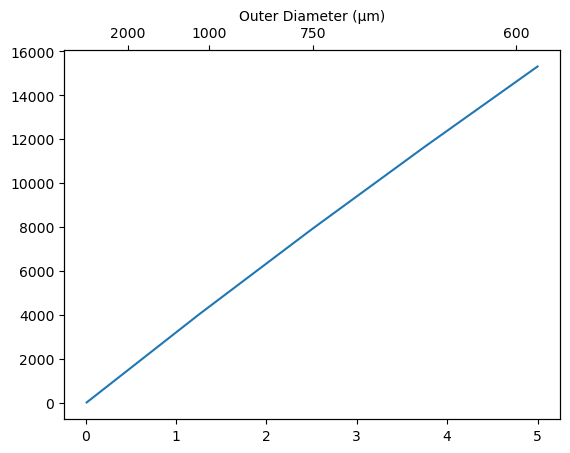

In [165]:
VR = np.linspace(0.01,5,5)
VP = (VR + 1)**0.5
L = 0.0175
#labelVR = np.array([0.1,1,5,10])
#labelVP = (labelVR + 1)**0.5
#labela = L/(-1+labelVP)
#labelb = L + labela

labelb = np.array([600,750,1000,2000])/2E4
labela = labelb-L
labelVR = ((labelb**2)-(labela**2))/(labela**2)


a = L/(-1+VP)
b = L + a
G = 2/((a**2)*np.log(b/a))

fig = plt.figure()
ax1 = fig.add_subplot(111)
ax2 = ax1.twiny()

ax1.plot(VR, G)

ax2.set_xticks(labelVR)
ax2.set_xlim(ax1.get_xlim())
ax2.set_xticklabels(np.round(labelb*2E4).astype(int))
ax2.set_xlabel('Outer Diameter (µm)')
#ax1.set_xlabel(r'$\frac{glass}{gas}$ Volume Ratio: $V_{glass/gas}$')
#ax1.set_ylabel(r'Apparent Diffusivity $\left(\frac{D}{a^2}\right)$')


In [ ]:
Ts
VR = np.linspace(0.01,20,200)
VP = (VR + 1)**0.5
fig, ax = plt.subplots()
for i, T in enumerate(Ts):
    #D = swets('D', T)
    S = swets('S', T)
    #K = swets('K', T)
    #tauP = 1/(G*Ratoms*K*T)
    #tauD = ((b-a)**2)/D
    tauR = S*Ratoms*T*VR*((-1+VP)/(1+VP))*(2/np.log(VP))
    
for T in Ts:
    D = swets('D', T)
    t = ((b-a)**2)/D 
    workingBlank = permeation_sim(a = a, b = b, n0 = 1, T = T, cooling_func = NovTube_blank_cooling, He = 4)
    workingBlank.hold_T(T,t)
    m_n0M.append(workingBlank.out/workingBlank.n0)
    m_n0A.append(T*swets('K',T)*G*Ratoms*t) # Constant Pressure

In [ ]:
#Ts = np.linspace(24,500,20)+273
Ts = np.array(24,120,300)+273
#G = 6000
aa = np.array([0.063,0.0747,0.0529,0.0487,0.085])/2 
#bb = aa*np.exp(2/(G*aa**2))
bb = np.array([0.096,0.1159,0.0835,0.0734,0.135])/2 
names = ['Empty Quad', 'Empty MC', 'Sulfur MC', 'Water MC', 'DAp Quad']
colmap = plt.cm.plasma_r
for j, i in enumerate([3,4]):#[3,0,1,2,4]):
    a = aa[i]
    b = bb[i]
    G = 2/(np.log(b/a)*(a**2))
    print(G)
    Vgas = 1*a**2*np.pi
    Vglass = (1*b**2*np.pi) - Vgas 
    
    m_n0M = []
    m_n0A = []
    for T in Ts:
        D = swets('D', T)
        dt = (((b-a)**2)/D)/50
        t = 60*60#((b-a)**2)/D 
        workingBlank = permeation_sim(a = a, b = b, n0 = 1, T = T, cooling_func = NovTube_blank_cooling, He = 4)
        workingBlank.hold_T(T,t)
        m_n0M.append(workingBlank.out/workingBlank.n0)
        #m_n0A.append(T*swets('K',T)*G*Ratoms*t) # Constant Pressure
        m_n0A.append(1-np.exp(-T*swets('K',T)*G*Ratoms*t))
    plt.plot(Ts-273, 100*(np.array(m_n0A)-np.array(m_n0M))/np.array(m_n0M), color = colmap(np.linspace(0, 1, 5)[j]), label = f"{names[i]}: Vglass/gas = {round(Vglass/Vgas,2)}")

plt.title('Relative Error of Eqn Model\nof Silica Glass Ampoule for Fo# = 1')
plt.xlabel('Isothermal Holding Temperature (°C)')
plt.ylabel(r' Percent (%) Error: $100 * \left(\frac{\left(1-e^{-KGRTt}\right)-\frac{m}{n0}_{ Sim}}{\frac{m}{n0}_{ Sim}}\right)$')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('SampleVRNumericalTestExperimentTubes.jpg', dpi = 256)

In [137]:
simtau = 50
tau = 5
D = swets('D', 373)
dt = (((b-a)**2)/D)/simtau
t = np.arange(dt,dt*((simtau*tau))+1,dt)
len(t)

250

8222.215740366915
4785.2721490633685
3263.9186704766953
6263.135578622223
2393.4503618048802


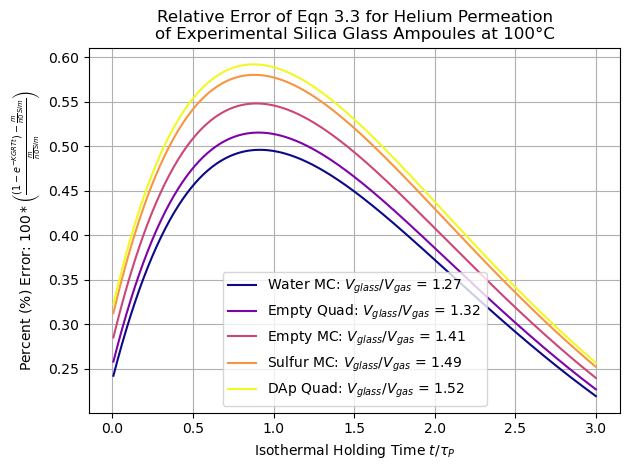

In [218]:
#Ts = np.linspace(24,500,20)+273
Ts = np.array([100])+273
#G = 6000
aa = np.array([0.063,0.0747,0.0529,0.0487,0.085])/2 
#bb = aa*np.exp(2/(G*aa**2))
bb = np.array([0.096,0.1159,0.0835,0.0734,0.135])/2 
names = ['Empty Quad', 'Empty MC', 'Sulfur MC', 'Water MC', 'DAp Quad']
colmap = plt.cm.plasma
for j, i in enumerate([3,0,1,2,4]):
    a = aa[i]
    b = bb[i]
    G = 2/(np.log(b/a)*(a**2))
    print(G)
    Vgas = 1*a**2*np.pi
    Vglass = (1*b**2*np.pi) - Vgas 
    
    m_n0M = []
    m_n0A = []
    simtau = 150
    ntau = 3
    for h, T in enumerate(Ts):
        D = swets('D', T)
        K = swets('K', T)
        #tau = (((b-a)**2)/D)
        tau = 1/(K*G*Ratoms*T)
        dt = tau/simtau
        ts = np.arange(dt,dt*((simtau*ntau))+1,dt)#((b-a)**2)/D 
        m_n0M = []
        m_n0A = []
        workingBlank = permeation_sim(a = a, b = b, n0 = 1, T = T, cooling_func = NovTube_blank_cooling, He = 4)
        workingBlank.stabilize_profile()
        for t in ts:
            workingBlank.hold_T(T,dt)
            m_n0M.append(workingBlank.out/workingBlank.n0)
            #m_n0A.append(T*swets('K',T)*G*Ratoms*t) # Constant Pressure
            m_n0A.append(1-np.exp(-T*swets('K',T)*G*Ratoms*t))
        plt.plot(ts/tau, 100*(np.array(m_n0A)-np.array(m_n0M))/np.array(m_n0M), color = colmap(np.linspace(0, 1, 5)[j]), label = f"{names[i]}:"+r" $V_{glass}/V_{gas}$ = "+f"{round(Vglass/Vgas,2)}")

plt.title('Relative Error of Eqn 3.3 for Helium Permeation\nof Experimental Silica Glass Ampoules at 100°C')
plt.xlabel(r"Isothermal Holding Time $t/\tau_{P}$")
plt.ylabel(r'Percent (%) Error: $100 * \left(\frac{\left(1-e^{-KGRTt}\right)-\frac{m}{n0}_{ Sim}}{\frac{m}{n0}_{ Sim}}\right)$')
#plt.vlines()
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('NumericalEqn3.3ErrWavesSettledProfile.jpg', dpi = 256)

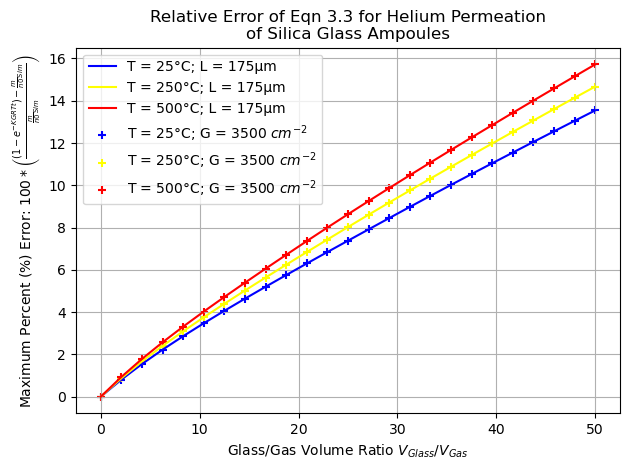

In [262]:
VR = np.array(np.linspace(0.01,50,25))
VP = (VR + 1)**0.5
#G = 3500
L = 0.0175
#labelVR = np.array([0.1,1,5,10])
#labelVP = (labelVR + 1)**0.5
#labela = L/(-1+labelVP)
#labelb = L + labela


#labelb = np.array([600,750,1000,2000])/2E4
#labela = labelb-L
#labelVR = ((labelb**2)-(labela**2))/(labela**2)


aa = L/(-1+VP)
bb = L + aa
G = 2/((aa**2)*np.log(bb/aa))

#aa = (2/(G*np.log(VP)))**0.5
#bb = aa*VP
simtau = 150
ntau = 1
#Ts = np.linspace(24,500,20)+273
Ts = np.array([25,250,500])+273
colmap = plt.cm.inferno

#I = [6,30,32,85,88,92,97,98]#SUS

for h, T in enumerate(Ts):
    D = swets('D', T)
    K = swets('K', T)
    maxerr = []
    #tau = (((b-a)**2)/D)
    for i, V in enumerate(VR):
        #V = VR[i]
        a = aa[i]
        b = bb[i]
        #print(f"V:{V}, a = {a}, b ={b}")
        G = 2/(np.log(b/a)*(a**2))
        tau = 1/(G*K*Ratoms*T)
        #tauD = (((b-a)**2)/D)
        dt = tau/simtau
        ts = np.arange(dt,dt*((simtau*ntau))+1,dt)#((b-a)**2)/D 
        m_n0M = []
        m_n0A = []
        #print(G)
        workingBlank = permeation_sim(a = a, b = b, n0 = 1, T = T, cooling_func = NovTube_blank_cooling, He = 4)
        #print(workingBlank.r)
        #print(workingBlank.r[1:]-workingBlank.r[:-1])
        workingBlank.stabilize_profile()
        for t in ts:
            workingBlank.hold_T(T,dt)
            m_n0M.append(workingBlank.out/workingBlank.n0)
            #m_n0A.append(T*swets('K',T)*G*Ratoms*t) # Constant Pressure
            m_n0A.append(1-np.exp(-T*swets('K',T)*G*Ratoms*t))
        maxerr.append(np.max(np.array(100*(np.array(m_n0A)-np.array(m_n0M))/np.array(m_n0M))))
    plt.plot(VR, maxerr, color = ['Blue', 'Yellow', 'Red'][h], label = f"T = {T-273}°C; L = 175µm")

    
G = 3500

aa = (2/(G*np.log(VP)))**0.5
bb = aa*VP
simtau = 150
ntau = 1
#Ts = np.linspace(24,500,20)+273
Ts = np.array([25,250,500])+273
colmap = plt.cm.inferno

#I = [6,30,32,85,88,92,97,98]#SUS

for h, T in enumerate(Ts):
    D = swets('D', T)
    K = swets('K', T)
    maxerr = []
    #tau = (((b-a)**2)/D)
    for i, V in enumerate(VR):
        #V = VR[i]
        a = aa[i]
        b = bb[i]
        #print(f"V:{V}, a = {a}, b ={b}")
        G = 2/(np.log(b/a)*(a**2))
        tau = 1/(G*K*Ratoms*T)
        #tauD = (((b-a)**2)/D)
        dt = tau/simtau
        ts = np.arange(dt,dt*((simtau*ntau))+1,dt)#((b-a)**2)/D 
        m_n0M = []
        m_n0A = []
        #print(G)
        workingBlank = permeation_sim(a = a, b = b, n0 = 1, T = T, cooling_func = NovTube_blank_cooling, He = 4)
        #print(workingBlank.r)
        #print(workingBlank.r[1:]-workingBlank.r[:-1])
        workingBlank.stabilize_profile()
        for t in ts:
            workingBlank.hold_T(T,dt)
            m_n0M.append(workingBlank.out/workingBlank.n0)
            #m_n0A.append(T*swets('K',T)*G*Ratoms*t) # Constant Pressure
            m_n0A.append(1-np.exp(-T*swets('K',T)*G*Ratoms*t))
        maxerr.append(np.max(np.array(100*(np.array(m_n0A)-np.array(m_n0M))/np.array(m_n0M))))
    plt.scatter(VR, maxerr, marker = '+', color = ['Blue', 'Yellow', 'Red'][h], label = f"T = {T-273}°C;"+r" G = 3500 $cm^{-2}$")
    
    
plt.title('Relative Error of Eqn 3.3 for Helium Permeation\n'+ r'of Silica Glass Ampoules')
plt.xlabel(r"Glass/Gas Volume Ratio $V_{Glass}/V_{Gas}$")
plt.ylabel(r'Maximum Percent (%) Error: $100 * \left(\frac{\left(1-e^{-KGRTt}\right)-\frac{m}{n0}_{ Sim}}{\frac{m}{n0}_{ Sim}}\right)$')
#plt.vlines()
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('NumericalEqn3.3ErrConstLandG.jpg', dpi = 256)

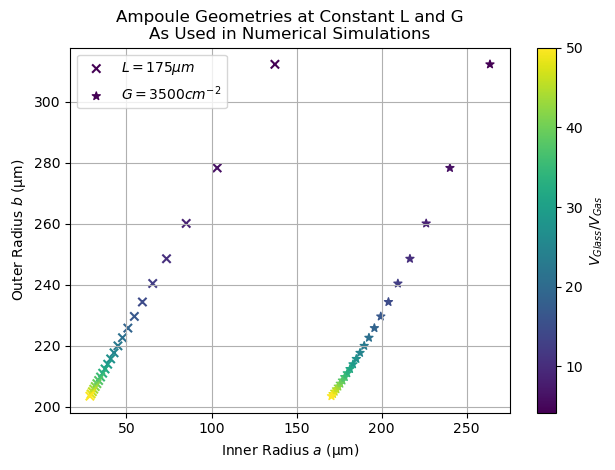

In [266]:
G = 3500
aa1 = (2/(G*np.log(VP)))**0.5
bb1 = aa*VP
L = 0.0175
aa = L/(-1+VP)
bb = L + aa
#plt.ylim([100,500])
#plt.xlim([100,400])
plt.scatter(1E4*aa[2:],1E4*bb[2:], marker = 'x', c = VR[2:], label = r"$L = 175 µm$")
plt.scatter(1E4*aa1[2:],1E4*bb1[2:], marker = '*',c=VR[2:], label = r"$G = 3500 cm^{-2}$" )
cbar = plt.colorbar()
cbar.set_label(r'$V_{Glass}/V_{Gas}$')
plt.grid()
plt.legend()
plt.title('Ampoule Geometries at Constant L and G\nAs Used in Numerical Simulations')
plt.xlabel(r'Inner Radius $a$ (µm)')
plt.ylabel(r'Outer Radius $b$ (µm)')
plt.tight_layout()
plt.savefig('SimulatedTubeGeometries.jpg', dpi = 256)

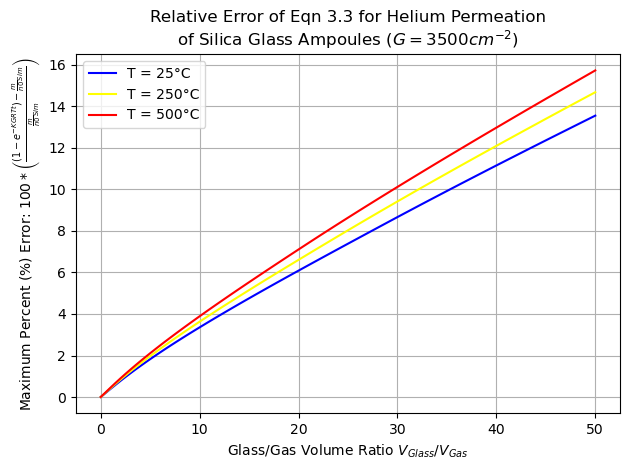

In [240]:
VR = np.array(np.linspace(0.01,50,100))
VP = (VR + 1)**0.5
G = 3500
#labelVR = np.array([0.1,1,5,10])
#labelVP = (labelVR + 1)**0.5
#labela = L/(-1+labelVP)
#labelb = L + labela


#labelb = np.array([600,750,1000,2000])/2E4
#labela = labelb-L
#labelVR = ((labelb**2)-(labela**2))/(labela**2)


#aa = L/(-1+VP)
#bb = L + aa
#G = 2/((a**2)*np.log(b/a))

aa = (2/(G*np.log(VP)))**0.5
bb = aa*VP
simtau = 150
ntau = 1
#Ts = np.linspace(24,500,20)+273
Ts = np.array([25,250,500])+273
colmap = plt.cm.inferno

#I = [6,30,32,85,88,92,97,98]#SUS

for h, T in enumerate(Ts):
    D = swets('D', T)
    K = swets('K', T)
    maxerr = []
    #tau = (((b-a)**2)/D)
    for i, V in enumerate(VR):
        #V = VR[i]
        a = aa[i]
        b = bb[i]
        #print(f"V:{V}, a = {a}, b ={b}")
        G = 2/(np.log(b/a)*(a**2))
        tau = 1/(G*K*Ratoms*T)
        #tauD = (((b-a)**2)/D)
        dt = tau/simtau
        ts = np.arange(dt,dt*((simtau*ntau))+1,dt)#((b-a)**2)/D 
        m_n0M = []
        m_n0A = []
        #print(G)
        workingBlank = permeation_sim(a = a, b = b, n0 = 1, T = T, cooling_func = NovTube_blank_cooling, He = 4)
        #print(workingBlank.r)
        #print(workingBlank.r[1:]-workingBlank.r[:-1])
        workingBlank.stabilize_profile()
        for t in ts:
            workingBlank.hold_T(T,dt)
            m_n0M.append(workingBlank.out/workingBlank.n0)
            #m_n0A.append(T*swets('K',T)*G*Ratoms*t) # Constant Pressure
            m_n0A.append(1-np.exp(-T*swets('K',T)*G*Ratoms*t))
        maxerr.append(np.max(np.array(100*(np.array(m_n0A)-np.array(m_n0M))/np.array(m_n0M))))
    plt.plot(VR, maxerr, color = ['Blue', 'Yellow', 'Red'][h], label = f"T = {T-273}°C")

plt.title('Relative Error of Eqn 3.3 for Helium Permeation\n'+ r'of Silica Glass Ampoules $\left(G = 3500 cm^{-2}\right)$')
plt.xlabel(r"Glass/Gas Volume Ratio $V_{Glass}/V_{Gas}$")
plt.ylabel(r'Maximum Percent (%) Error: $100 * \left(\frac{\left(1-e^{-KGRTt}\right)-\frac{m}{n0}_{ Sim}}{\frac{m}{n0}_{ Sim}}\right)$')
#plt.vlines()
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('NumericalEqn3.3ErrMain.jpg', dpi = 256)

In [241]:
for i, V in enumerate(VR): 
    print(f"i={i}: {round(V,2)}:{round(maxerr[i],2)}")

i=0: 0.01:0.0
i=1: 0.51:0.23
i=2: 1.02:0.47
i=3: 1.52:0.69
i=4: 2.03:0.91
i=5: 2.53:1.13
i=6: 3.04:1.34
i=7: 3.54:1.54
i=8: 4.05:1.74
i=9: 4.55:1.94
i=10: 5.06:2.13
i=11: 5.56:2.32
i=12: 6.07:2.51
i=13: 6.57:2.69
i=14: 7.08:2.87
i=15: 7.58:3.05
i=16: 8.09:3.23
i=17: 8.59:3.41
i=18: 9.1:3.58
i=19: 9.6:3.75
i=20: 10.11:3.92
i=21: 10.61:4.09
i=22: 11.12:4.26
i=23: 11.62:4.43
i=24: 12.13:4.6
i=25: 12.63:4.76
i=26: 13.14:4.93
i=27: 13.64:5.09
i=28: 14.15:5.25
i=29: 14.65:5.42
i=30: 15.16:5.58
i=31: 15.66:5.74
i=32: 16.17:5.9
i=33: 16.67:6.06
i=34: 17.18:6.22
i=35: 17.68:6.38
i=36: 18.19:6.54
i=37: 18.69:6.69
i=38: 19.2:6.85
i=39: 19.7:7.01
i=40: 20.21:7.17
i=41: 20.71:7.32
i=42: 21.22:7.48
i=43: 21.72:7.64
i=44: 22.23:7.79
i=45: 22.73:7.95
i=46: 23.24:8.1
i=47: 23.74:8.25
i=48: 24.25:8.41
i=49: 24.75:8.56
i=50: 25.26:8.71
i=51: 25.76:8.86
i=52: 26.27:9.01
i=53: 26.77:9.16
i=54: 27.28:9.31
i=55: 27.78:9.46
i=56: 28.29:9.61
i=57: 28.79:9.76
i=58: 29.3:9.91
i=59: 29.8:10.06
i=60: 30.31:10.2
i=

In [ ]:
VR = np.array(np.linspace(0.01,50,100))
VP = (VR + 1)**0.5
G = 3500
#labelVR = np.array([0.1,1,5,10])
#labelVP = (labelVR + 1)**0.5
#labela = L/(-1+labelVP)
#labelb = L + labela


#labelb = np.array([600,750,1000,2000])/2E4
#labela = labelb-L
#labelVR = ((labelb**2)-(labela**2))/(labela**2)


#aa = L/(-1+VP)
#bb = L + aa
#G = 2/((a**2)*np.log(b/a))

aa = (2/(G*np.log(VP)))**0.5
bb = aa*VP
simtau = 150
ntau = 1
#Ts = np.linspace(24,500,20)+273
Ts = np.array([24,100,300])+273
colmap = plt.cm.inferno
for h, T in enumerate(Ts):
    D = swets('D', T)
    K = swets('K', T)
    maxerr = []
    #tau = (((b-a)**2)/D)
    for i, V in enumerate(VR):
        a = aa[i]
        b = bb[i]
        G = 2/(np.log(b/a)*(a**2))
        tau = 1/(G*K*Ratoms*T)
        #tauD = (((b-a)**2)/D)
        dt = tau/simtau
        ts = np.arange(dt,dt*((simtau*ntau))+1,dt)#((b-a)**2)/D 
        m_n0M = []
        m_n0A = []
        print(G)
        workingBlank = permeation_sim(a = a, b = b, n0 = 1, T = T, cooling_func = NovTube_blank_cooling, He = 4)
        workingBlank.stabilize_profile()
        for t in ts:
            workingBlank.hold_T(T,dt)
            m_n0M.append(workingBlank.out/workingBlank.n0)
            #m_n0A.append(T*swets('K',T)*G*Ratoms*t) # Constant Pressure
            m_n0A.append(1-np.exp(-T*swets('K',T)*G*Ratoms*t))
        maxerr.append(np.max(np.array(100*(np.array(m_n0A)-np.array(m_n0M))/np.array(m_n0M))))
    plt.plot(VR, maxerr, color = colmap(np.linspace(0, 1, 3)[h]), label = f"T = {T-273}°C")

plt.title('Relative Error of Eqn 3.3 for Helium Permeation\n'+ r'of Silica Glass Ampoules (L = 175)')
plt.xlabel(r"Glass/Gas Volume Ratio $V_{Glass}/V_{Gas}$")
plt.ylabel(r'Maximum Percent (%) Error: $100 * \left(\frac{\left(1-e^{-KGRTt}\right)-\frac{m}{n0}_{ Sim}}{\frac{m}{n0}_{ Sim}}\right)$')
#plt.vlines()
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('NumericalEqn3.3ErrMain.jpg', dpi = 256)

3500.0000000000005
3499.999999999999
3500.0000000000005
3500.0000000000005
3500.0000000000005
3499.9999999999995


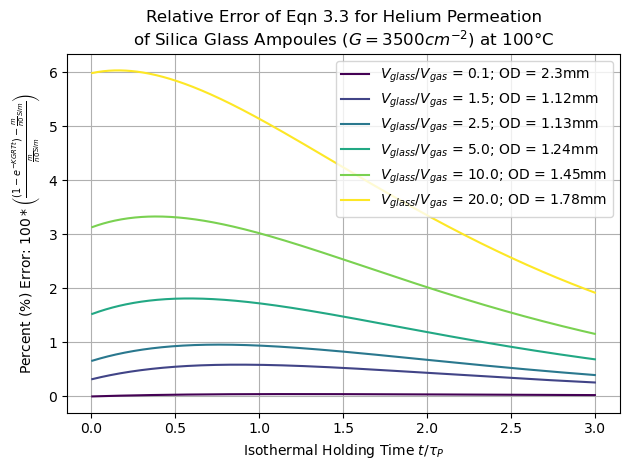

In [223]:
VR = np.array([0.1,1.5,2.5,5,10,20])
VP = (VR + 1)**0.5
G = 3500
#labelVR = np.array([0.1,1,5,10])
#labelVP = (labelVR + 1)**0.5
#labela = L/(-1+labelVP)
#labelb = L + labela


#labelb = np.array([600,750,1000,2000])/2E4
#labela = labelb-L
#labelVR = ((labelb**2)-(labela**2))/(labela**2)


#aa = L/(-1+VP)
#bb = L + aa
#G = 2/((a**2)*np.log(b/a))

aa = (2/(G*np.log(VP)))**0.5
bb = aa*VP

#Ts = np.linspace(24,500,20)+273
Ts = np.array([100])+273
colmap = plt.cm.viridis
for i, V in enumerate(VR):
    a = aa[i]
    b = bb[i]
    G = 2/(np.log(b/a)*(a**2))
    print(G)
    m_n0M = []
    m_n0A = []
    simtau = 150
    ntau = 3
    for h, T in enumerate(Ts):
        D = swets('D', T)
        K = swets('K', T)
        #tau = (((b-a)**2)/D)
        tau = 1/(G*K*Ratoms*T)
        tauD = (((b-a)**2)/D)
        dt = tau/simtau
        ts = np.arange(dt,dt*((simtau*ntau))+1,dt)#((b-a)**2)/D 
        m_n0M = []
        m_n0A = []
        workingBlank = permeation_sim(a = a, b = b, n0 = 1, T = T, cooling_func = NovTube_blank_cooling, He = 4)
        workingBlank.stabilize_profile()
        for t in ts:
            workingBlank.hold_T(T,dt)
            m_n0M.append(workingBlank.out/workingBlank.n0)
            #m_n0A.append(T*swets('K',T)*G*Ratoms*t) # Constant Pressure
            m_n0A.append(1-np.exp(-T*swets('K',T)*G*Ratoms*t))
        plt.plot(ts/tau, 100*(np.array(m_n0A)-np.array(m_n0M))/np.array(m_n0M), color = colmap(np.linspace(0, 1, 6)[i]), label = r"$V_{glass}/V_{gas}$ = "+f"{V}; OD = {round(b*2E1, 2)}mm")

plt.title('Relative Error of Eqn 3.3 for Helium Permeation\n'+ r'of Silica Glass Ampoules $\left(G = 3500 cm^{-2}\right)$ at 100°C')
plt.xlabel(r"Isothermal Holding Time $t/\tau_{P}$")
plt.ylabel(r'Percent (%) Error: $100 * \left(\frac{\left(1-e^{-KGRTt}\right)-\frac{m}{n0}_{ Sim}}{\frac{m}{n0}_{ Sim}}\right)$')
#plt.vlines()
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('NumericalEqn3.3ErrVrVarySettledProfilet10.jpg', dpi = 256)

In [ ]:
VR = np.array([0.1,5,10,20,50])
VP = (VR + 1)**0.5
L = 0.0175
#labelVR = np.array([0.1,1,5,10])
#labelVP = (labelVR + 1)**0.5
#labela = L/(-1+labelVP)
#labelb = L + labela


labelb = np.array([600,750,1000,2000])/2E4
labela = labelb-L
labelVR = ((labelb**2)-(labela**2))/(labela**2)


a = L/(-1+VP)
b = L + a
G = 2/((a**2)*np.log(b/a))

fig = plt.figure()
ax1 = fig.add_subplot(111)
ax2 = ax1.twinx()

ax1.plot(VR, G)

ax2.set_xticks(labelVR)
ax2.set_xlim(ax1.get_xlim())
ax2.set_xticklabels(np.round(labelb*2E4).astype(int))
ax2.set_xlabel('Outer Diameter (µm)')
#ax1.set_xlabel(r'$\frac{glass}{gas}$ Volume Ratio: $V_{glass/gas}$')
#ax1.set_ylabel(r'Apparent Diffusivity $\left(\frac{D}{a^2}\right)$')

#Ts = np.linspace(24,500,20)+273
Ts = np.array([24,100,300])+273
#G = 6000
aa = np.array([0.063,0.0747,0.0529,0.0487,0.085])/2 
#bb = aa*np.exp(2/(G*aa**2))
bb = np.array([0.096,0.1159,0.0835,0.0734,0.135])/2 
names = ['Empty Quad', 'Empty MC', 'Sulfur MC', 'Water MC', 'DAp Quad']
colmap = plt.cm.plasma
for j, i in enumerate([3,0,1,2,4]):
    a = aa[i]
    b = bb[i]
    G = 2/(np.log(b/a)*(a**2))
    print(G)
    Vgas = 1*a**2*np.pi
    Vglass = (1*b**2*np.pi) - Vgas 
    
    m_n0M = []
    m_n0A = []
    simtau = 50
    ntau = 200
    for h, T in enumerate(Ts):
        D = swets('D', T)
        tau = (((b-a)**2)/D)
        dt = tau/50
        ts = np.arange(dt,dt*((simtau*ntau))+1,dt)#((b-a)**2)/D 
        m_n0M = []
        m_n0A = []
        workingBlank = permeation_sim(a = a, b = b, n0 = 1, T = T, cooling_func = NovTube_blank_cooling, He = 4)
        for t in ts:
            workingBlank.hold_T(T,dt)
            m_n0M.append(workingBlank.out/workingBlank.n0)
            #m_n0A.append(T*swets('K',T)*G*Ratoms*t) # Constant Pressure
            m_n0A.append(1-np.exp(-T*swets('K',T)*G*Ratoms*t))
        plt.plot(ts/tau, 100*(np.array(m_n0A)-np.array(m_n0M))/np.array(m_n0M), color = colmap(np.linspace(0, 1, 5)[j]), label = f"{names[i]}: T = {T-273}°C: Vglass/gas = {round(Vglass/Vgas,2)}")

plt.title('Relative Error of Eqn 3.3 for Helium Permeation\nof Experimental Silica Glass Ampoules')
plt.xlabel(r"Isothermal Holding Time $\frac{t}{\tau_{D}^{}}$")
plt.ylabel(r'Percent (%) Error: $100 * \left(\frac{\left(1-e^{-KGRTt}\right)-\frac{m}{n0}_{ Sim}}{\frac{m}{n0}_{ Sim}}\right)$')
#plt.vlines()
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('NumericalEqn3.3ErrVrVary.jpg', dpi = 256)

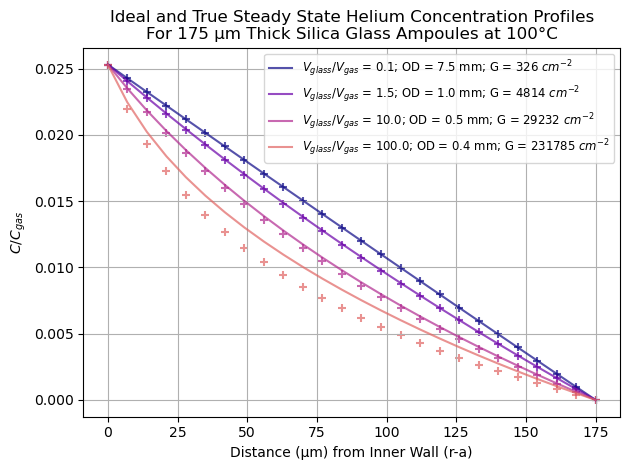

In [212]:

def ideal_c(self):
    return (self.S*self.ngas*Ratoms*self.T/(np.pi*(self.a**2)*self.h))*(np.log(self.r/self.b)/np.log(self.a/self.b))

VR = np.array([0.1,1.5,10,100])
VP = (VR + 1)**0.5
L = 0.0175
T = 273+100

aa = L/(-1+VP)
bb = L + aa

colmap = plt.cm.plasma

for i, V in enumerate(VR):
    a = aa[i]
    b = bb[i]
    G = 2/((a**2)*np.log(b/a))
    workingBlank = permeation_sim(a = a, b = b, n0 = 1, T = T, cooling_func = NovTube_blank_cooling, He = 4)
    plt.scatter(1E4*(workingBlank.r-workingBlank.a), workingBlank.c/(workingBlank.ngas/(workingBlank.h*np.pi*workingBlank.a**2)), color = colmap(np.linspace(0,1,6)[i]), alpha = 0.7, marker = '+')
    workingBlank.stabilize_profile()
    plt.plot(1E4*(workingBlank.r-workingBlank.a), workingBlank.c/(workingBlank.ngas/(workingBlank.h*np.pi*workingBlank.a**2)), color = colmap(np.linspace(0,1,6)[i]), alpha = 0.7, label = r"$V_{glass}/V_{gas}$"+f" = {V}; OD = {round(20*b,1)} mm; G = {round(G)}"+r" $cm^{-2}$")

workingBlank = permeation_sim(a = a, b = b, n0 = 1, T = T, cooling_func = NovTube_blank_cooling, He = 4)
#labelVR = np.array([0.1,1,5,10])
#labelVP = (labelVR + 1)**0.5
#labela = L/(-1+labelVP)
#labelb = L + labela


labelb = np.array([600,750,1000,2000])/2E4
labela = labelb-L
labelVR = ((labelb**2)-(labela**2))/(labela**2)


plt.legend(fontsize = 8.4)
plt.title('Ideal and True Steady State Helium Concentration Profiles\nFor 175 µm Thick Silica Glass Ampoules at 100°C')
plt.ylabel(r'$C/C_{gas}$')
plt.xlabel('Distance (µm) from Inner Wall (r-a)')
plt.tight_layout()
plt.grid()
plt.savefig('SteadyStateProfileDeviation.jpg', dpi = 256)

In [8]:
G = 6000
aa = np.array([0.03,0.04,0.05,0.06])/2 
bb = aa*np.exp(2/(G*aa**2))
Ts = np.linspace(24,500,5)+273
for i, a in enumerate(aa):
    b = bb[i]
    for T in Ts:
        D = swets('D', T)
        S = swets('S', T)
        K = swets('K', T)
        VR = ((b**2)-(a**2))/a**2
        VP = (VR + 1)**0.5
        tauP = 1/(G*Ratoms*K*T)
        tauD = ((b-a)**2)/D
        print(f"VR = {VR}; T = {T-273}C")
        print(tauD/tauP)
        print(S*Ratoms*T*VR*((-1+VP)/(1+VP))*(2/np.log(VP)))

VR = 18.35523572469046; T = 24.0C
0.3975545139991066
0.3975545139991066
VR = 18.35523572469046; T = 143.0C
0.40048216436548767
0.4004821643654876
VR = 18.35523572469046; T = 262.0C
0.42891881354502104
0.4289188135450211
VR = 18.35523572469046; T = 381.0C
0.4390387146375757
0.43903871463757566
VR = 18.35523572469046; T = 500.0C
0.4515476075066699
0.4515476075066699
VR = 4.29449005047003; T = 24.0C
0.10351258477439192
0.10351258477439193
VR = 4.29449005047003; T = 143.0C
0.10427486679124379
0.10427486679124377
VR = 4.29449005047003; T = 262.0C
0.11167901126764812
0.1116790112676481
VR = 4.29449005047003; T = 381.0C
0.11431396341349112
0.11431396341349115
VR = 4.29449005047003; T = 500.0C
0.1175709452561091
0.11757094525610909
VR = 1.9056777468820003; T = 24.0C
0.04744232428271831
0.047442324282718294
VR = 1.9056777468820003; T = 143.0C
0.04779169659060909
0.047791696590609084
VR = 1.9056777468820003; T = 262.0C
0.05118519530432852
0.05118519530432851
VR = 1.9056777468820003; T = 381.0C
0

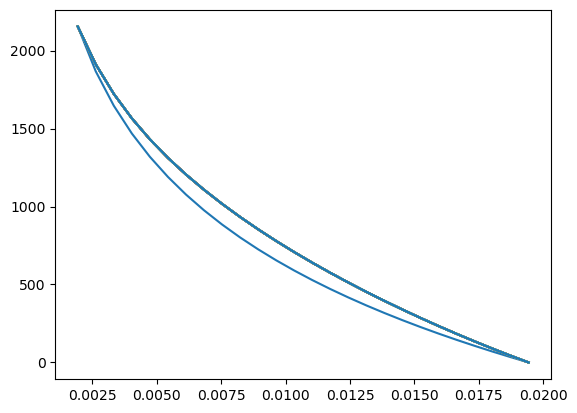

In [278]:
VR = 100
VP = (VR + 1)**0.5
L = 0.0175
T = 273+100

a = L/(-1+VP)
b = L + a
workingBlank = permeation_sim(a = a, b = b, n0 = 1, T = T, cooling_func = NovTube_blank_cooling, He = 4)
D = swets('D', T)
K = swets('K', T)
G = 2/(np.log(b/a)*(a**2))
tauD = (((b-a)**2)/D)
simtau = 
ntau = 10
dt = tauD/simtau
ts = np.arange(dt,dt*((simtau*ntau))+1,dt)#((b-a)**2)/D 
plt.plot(workingBlank.r,workingBlank.c/workingBlank.ngas)
for t in ts:
    workingBlank.hold_T(T,dt)
    plt.plot(workingBlank.r,workingBlank.c/workingBlank.ngas)

In [281]:
(500**2-300**2)/300**2

1.7777777777777777

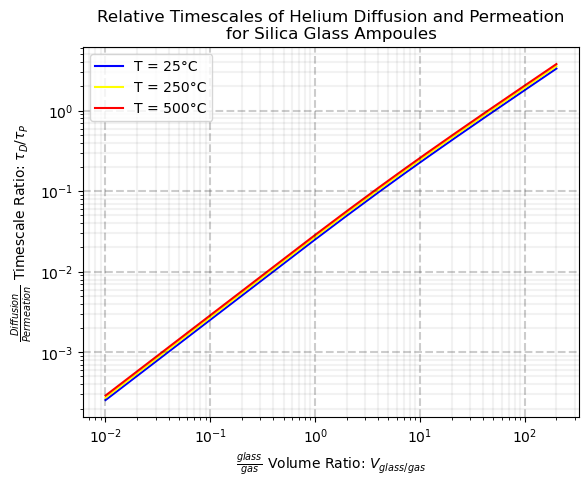

In [280]:
Ts = np.array([25,250,500])+273
colors = ['blue', 'yellow', 'red']
VR = np.linspace(0.01,200,200)
VP = (VR + 1)**0.5
fig, ax = plt.subplots()
for i, T in enumerate(Ts):
    #D = swets('D', T)
    S = swets('S', T)
    #K = swets('K', T)
    #tauP = 1/(G*Ratoms*K*T)
    #tauD = ((b-a)**2)/D
    tauR = S*Ratoms*T*VR*((-1+VP)/(1+VP))*(2/np.log(VP))
    plt.loglog(VR, tauR, label = f'T = {T-273}°C', color = colors[i])
plt.legend()
make_grid()
plt.xlabel(r'$\frac{glass}{gas}$ Volume Ratio: $V_{glass/gas}$')
plt.ylabel(r'$\frac{Diffusion}{Permeation}$ Timescale Ratio: $\tau_D/\tau_P$')
plt.title('Relative Timescales of Helium Diffusion and Permeation\nfor Silica Glass Ampoules')
plt.savefig('VRvsRtau.jpg', dpi = 256)

In [ ]:
#b=a(e^(2/(Ga^2) )

m_n0A1 = []
m_n0M1c = []
Ts = np.linspace(24,500,50)+273
ts1 = []
a = (0.0747)/2 
b = (0.1159)/2
for T in Ts:
    D = swets('D', T)
    t = ((b-a)**2)/D 
    ts1.append(t)
    G = 2/(np.log(b/a)*(a**2))
    workingBlank = permeation_sim(a = a, b = b, n0 = 1, T = T, cooling_func = NovTube_blank_cooling, He = 4)
    workingBlank.hold_T(T,t)
    m_n0M1c.append(workingBlank.out/workingBlank.n0)
    m_n0A1.append(1-np.exp(-T*swets('K',T)*G*Ratoms*t))
#workingBlank.generate_report(diffname+str(He)+'HeSim')

plt.plot(Ts-273, 100*(np.array(m_n0M)-np.array(m_n0A))/np.array(m_n0A))

In [68]:
print(workingBlank.K)
print(swets('K',workingBlank.T))
print(workingBlank.S*workingBlank.D)
workingBlank.b-workingBlank.a
print(len(ts1))
print(len(ts0))

2745042562882.137
2745042562882.137
2745042562882.137


NameError: name 'ts1' is not defined

C:\Users\dashf\AppData\Local\Temp\ipykernel_22312\1781954623.py:1: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = mpl.cm.get_cmap('viridis')


ValueError: x and y must be the same size

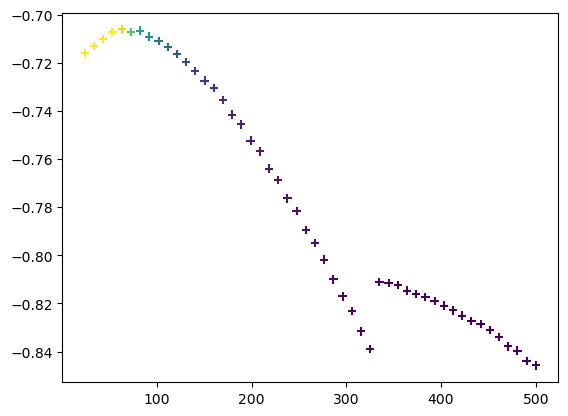

In [85]:
cmap = mpl.cm.get_cmap('viridis')
norm = mpl.colors.Normalize(vmin=np.min(ts+ts0)/60, vmax=np.max(ts+ts0)/60)
plt.scatter(Ts-273, 100*(np.array(m_n0M1c)-np.array(m_n0A1))/np.array(m_n0A1), color = cmap(norm(np.array(ts1)/60)), marker = '+', label = 'Large c')
plt.scatter(Ts-273, 100*(np.array(m_n0M0b)-np.array(m_n0A0))/np.array(m_n0A0), color = cmap(norm(np.array(ts0)/60)), marker = 'x', label = 'Small b')
#plt.scatter(Ts-273, 100*(np.array(m_n0M1)-np.array(m_n0A1))/np.array(m_n0A1), color = cmap(norm(np.array(ts1)/60)), label = 'Large')
plt.scatter(Ts-273, 100*(np.array(m_n0M0)-np.array(m_n0A0))/np.array(m_n0A0), color = cmap(norm(np.array(ts0)/60)), marker = 's', label = 'Small')
plt.title('Relative Error of Numerical Permeation Model\nof Silica Glass Ampoule for Fo# = 1')
plt.xlabel('Isothermal Holding Temperature (°C)')
plt.ylabel(r' Percent (%) Error: $100 * \left(\frac{\frac{m}{n0}_{model}-\left(1-e^{-KGRTt}\right)}{\left(1-e^{-KGRTt}\right)}\right)$')
cbar = plt.colorbar()
cbar.set_label('time (min)')
plt.legend()
#plt.savefig('Model_Error.jpg', dpi = 256)

Assuming all standards analyzed had 157.5 nCCSTP 4He and 3.57 pCCSTP 3He


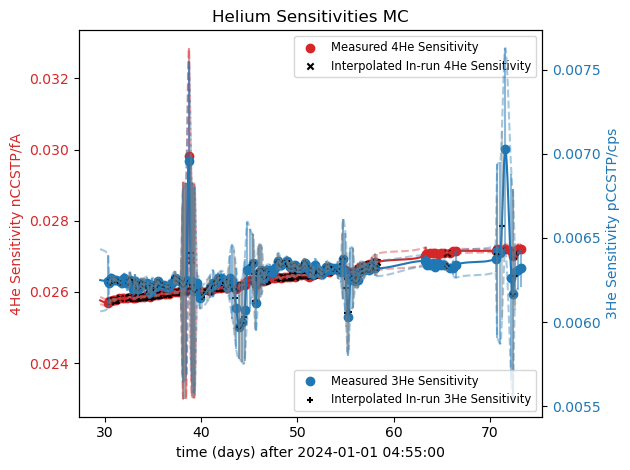

In [329]:
diffname = "IrrWin0601bTube012624TC"
NovReducer = MCHeReducer('2024STDsMC.csv')

DIFFCELL = pd.read_csv(diffname+'.csv', header=None).to_numpy()
He3, He4, He3sig, He4sig, sens3, sens4 = NovReducer.reduce(DIFFCELL, plot = True, sens_out= True, uncertainties=True) 
plt.savefig(diffname+'_Standardization.jpg', dpi = 254)
plt.show()
columns = ['3He (pcccSTP)', '3He 2sigma (pccSTP)', '4He (nccSTP)', '4He 2sigma (nccSTP)']
reportDF = pd.DataFrame()
reportDF['Sens3 (pccSTP/cps)'] = sens3
reportDF['Sens4 (nccSTP/fA)'] = sens4
reportDF['3He (pcccSTP)'] = He3
reportDF['3He 2sigma (pccSTP)'] = He3sig*2
reportDF['4He (nccSTP)'] = He4
reportDF['4He 2sigma (nccSTP)'] = He4sig*2
reportDF.to_csv(diffname+'_reducedMC.csv')

ngas = 98.64118276585661
For Diffusivity of 5.093239872375834e-08 cm^2/s and dx = 1.23, dt is set at 0.1485203954564858 seconds
outflux = -0.00015486274081111733, influx = -0.0001548571896877436
[-0.00015487 -0.00015487 -0.00015487 -0.00015487 -0.00015487 -0.00015487
 -0.00015487 -0.00015487 -0.00015487 -0.00015487 -0.00015487 -0.00015487
 -0.00015487 -0.00015487 -0.00015487 -0.00015487 -0.00015487 -0.00015487
 -0.00015487 -0.00015487 -0.00015487 -0.00015487 -0.00015487 -0.00015487
 -0.00015487 -0.00015487 -0.00015487 -0.00015487 -0.00015487 -0.00015487
 -0.00015487 -0.00015487 -0.00015487 -0.00015487 -0.00015487 -0.00015487
 -0.00015487 -0.00015487 -0.00015487 -0.00015487 -0.00015487 -0.00015487
 -0.00015487 -0.00015487 -0.00015487 -0.00015487 -0.00015487 -0.00015487
 -0.00015487 -0.00015487 -0.00015487 -0.00015487 -0.00015487 -0.00015487
 -0.00015487 -0.00015487 -0.00015487 -0.00015487 -0.00015487 -0.00015487
 -0.00015487 -0.00015487 -0.00015487 -0.00015487 -0.00015487 -0.00015487
 -

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


Simulation finished after 72718 steps
Sim out: 10.70135790645491 Calc_out: 10.78907918442632
In Glass: 1.227849498862334, in gas: 88.08463574527171
100.01384315058897


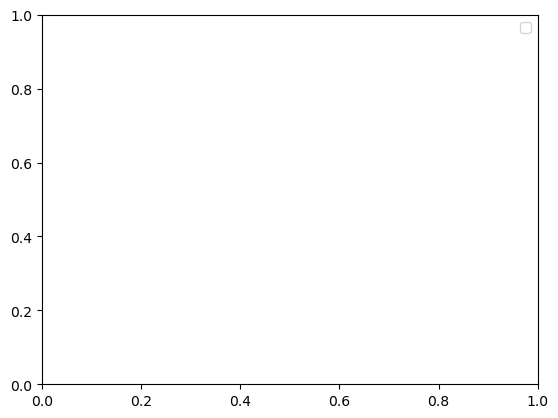

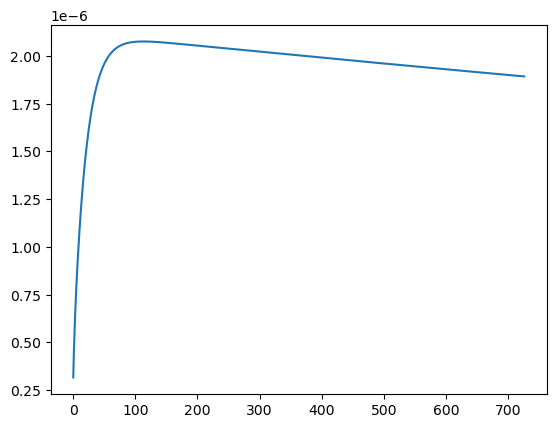

In [73]:

n0 = 100 
t_remain = 180 * 60 # Seconds
T = 50 + 273 # Kelvin
b = 0.0734/2
a = 0.0488/2

t_full = t_remain
G = 2/(np.log(b/a)*(a**2))
D = swets('D',T) 
S = swets('S',T)
K = swets('K', T)
dr = (b-a)/100
dt = 0.5*(dr**2)/D #0.5 is upper bound for stability
r = np.arange(b,a,-dr)
#r = np.arange(b+dr,a,-dr)
#b +=dr
#a -= dr
nglass = n0/(1+(((S*2*Ratoms*T/((a**2)*np.log(a/b))) *((0.5*a**2*(np.log(b/a)+0.5))-((b**2)/4)))**-1)) #eqn 2.46
ngas = n0-nglass
h = 3 # arbitrary, cancels
c = (S*ngas*Ratoms*T/(np.pi*(a**2)*h))*(np.log(r/b)/np.log(a/b)) # eqn 2.42
#c[0]=0
out = 0
predicted_out = n0*(1-np.exp(-Ratoms*T*G*K*t_remain))
#plt.plot(r, c, label = "Initial")
print(f"ngas = {ngas}")
print(f"For Diffusivity of {D} cm^2/s and dx = {round(dr*1E4,2)}, dt is set at {dt} seconds")

current_t = 0
steps = 0
firstderiv = -(c[2:]-c[:-2])/(2*dr)
secondderiv = -(firstderiv[2:]-firstderiv[:-2])/(2*dr)
thirdderiv = -(secondderiv[2:]-secondderiv[:-2])/(2*dr)
delta_c = ((D*dt)) * (((c[:-2]-(2*c[1:-1])+c[2:])/(dr**2))+((1/r[1:-1])*(firstderiv)))
J = D*firstderiv*dt*np.pi*r[1:-1]*2*h
print(f"outflux = {D*(firstderiv[0]+(secondderiv[0]*dr))*dt*np.pi*r[0]*2*h}, influx = {D*(firstderiv[-1]-(secondderiv[-1]*dr))*dt*np.pi*r[-1]*2*h}")
print(J)
print(delta_c)
flux_difference = []
c_inner = S*ngas*Ratoms*T/(np.pi*(a**2)*h)
print(c)
print(c_inner)
print(np.sum([np.sum(r*2*dr*h*np.pi*c),ngas,out]))
flux_difference = []
while t_remain > 0:
    steps += 1
    t_remain -= dt
    current_t += dt
    c[1:-1] += delta_c # update concentrations
    #nglass = n0/(1+(((S*2*Ratoms*T/((a**2)*np.log(a/b))) *((0.5*a**2*(np.log(b/a)+0.5))-((b**2)/4)))**-1)) #eqn 2.46
    #ngas = n0-nglass
    #c = (S*ngas*Ratoms*T/(np.pi*(a**2)*h))*(np.log(r/b)/np.log(a/b)) # eqn 2.42

    #out -= D*((c[0]-c[1])/dr)*dt*np.pi*r[0]*2*h
    #ngas += D*((c[-2]-c[-1])/dr)*dt*np.pi*r[-1]*2*h
    #ngas += D*((firstderiv[-1]+(-secondderiv[-1]*dr)))*dt*np.pi*r[-1]*2*h
    #out -= D*(firstderiv[0]+((secondderiv[0]*dr)))*dt*np.pi*r[0]*2*h
    #ngas += D*(firstderiv[-1]-((secondderiv[-1]-thirdderiv[-1]*dr)*dr))*dt*np.pi*r[-1]*2*h
    #out -= D*(firstderiv[0]+((secondderiv[0]+thirdderiv[0]*dr)*dr))*dt*np.pi*r[0]*2*h
    #ngas += J[-1]-((J[-2]-J[-1])-((2*J[-2])-(J[-1]+J[-3]))/2)#J[-1]-((J[-1]-J[-2]))
    #out -= J[0]+((J[0]-J[1])-((2*J[1])-(J[0]+J[2]))/2)#J[0]+((J[0]-J[1]))#+((J[0]-J[1])-(J[1]-J[2])))#((2*J[1])-(J[0]+J[2])))
    
    #ngas += J[-1]-(J[-2]-J[-1])#-((J[-3]-J[-2])-(J[-2]-J[-1])))
    #out -= J[0]+(J[0]-J[1])
    out -= J[0]+((J[0]-J[1])-((2*J[1])-(J[0]+J[2]))/2)
    ngas += J[-1]+((J[-1]-J[-2])-((2*J[-2])-(J[-1]+J[-3]))/2)
    #n0 = 100-out
    #nglass = n0/(1+(((S*2*Ratoms*T/((a**2)*np.log(a/b))) *((0.5*a**2*(np.log(b/a)+0.5))-((b**2)/4)))**-1)) #eqn 2.46
    #ngas = n0-nglass
    #c = (S*ngas*Ratoms*T/(np.pi*(a**2)*h))*(np.log(r/b)/np.log(a/b)) # eqn 2.42
    if (steps%100 == 0):# or (steps <= 10):
        #flux_difference.append(((D*(firstderiv[-1]-(secondderiv[-1]*dr))*dt*np.pi*r[-1]*2*h)-(D*(firstderiv[0]+(secondderiv[0]*dr))*dt*np.pi*r[0]*2*h))*(t_full/dt))
        flux_difference.append((J[-1]+((J[-1]-J[-2])-((2*J[-2])-(J[-1]+J[-3]))/2))-(J[0]+((J[0]-J[1])-((2*J[1])-(J[0]+J[2]))/2)))
    #ngas += D*firstderiv[-1]*dt*np.pi*r[-1]*2*h
    c_inner = S*ngas*Ratoms*T/(np.pi*(a**2)*h)
    inxs = c[-1]-c_inner # Enforce inner boundry conditions
    c[-1] = c_inner
    ngas += inxs*2*np.pi*r[-1]*dr*h
    firstderiv = -(c[2:]-c[:-2])/(dr*2)
    secondderiv = -(firstderiv[2:]-firstderiv[:-2])/(2*dr)
    thirdderiv = -(secondderiv[2:]-secondderiv[:-2])/(2*dr)
    delta_c = ((D*dt)) * (((c[:-2]-(2*c[1:-1])+c[2:])/(dr**2))+((1/r[1:-1])*(firstderiv)))
    J = D*firstderiv*dt*np.pi*r[1:-1]*2*h
    
    """
    if (steps%10000 == 0) or (steps <= 10):
        Flux_Difference.append((D*((c[-2]-c[-1])/dr)*dt*np.pi*r[-1]*2*h)-(D*((c[0]-c[1])/dr)*dt*np.pi*r[0]*2*h))
        print(f"Step {steps}")
        print(f"outflux = {J[0]}, influx = {J[-1]}")
        print(f"Excess from Boundary Condition:{inxs*2*np.pi*r[-1]*dr*h}")
        predicted_out = n0*(1-np.exp(-Ratoms*T*G*K*current_t))
        print(f"Sim out: {out} Calc_out: {predicted_out}")
        print(f"In Glass: {np.sum(r*2*dr*h*np.pi*c)}, in gas: {np.sum(ngas)}")
        print(delta_c)
        #print(delta_c)
    """
    if (steps <= 10): #steps%25000 == 0:
        c_ideal = (S*ngas*Ratoms*T/(np.pi*(a**2)*h))*(np.log(r/b)/np.log(a/b)) # eqn 2.42
        #plt.plot(r, (c-c_ideal)/c_ideal, label = f"t = {np.round(current_t/60)} minutes")
        #plt.plot(r,c,label = f"t = {np.round(current_t/60)} minutes")
print(f"Simulation finished after {steps} steps")
#plt.plot(r, c, label = 'Final')
plt.legend()
print(f"Sim out: {out} Calc_out: {predicted_out}")
print(f"In Glass: {np.sum(r*2*dr*h*np.pi*c)}, in gas: {np.sum(ngas)}")
print(np.sum([np.sum(r*2*dr*h*np.pi*c),ngas,out]))
plt.show()
plt.plot(flux_difference)

In [6]:

n0 = 100 
t_remain = 180 * 60 # Seconds
T = 50 + 273 # Kelvin
b = 0.0734/2
a = 0.0488/2

t_full = t_remain
G = 2/(np.log(b/a)*(a**2))
D = swets('D',T) 
S = swets('S',T)
K = swets('K', T)
dr = (b-a)/100
dt = 0.5*(dr**2)/D #0.5 is upper bound for stability
r = np.arange(b,a,-dr)
print(r)

[0.0367   0.036577 0.036454 0.036331 0.036208 0.036085 0.035962 0.035839
 0.035716 0.035593 0.03547  0.035347 0.035224 0.035101 0.034978 0.034855
 0.034732 0.034609 0.034486 0.034363 0.03424  0.034117 0.033994 0.033871
 0.033748 0.033625 0.033502 0.033379 0.033256 0.033133 0.03301  0.032887
 0.032764 0.032641 0.032518 0.032395 0.032272 0.032149 0.032026 0.031903
 0.03178  0.031657 0.031534 0.031411 0.031288 0.031165 0.031042 0.030919
 0.030796 0.030673 0.03055  0.030427 0.030304 0.030181 0.030058 0.029935
 0.029812 0.029689 0.029566 0.029443 0.02932  0.029197 0.029074 0.028951
 0.028828 0.028705 0.028582 0.028459 0.028336 0.028213 0.02809  0.027967
 0.027844 0.027721 0.027598 0.027475 0.027352 0.027229 0.027106 0.026983
 0.02686  0.026737 0.026614 0.026491 0.026368 0.026245 0.026122 0.025999
 0.025876 0.025753 0.02563  0.025507 0.025384 0.025261 0.025138 0.025015
 0.024892 0.024769 0.024646 0.024523 0.0244  ]


In [345]:
print(f"Sim out: {out} Calc_out: {predicted_out}")
#print(r)
print(f"In Glass: {np.sum(r*2*dr*h*np.pi*c)}, in gas: {ngas} ")
print(np.sum([np.sum(r*2*dr*h*np.pi*c),ngas,out]))
print(f"Simulation n0: {np.sum([np.sum(r*2*dr*h*np.pi*c),ngas])}, Model: = {100*np.exp(-Ratoms*T*G*K*current_t)}")


Sim out: 10.701104163362366 Calc_out: 10.78907918442632
In Glass: 1.2277817628918988, in gas: 88.07965910532525 
100.0085450315795
Simulation n0: 89.30744086821714, Model: = 89.21082074239774


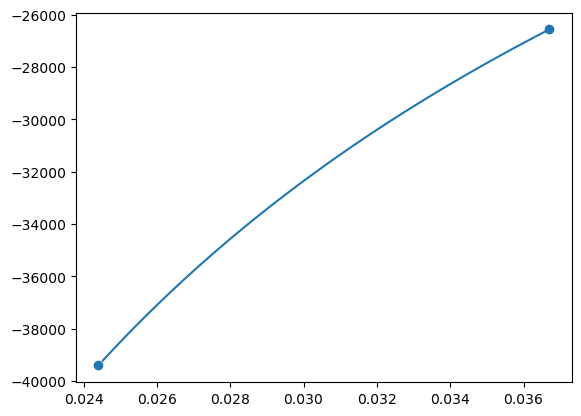

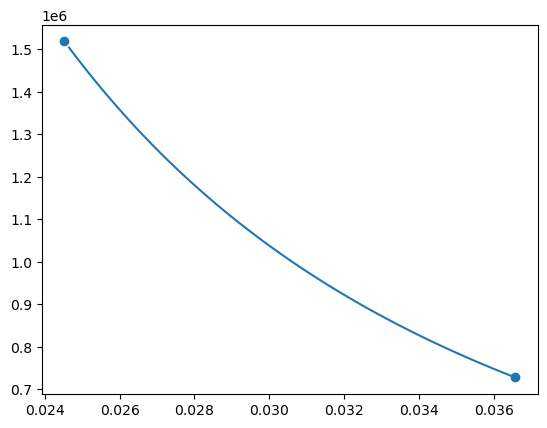

In [320]:
firstderiv = -(c[2:]-c[:-2])/(2*dr)
secondderiv = -(firstderiv[2:]-firstderiv[:-2])/(2*dr)
thirdderiv = -(secondderiv[2:]-secondderiv[:-2])/(2*dr)
plt.plot(r[1:-1],firstderiv)
plt.scatter([r[0],r[-1]], [firstderiv[0]+((secondderiv[0]+thirdderiv[0]*dr)*dr), firstderiv[-1]-((secondderiv[-1]-thirdderiv[-1]*dr)*dr)])
plt.show()
plt.plot(r[2:-2],secondderiv)
plt.scatter([r[1],r[-2]],[secondderiv[0]+thirdderiv[0]*dr,secondderiv[-1]-thirdderiv[-1]*dr])

In [85]:

print(a)
print(b)
dr = (a-b)/100
print(dr)
print(np.arange(a,b,-dr))
len(r)

0.0244
0.0367
-0.000123
[0.0244   0.024523 0.024646 0.024769 0.024892 0.025015 0.025138 0.025261
 0.025384 0.025507 0.02563  0.025753 0.025876 0.025999 0.026122 0.026245
 0.026368 0.026491 0.026614 0.026737 0.02686  0.026983 0.027106 0.027229
 0.027352 0.027475 0.027598 0.027721 0.027844 0.027967 0.02809  0.028213
 0.028336 0.028459 0.028582 0.028705 0.028828 0.028951 0.029074 0.029197
 0.02932  0.029443 0.029566 0.029689 0.029812 0.029935 0.030058 0.030181
 0.030304 0.030427 0.03055  0.030673 0.030796 0.030919 0.031042 0.031165
 0.031288 0.031411 0.031534 0.031657 0.03178  0.031903 0.032026 0.032149
 0.032272 0.032395 0.032518 0.032641 0.032764 0.032887 0.03301  0.033133
 0.033256 0.033379 0.033502 0.033625 0.033748 0.033871 0.033994 0.034117
 0.03424  0.034363 0.034486 0.034609 0.034732 0.034855 0.034978 0.035101
 0.035224 0.035347 0.03547  0.035593 0.035716 0.035839 0.035962 0.036085
 0.036208 0.036331 0.036454 0.036577 0.0367  ]


101

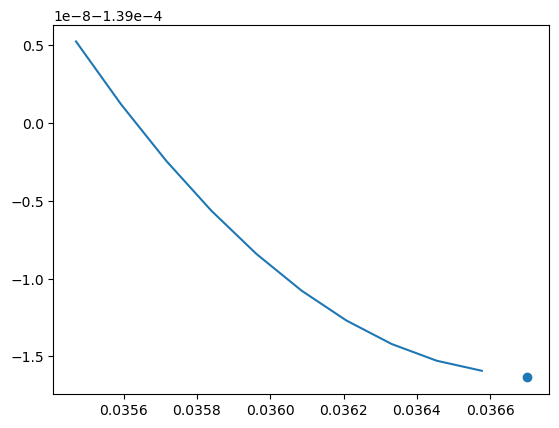

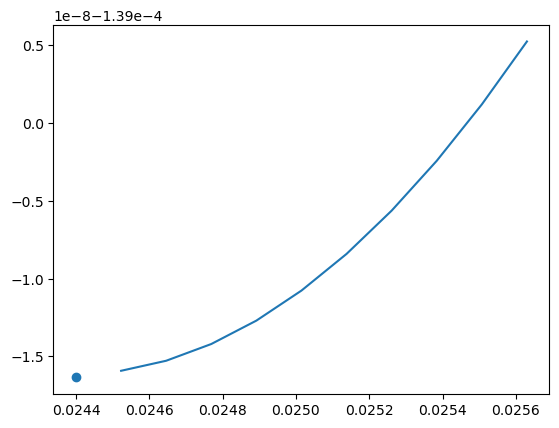

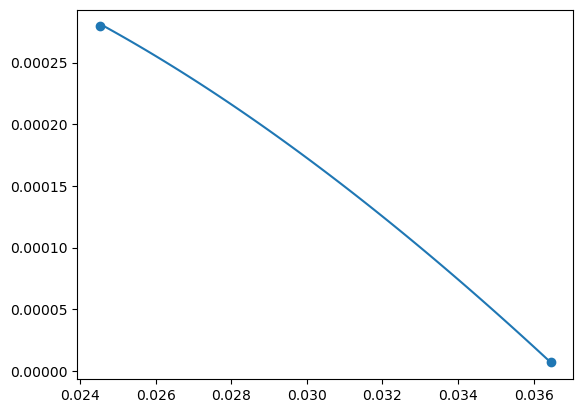

In [378]:
#newJ = (D*(firstderiv[0]-(secondderiv[0]*dr))*dt*np.pi*r[0]*2*h) + J + (D*(firstderiv[-1]-(secondderiv[-1]*dr))*dt*np.pi*r[-1]*2*h)

Jrev = J.tolist()
Jrev.reverse()

plt.plot(r[1:11],J[:10])
#plt.scatter([r[0],r[-1]], [(D*(firstderiv[0])*dt*np.pi*r[0]*2*h),(D*(firstderiv[-1])*dt*np.pi*r[-1]*2*h)])
#plt.scatter([r[0],r[-1]], [J[0]+((J[0]-J[1])-((2*J[1])-(J[0]+J[2]))/2), J[-1]+((J[-1]-J[-2])+((2*J[-2])-(J[-1]+J[-3]))/2)])
#plt.scatter([r[0],r[-1]], [J[0]+(J[0]-J[1]), J[-1]+(J[-1]-J[-2])])
plt.scatter(r[0], J[0]+((J[0]-J[1])-((2*J[1])-(J[0]+J[2]))/2))

plt.show()
plt.plot(r[-11:-1],Jrev[-10:])
plt.scatter(r[-1], Jrev[-1]+((Jrev[-1]-Jrev[-2])-((2*Jrev[-2])-(Jrev[-1]+Jrev[-3]))/2))
plt.show()

J_deriv = (J[2:]-J[:-2])/(2*dr)
plt.plot(r[2:-2], J_deriv)
plt.scatter([r[2],r[-2]],[J_deriv[0]+((J_deriv[0]-J_deriv[1])*dr), J_deriv[-1]+((J_deriv[-2]-J_deriv[-1])*dr)])

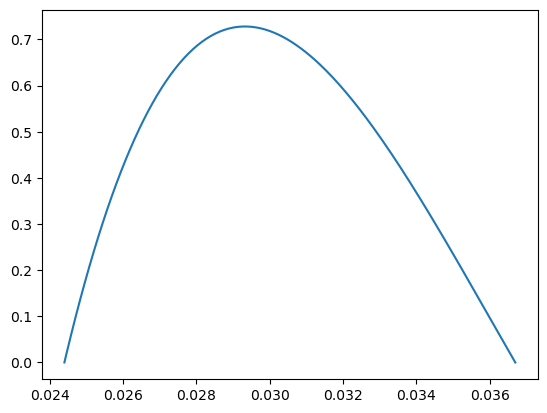

In [311]:
c_ideal = (S*ngas*Ratoms*T/(np.pi*(a**2)*h))*(np.log(r/b)/np.log(a/b)) # eqn 2.42
plt.plot(r,c-c_ideal)

In [279]:
c

array([ -0.        ,   2.55263998,   5.11387039,   7.68374132,
        10.26230339,  12.84960779,  15.44570624,  18.05065103,
        20.66449501,  23.28729162,  25.91909486,  28.55995935,
        31.20994029,  33.86909348,  36.53747536,  39.21514299,
        41.90215406,  44.5985669 ,  47.3044405 ,  50.01983452,
        52.74480927,  55.47942576,  58.22374569,  60.97783147,
        63.7417462 ,  66.51555372,  69.2993186 ,  72.09310617,
        74.89698249,  77.7110144 ,  80.53526952,  83.36981626,
        86.21472384,  89.07006227,  91.93590243,  94.81231599,
        97.69937552, 100.59715442, 103.50572699, 106.42516842,
       109.35555481, 112.29696317, 115.24947145, 118.21315857,
       121.18810438, 124.17438975, 127.17209652, 130.18130756,
       133.20210675, 136.23457904, 139.27881043, 142.33488799,
       145.40289991, 148.48293548, 151.57508513, 154.67944045,
       157.7960942 , 160.92514031, 164.06667396, 167.22079153,
       170.38759067, 173.5671703 , 176.75963064, 179.96

In [ ]:
def extract_cooling_rate(ID, T_hot=0, step = 3):
    if T_hot < 30:
        return [], []
    with open(f'NGL Watlow Heat Log/DC{ID} Watlow.txt') as lines:
        t = []
        T = []
        for line in lines.readlines():
            [lt,lT] = line.split('\t')
            t.append(float(lt))
            T.append(float(lT))
        if T_hot:
            try:
                startpoint = np.where(np.array(T)==T_hot)[0][-1]
            except:
                return [], []
        if not T_hot: 
            startpoint = -40
            T_hot = np.max(T[-startpoint:])
        DTdtquik = np.array(T)[startpoint:-1]-np.array(T)[(startpoint+1):] #test for new T
        if len(np.where(DTdtquik<0)[0]) > 0:
            endpoint = np.where(DTdtquik<0)[0][0]+len(T[:startpoint])
        else: 
            endpoint = len(np.array(T))
        cool_ind = (np.array(T[startpoint:endpoint]) < T_hot) * (np.array(T[startpoint:endpoint]) != 0)
        T_interest = np.array(T[startpoint:endpoint])[cool_ind][2:]
        t_interest = np.array(t[startpoint:endpoint])[cool_ind][2:]
        #print(T_interest)
        #print(t_interest)
        dTdt = (T_interest[step:]-T_interest[:-step])/((t_interest[step:]-t_interest[:-step]))
        Ts = (T_interest[step:]+T_interest[:-step])/2
        #print(dTdt)
        #print(Ts)
        return Ts.tolist(), dTdt.tolist()

"""def extract_cooling_rate(ID):
    with open(f'NGL Watlow Heat Log/DC{ID} Watlow.txt') as lines:
        t = []
        T = []
        for line in lines.readlines():
            [lt,lT] = line.split('\t')
            t.append(float(lt))
            T.append(float(lT))
        T_hot = np.max(T[-20:])
        cool_ind = (np.array(T[-20:]) < T_hot) * (np.array(T[-20:]) != 0)
        T_interest = np.array(T[-20:])[cool_ind]
        t_interest = np.array(t[-20:])[cool_ind]
        print(T_interest)
        print(t_interest)
        #dTdt = (T_interest[6:]-T_interest[:-6])/((t_interest[6:]-t_interest[:-6]))
        #Ts = T_interest[3:-3]
        #print(dTdt)
        #print(Ts)
        try:
            dTdt = (T_interest[-6]-T_interest[-1])/((t_interest[-6]-t_interest[-1]))
            Ts = np.mean((T_interest[-6:-1]))
        except:
            return [], []
        return [Ts], [dTdt]"""
    
T = []
dTdt = []

DIFFCELL = pd.read_csv('IrrWin0601bTube012624TC.csv').to_numpy()
metadata = DIFFCELL[:,1]
for datum in metadata:
    print(datum)
    Ti, dTdti = extract_cooling_rate((str(datum).split(' ')[1]).split('_')[0], T_hot = float((str(datum).split(' ')[1]).split('_')[2]), step = 3) 
    T = T + Ti
    dTdt = dTdt + dTdti
    if len(Ti): 
        plt.plot(Ti, dTdti, label = datum.split(' ')[1].split('_')[0]+' : '+datum.split(' ')[2])
plt.legend()
DF = pd.DataFrame()
DF['T'] = T
DF['dTdt'] = dTdt
DF.to_csv('goethiteCoolingRate.csv')

For Diffusivity of 1.6335942310411268e-07 cm^2/s and dx = 2.0, dt is set at 0.1224294235371629 seconds
[9.98175364e+02 9.85191640e+02 9.72293618e+02 9.59480174e+02
 9.46750205e+02 9.34102632e+02 9.21536394e+02 9.09050452e+02
 8.96643787e+02 8.84315397e+02 8.72064302e+02 8.59889539e+02
 8.47790161e+02 8.35765241e+02 8.23813869e+02 8.11935150e+02
 8.00128206e+02 7.88392176e+02 7.76726211e+02 7.65129481e+02
 7.53601169e+02 7.42140472e+02 7.30746601e+02 7.19418783e+02
 7.08156254e+02 6.96958268e+02 6.85824088e+02 6.74752992e+02
 6.63744269e+02 6.52797219e+02 6.41911156e+02 6.31085404e+02
 6.20319298e+02 6.09612185e+02 5.98963422e+02 5.88372375e+02
 5.77838424e+02 5.67360955e+02 5.56939366e+02 5.46573065e+02
 5.36261467e+02 5.26003999e+02 5.15800094e+02 5.05649197e+02
 4.95550760e+02 4.85504243e+02 4.75509115e+02 4.65564853e+02
 4.55670942e+02 4.45826875e+02 4.36032151e+02 4.26286279e+02
 4.16588774e+02 4.06939158e+02 3.97336961e+02 3.87781718e+02
 3.78272973e+02 3.68810275e+02 3.59393181e+

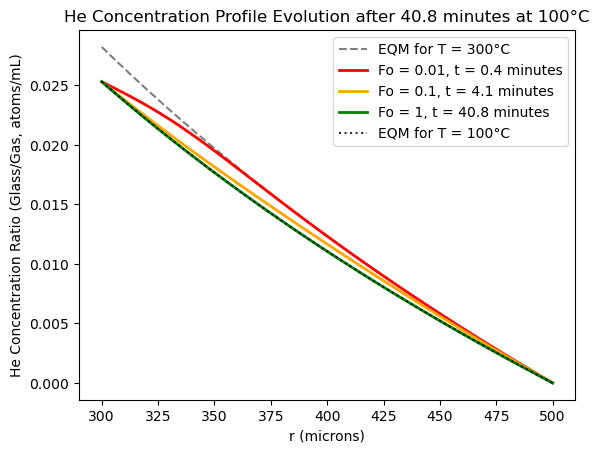

In [8]:
def tube_cylinder_FDM(T1,T2,a,b):
    """
    Simulates concentration profile with a Forward Time Centered Space 
    Finite Difference Model for diffusion
    Let T2 and T2 be temperatures in celcius that define the initial 
    EQM steady state concentration profile. If T1 is a string
    (such as 'a') then the initial concentration is 0 throughout.
    t and x are the temporal duration and spatial extent (tube thickness) of 
    the simulation respectively in seconds and cm. 
    dx is 1 micron, while dt is calculated to stabilize
    the simulation
    """
    
    Fos = [0.01,0.1,1]
    colors = ['Red', 'Orange','Green', 'Blue','Violet']
    
    D = swets('D',T2+273) 
    S2 = swets('S',T2+273)
    dr = (b-a)/100
    dt = 0.5*(dr**2)/D
    G = 2/(np.log(b/a)*(a**2))
    r = np.arange(a,b+dr,dr)
    
    
    ngas = 100
    h = 1 # arbitrary, cancels
    c2 = (S2*ngas*Ratoms*(T2+273)/(np.pi*(a**2)*h))*(np.log(r/b)/np.log(a/b))
    #c_inner = ngas*(S2*(Ratoms*(T2+273))) # inner boundary condition at new temp in terms of glass/air partitioning
    c_inner = S2*ngas*Ratoms*(T2+273)/(np.pi*(a**2)*h)
    t_stops = [] # times to stop and record concentration profile
    for Fo in Fos:
        t_stops.append((Fo*((b-a)**2))/D)
    t_stops.reverse()
    t_stop = t_stops.pop()
    
    print(f"For Diffusivity of {D} cm^2/s and dx = {round(dr*1E4,2)}, dt is set at {dt} seconds")
    
    
    if type(T1) in [int,float]:
        S1 = swets('S',T1+273)
        c1 = (S1*ngas*Ratoms*(T1+273)/(np.pi*(a**2)*h))*(np.log(r/b)/np.log(a/b))
        c = (S1*ngas*Ratoms*(T1+273)/(np.pi*(a**2)*h))*(np.log(r/b)/np.log(a/b)) # eqn 2.42
        
    else:
        c = np.zeros_like(r) # 0 initial condition throughout
        c1 = np.zeros_like(r)
        
    print(c)
    plt.plot(r*1E4, c/(ngas/(np.pi*(a**2)*h)), linestyle = '--', color = 'Black', label = f"EQM for T = {T1}°C", alpha = 0.5)
    c[0] = c_inner
    current_t = 0
    steps = 0
    firstderiv = (c[2:]-c[:-2])/(2*dr)
    delta_c = ((D*dt)) * (((c[:-2]-(2*c[1:-1])+c[2:])/(dr**2))+((1/r[1:-1])*(firstderiv)))
    print(c)
    color_count = 0
    while t_stop:
        steps += 1
        current_t += dt
        c[1:-1] += delta_c # update concentrations
        c[0] = c_inner # Enforce outer boundary condition
        c[-1] = 0 # Enforce inner boundry conditions
        firstderiv = (c[2:]-c[:-2])/(2*dr)
        delta_c = ((D*dt)) * (((c[:-2]-(2*c[1:-1])+c[2:])/(dr**2))+((1/r[1:-1])*(firstderiv)))
        if current_t >= t_stop:
            plt.plot(r*1E4, c/(ngas/(np.pi*(a**2)*h)), color = colors[color_count], linewidth = 2, label = f"Fo = {Fos[color_count]}, t = {round(current_t/60,1)} minutes")
            print(f"t = {t_stop/60}, atoms = {np.sum(c)}")
            if len(t_stops):
                t_stop = t_stops.pop()
            else:
                t_stop = 0
            color_count += 1
    print(f"Simulation finished after {steps} steps")
    print(r)
    print(c)
    print(c2)
    print(c_inner)
    plt.plot(r*1E4, c2/(ngas/(np.pi*(a**2)*h)), linestyle = ':', color = 'Black', label = f"EQM for T = {T2}°C", alpha = 0.8)
    #plt.scatter([0,xi[-1]*1E4,xi[-1]*1E4],[c[0],c[-1],c1], color = 'Black', alpha = 0.5)
    plt.xlabel('r (microns)')
    plt.ylabel('He Concentration Ratio (Glass/Gas, atoms/mL)')
    plt.title(f'He Concentration Profile Evolution after {round(current_t/60,1)} minutes at {T2}°C')
    plt.legend()
tube_cylinder_FDM(T1 = 300, T2 = 100, a = 0.03, b = 0.05)
#plt.savefig('FDM_cylinder1.jpg', dpi = 256)

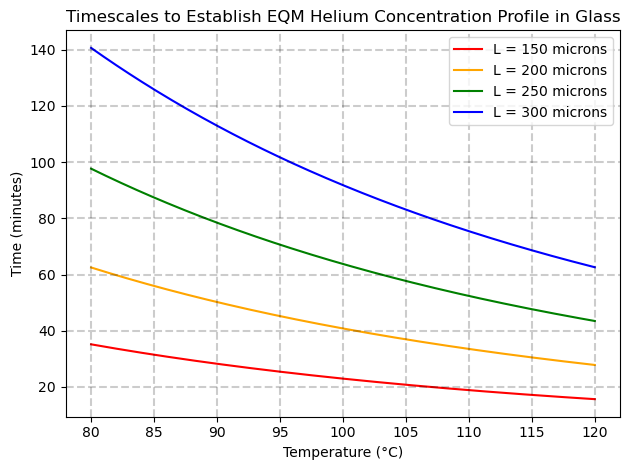

In [15]:
Ts = np.linspace(80,120,200)
Ls = np.array([0.015,0.02,0.025,0.03])
Ds = []
for T in Ts:
    Ds.append(swets('D',T+273))
Ds = np.array(Ds)
fig, ax = plt.subplots()
colors = ['Red','Orange','Green','Blue']

for j, L in enumerate(Ls):
    ts = (L**2)/(Ds)
    plt.plot(Ts, ts/60, color = colors[j], label = f'L = {int(L*1E4)} microns')
    
make_grid()
plt.title('Timescales to Establish EQM Helium Concentration Profile in Glass')
plt.xlabel('Temperature (°C)')
plt.ylabel('Time (minutes)')
plt.tight_layout()
plt.legend()
plt.savefig('EQM_timescales.jpg', dpi = 256)

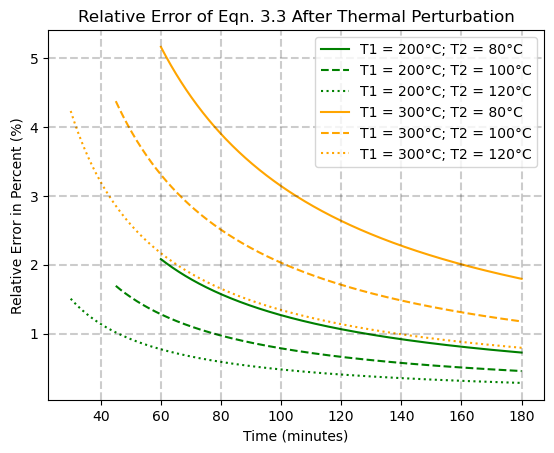

In [2]:
a = 0.03
b = 0.05
#ts = np.linspace([60,45,30][j],180,500)*60 # min to seconds
G = 2/((a**2)*(np.log(b/a)))
#D = (2*Ratoms/(a**2))*(((b**3)-(3*(a**2)*b)+(2*(a**3)))/(6*(b-a)))
H = -G*Ratoms*((0.5*(a**2)*(np.log(b/a)+0.5))-((b**2)/4))
T1s = np.array([200,300]) + 273
T2s = np.array([80,100,120]) + 273
#lam = T2*Ratoms*G*swets('K',T2)
#expterm = np.exp(-lam*ts)
fig, ax = plt.subplots()
colors = ['Green','Orange','Red']
lines = [':','--','-']
lines.reverse()
for i, T1 in enumerate(T1s):
    S1 = swets('S',T1)
    for j, T2 in enumerate(T2s):
        ts = np.linspace([60,45,30][j],180,500)*60 # min to seconds
        S2 = swets('S',T2)
        lam = T2*Ratoms*G*swets('K',T2)
        expterm = np.exp(-lam*ts)
        Err = 100*((1/((1/(H*T1*S1))+1))-(1/((1/(H*T2*S2))+1)))/(1-expterm)
        plt.plot(ts/60,Err,color=colors[i],label = f'T1 = {T1-273}°C; T2 = {T2-273}°C', linestyle = lines[j])
plt.legend()
plt.xlabel('Time (minutes)')
plt.ylabel('Relative Error in Percent (%)')
plt.title('Relative Error of Eqn. 3.3 After Thermal Perturbation')
make_grid()
plt.savefig('Thermal_Perturbation_Error.jpg',dpi = 256)

TypeError: __init__() missing 1 required positional argument: 'labels'

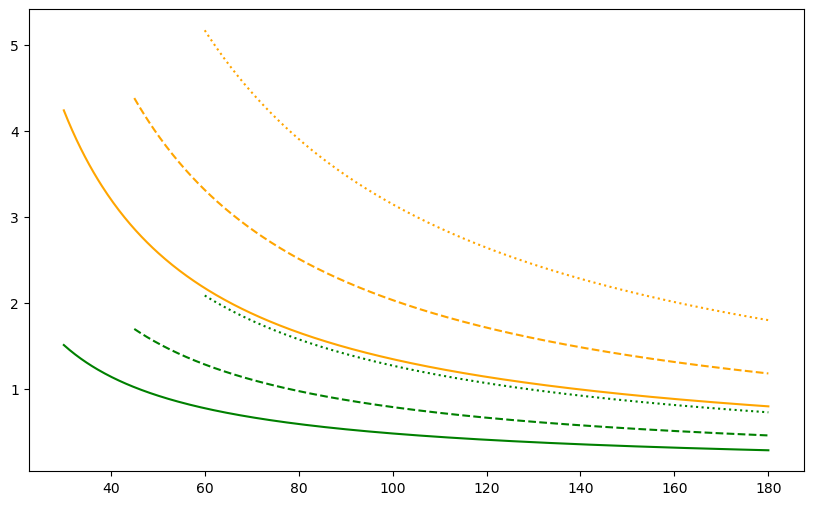

In [38]:
#chat gpt attempt to make table legend, not working

fig, ax = plt.subplots(figsize=(10, 6))
colors = ['Green', 'Orange', 'Red']
line_styles = [':', '--', '-']

# Loop over T1 and T2 to compute and plot
for i, T1 in enumerate(T1s):
    S1 = swets('S', T1)
    for j, T2 in enumerate(T2s):
        ts = np.linspace([60, 45, 30][j], 180, 500) * 60  # Convert minutes to seconds
        S2 = swets('S', T2)
        lam = T2 * Ratoms * G * swets('K', T2)
        expterm = np.exp(-lam * ts)
        Err = 100 * ((1 / ((1 / (H * T1 * S1)) + 1)) - (1 / ((1 / (H * T2 * S2)) + 1))) / (1 - expterm)
        ax.plot(ts / 60, Err, color=colors[i], linestyle=line_styles[j],
                label=f'T1 = {T1 - 273}°C; T2 = {T2 - 273}°C')

# Legend in table format
handles, labels = ax.get_legend_handles_labels()
by_row = len(T2s)  # Columns correspond to T2 values
legend_table = [handles[i:i + by_row] for i in range(0, len(handles), by_row)]
labels_table = [labels[i:i + by_row] for i in range(0, len(labels), by_row)]

# Create legend as a table
from matplotlib.legend import Legend
legend = Legend(ax, [tuple(row) for row in legend_table], loc='upper right',
                ncol=len(T2s), handletextpad=0.5, columnspacing=1.5, fontsize='small',
                title="Legend (T1 rows, T2 columns)")
ax.add_artist(legend)

# Axis labels and title
ax.set_xlabel("Time (minutes)")
ax.set_ylabel("Error (%)")
ax.set_title("Thermal Perturbation Plot")
ax.grid(True)

# Save the figure
plt.savefig('thermal_perturbation_plot.jpg', dpi=300)
plt.show()


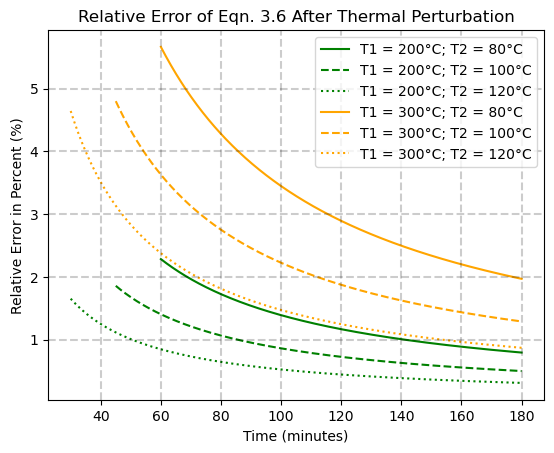

In [414]:
a = 0.03
b = 0.05
G = 2/((a**2)*(np.log(b/a)))
D = (2*Ratoms/(a**2))*(((b**3)-(3*(a**2)*b)+(2*(a**3)))/(6*(b-a)))

T1s = np.array([200,300]) + 273
T2s = np.array([80,100,120]) + 273
lam = T2*Ratoms*G*swets('K',T2)
expterm = np.exp(-lam*ts)
fig, ax = plt.subplots()
colors = ['Green','Orange','Red']
lines = [':','--','-']
lines.reverse()
for i, T1 in enumerate(T1s):
    S1 = swets('S',T1)
    for j, T2 in enumerate(T2s):
        ts = np.linspace([60,45,30][j],180,500)*60 # min to seconds
        S2 = swets('S',T2)
        lam = T2*Ratoms*G*swets('K',T2)
        expterm = np.exp(-lam*ts)
        #Err = 100*((1/((1/(D*T1*S1))+1))-(1/((1/(D*T2*S2))+1)))/(1-expterm) #Linear profile
        nglass = 100/(1+(((S*2*Ratoms*T/((a**2)*np.log(a/b))) *((0.5*a**2*(np.log(b/a)+0.5))-((b**2)/4)))**-1)) #eqn 2.46
        
        plt.plot(ts/60,Err,color=colors[i],label = f'T1 = {T1-273}°C; T2 = {T2-273}°C', linestyle = lines[j])
plt.legend()
plt.xlabel('Time (minutes)')
plt.ylabel('Relative Error in Percent (%)')
plt.title('Relative Error of Eqn. 3.6 After Thermal Perturbation')
make_grid()
plt.savefig('Thermal_Perturbation_Error.jpg',dpi = 256)

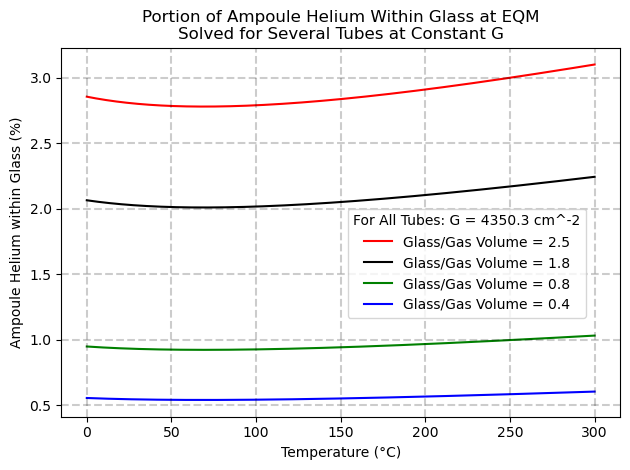

In [392]:
Ts = np.linspace(0,300,500)+273
Ss = []
for T in Ts:
    Ss.append(swets('S',T))
Ss = np.array(Ss)

colors = ['Red', 'Black', 'Green', 'Blue','Violet']

a = 0.03
b = 0.05
G = 2/((a**2)*(np.log(b/a)))
aa = np.array([0.027,0.03,0.04,0.05])
bb = aa*np.exp(2/(G*(aa**2)))
Vglass_Vgas = ((bb**2)-(aa**2))/(aa**2)

Ds = (2*Ratoms/(aa**2))*(((bb**3)-(3*(aa**2)*bb)+(2*(aa**3)))/(6*(bb-aa)))
fig, ax = plt.subplots()
for i, D in enumerate(Ds):
    plt.plot(Ts-273,100*(1/((1/(D*Ts*Ss))+1)), color = colors[i], label =f"Glass/Gas Volume = {round(Vglass_Vgas[i],1)}")
    
plt.legend(title=f'For All Tubes: G = {round(G,1)} cm^-2', loc='best', bbox_to_anchor=(0.5, 0.25))    
plt.xlabel('Temperature (°C)')
plt.ylabel('Ampoule Helium within Glass (%)') 
plt.title('Portion of Ampoule Helium Within Glass at EQM\nSolved for Several Tubes at Constant G')
make_grid()
plt.tight_layout()
plt.savefig('PercentHeInGlass.jpg', dpi = 256)

In [333]:
a = 0.03
b = 0.05
G = 2/((a**2)*(np.log(b/a)))
D = (2*Ratoms/(a**2))*(((b**3)-(3*(a**2)*b)+(2*(a**3)))/(6*(b-a)))
T1s = np.array([200,300]) + 273
T2s = np.array([80,100,120]) + 273
lam = T2*Ratoms*G*swets('K',T2)
expterm = np.exp(-lam*ts)
fig, ax = plt.subplots()
colors = ['Green','Orange','Red']
lines = [':','--','-']
lines.reverse()
for i, T1 in enumerate(T1s):
    S1 = swets('S',T1)
    for j, T2 in enumerate(T2s):
        ts = np.linspace([60,45,30][j],180,500)*60 # min to seconds
        S2 = swets('S',T2)
        lam = T2*Ratoms*G*swets('K',T2)
        expterm = np.exp(-lam*ts)
        Err = 100*((1/((1/(D*T1*S1))+1))-(1/((1/(D*T2*S2))+1)))/(1-expterm)
        plt.plot(ts/60,Err,color=colors[i],label = f'T1 = {T1-273}°C; T2 = {T2-273}°C', linestyle = lines[j])
plt.legend()
plt.xlabel('Time (minutes)')
plt.ylabel('Relative Error in Percent (%)')
plt.title('Relative Error of Eqn. 3.6 After Thermal Perturbation')
make_grid()
plt.savefig('Thermal_Perturbation_Error.jpg',dpi = 256)

1.1104928207158329

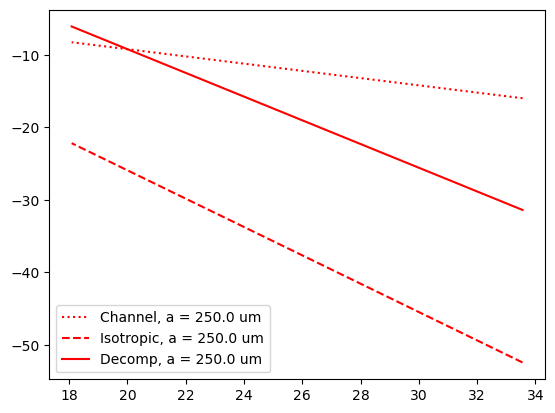

In [526]:
#Demo Arrhenius Plots for size comparison
DiffPar = {
'Channel':(13.4E-4,0.43*96485),
'Isotropic':(327.7,162556),
'Decomp':(10000000,136000)#(17375,148950.4)
}
R = 8.314
lines = [':','--','-']
colors = ['Red','Green','Blue']
A = [0.025]
Tr = np.array([25,280])+273

for j, (name, (D0,Ea)) in enumerate(DiffPar.items()):
    for i, a in enumerate(A):
        plt.plot(1E4/Tr, np.log((D0/(a**2))*np.exp(-Ea/(R*Tr))), color = colors[i], linestyle = lines[j], label = f'{name}, a = {a*1E4} um')
plt.legend()

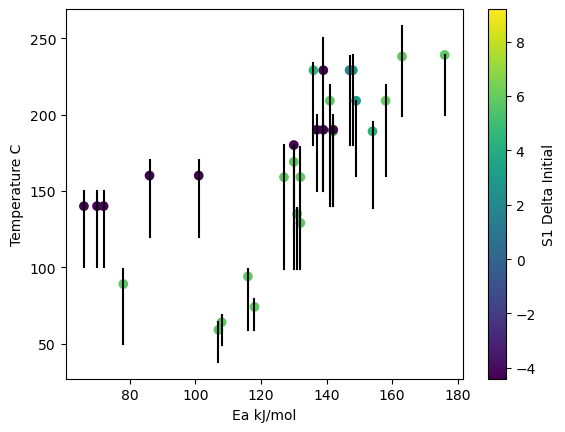

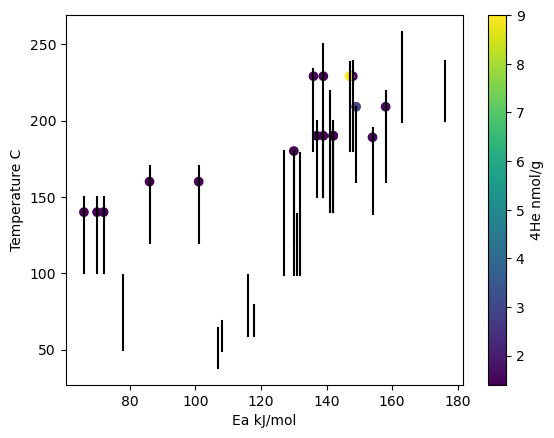

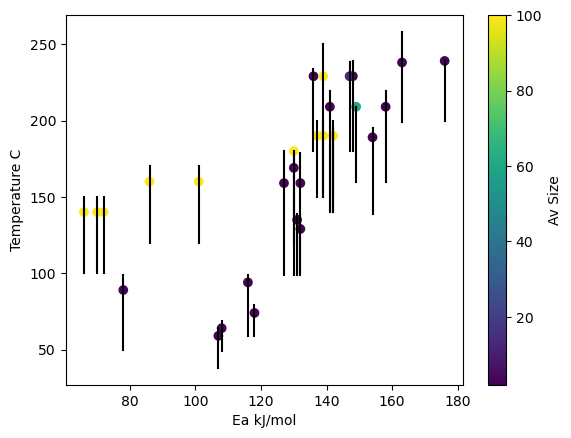

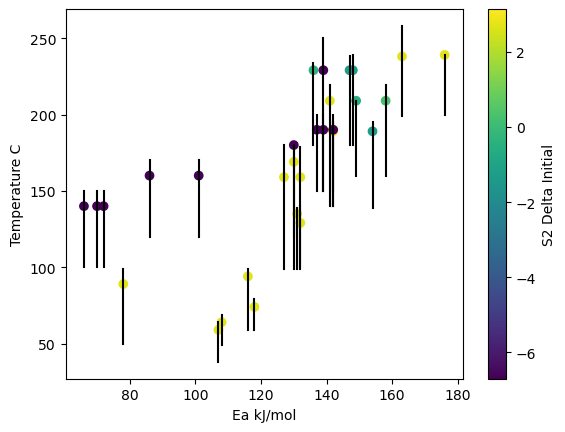

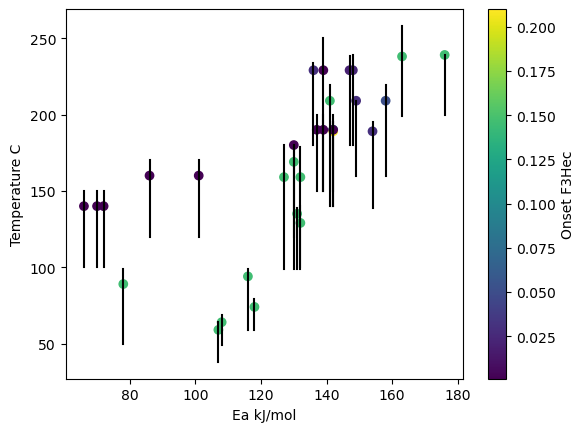

In [469]:
gtEa = pd.read_csv('farley24dat.csv')
Tstart = gtEa['Tstart']
Tmin = gtEa['Tmin']
Tend = gtEa['Tend']
Eas = gtEa['Ea (kJ/mol)']


param = 'S1 Delta Initial'


plt.scatter(Eas, Tstart,c = gtEa[param])
for i, Ea in enumerate(Eas):
    plt.plot([Ea,Ea],[Tmin[i],Tend[i]], color = 'Black')
cbar = plt.colorbar()
cbar.set_label(param)
plt.xlabel('Ea kJ/mol')
plt.ylabel('Temperature C')
plt.show()

param = '4He nmol/g'

plt.scatter(Eas, Tstart,c = gtEa[param])
for i, Ea in enumerate(Eas):
    plt.plot([Ea,Ea],[Tmin[i],Tend[i]], color = 'Black')
cbar = plt.colorbar()
cbar.set_label(param)
plt.xlabel('Ea kJ/mol')
plt.ylabel('Temperature C')
plt.show()

param = 'Av Size'

plt.scatter(Eas, Tstart,c = gtEa[param])
for i, Ea in enumerate(Eas):
    plt.plot([Ea,Ea],[Tmin[i],Tend[i]], color = 'Black')
cbar = plt.colorbar()
cbar.set_label(param)
plt.xlabel('Ea kJ/mol')
plt.ylabel('Temperature C')
plt.show()

param = 'S2 Delta Initial'

plt.scatter(Eas, Tstart,c = gtEa[param])
for i, Ea in enumerate(Eas):
    plt.plot([Ea,Ea],[Tmin[i],Tend[i]], color = 'Black')
cbar = plt.colorbar()
cbar.set_label(param)
plt.xlabel('Ea kJ/mol')
plt.ylabel('Temperature C')
plt.show()

param = 'Onset F3Hec'

plt.scatter(Eas, Tstart,c = gtEa[param])
for i, Ea in enumerate(Eas):
    plt.plot([Ea,Ea],[Tmin[i],Tend[i]], color = 'Black')
cbar = plt.colorbar()
cbar.set_label(param)
plt.xlabel('Ea kJ/mol')
plt.ylabel('Temperature C')
plt.show()

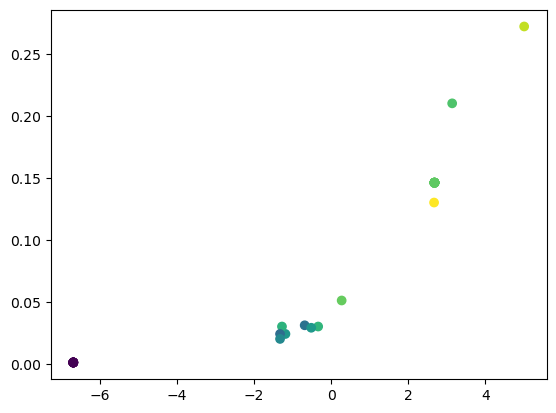

In [478]:
plt.scatter(gtEa['S2 Delta Initial'],gtEa['Onset F3Hec'], c = gtEa['S1 Delta Initial'])#(1/gtEa['4He nmol/g'])*(gtEa['Av Size']))

In [15]:
def tube_permeate2(T, t, ID, OD):
    """Lengths in cm. Inner and outer diameter. F is fraction initial He remaining. 
    Returns n/n0, fraction of initial Helium"""
    K = swets_K(T)
    return(np.exp(-(K*Ratoms*T*2*t)/(np.log(OD/ID)*((ID/2)**2))))

tube_permeate2(70+273,4*24*3600,ID = 0.054, OD=0.0832)

0.00930777451993813

In [16]:
(swets('D', 293))

2.0911506080861696e-08

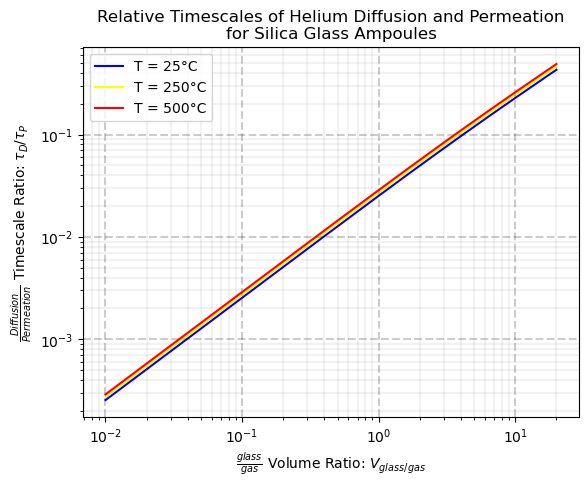

In [41]:
Ts = np.array([25,250,500])+273
colors = ['blue', 'yellow', 'red']
VR = np.linspace(0.01,20,200)
VP = (VR + 1)**0.5
fig, ax = plt.subplots()
for i, T in enumerate(Ts):
    #D = swets('D', T)
    S = swets('S', T)
    #K = swets('K', T)
    #tauP = 1/(G*Ratoms*K*T)
    #tauD = ((b-a)**2)/D
    tauR = S*Ratoms*T*VR*((-1+VP)/(1+VP))*(2/np.log(VP))
    plt.loglog(VR, tauR, label = f'T = {T-273}°C', color = colors[i], zorder = 1+i)
plt.legend()
plt.xlabel(r'$\frac{glass}{gas}$ Volume Ratio: $V_{glass/gas}$')
plt.ylabel(r'$\frac{Diffusion}{Permeation}$ Timescale Ratio: $\tau_D/\tau_P$')
plt.title('Relative Timescales of Helium Diffusion and Permeation\nfor Silica Glass Ampoules')
make_grid()
plt.savefig('VRvsRtau.jpg', dpi = 256)